# PZT atomiser final analysis

The PZT calibration is 5.35 micrometres/pixel with pulse separation
25 microseconds: instantaneous pixel displacements are converted once by
0.214 m/s. This calibration supersedes both 5.05 and 7.25.
Cartesian x/u is horizontal/transverse; y/v is vertical/axial.
Naming changes do not transpose, rotate or reflect the field. The exported
image-reference origin and existing station indices/frame keys are retained.

Mean and instantaneous axial contours, including the station map, display
all finite signed measurements. Blue is negative, white is zero and red is
positive. Symmetric limits and one linear normalization are used, with
uniformly spaced contour levels and no separate stretching of signs. Each
mean component uses its own maximum absolute ensemble value, excluding flag
diagnostics. Selected instantaneous fields share limits. Only missing or
invalid data are masked. Values are recalculated from the original displacement
samples; sample selection, station indices, averaging and orientation are retained.


In [1]:
from pathlib import Path
import sys,json
root=Path.cwd().resolve()
while not (root/'RAW_data').exists():
    if root==root.parent: raise RuntimeError('Workspace root not found')
    root=root.parent
sys.path.insert(0,str(root))
config_path=root/'PZT_Atomiser_Analysis/config/analysis.json'
config=json.loads(config_path.read_text())
from math import isclose
assert isclose(config['velocity_scale'],config['confirmed_spatial_calibration_um_per_pixel']*1e-6/config['confirmed_pulse_separation_seconds'])
print(json.dumps(config,indent=2))


{
  "conditions": [
    {
      "id": "Batch4_Cam1",
      "path": "RAW_data/Batch4_Cam1.h5"
    }
  ],
  "analysis_status": "final",
  "components": [
    "us",
    "vs"
  ],
  "confirmed_spatial_calibration_um_per_pixel": 5.35,
  "confirmed_pulse_separation_seconds": 2.5e-05,
  "conditional_displacement_to_velocity_m_per_s_per_pixel": 0.214,
  "calibration_source": "User-confirmed 5.35 micrometres/pixel supersedes 5.05 and 7.25; pulse separation remains 25 microseconds",
  "confirmed_physical_convention": {
    "u": "horizontal/transverse, rightwards positive",
    "v": "vertical/axial, upwards positive",
    "x": "horizontal/rightwards",
    "y": "vertical/upwards"
  },
  "conditional_image_displacement_mapping": {
    "u_m_s": "+0.214 us",
    "v_m_s": "+0.214 vs"
  },
  "coordinate_scale": 0.00535,
  "coordinate_unit": "mm",
  "velocity_scale": 0.214,
  "velocity_unit": "m/s",
  "component_mapping": [
    [
      1,
      0
    ],
    [
      0,
      1
    ]
  ],
  "coordinate_ma

In [2]:
from PZT_Atomiser_Analysis.analysis.pipeline import run
results=run(config_path)
output=root/config['output']


Recalculating from original HDF5 at 5.35 micrometres/pixel.


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


Saved 51 figures; {"mean_axial_velocity_measured_range_m_s": [-0.023111475754425344, 1.6865481421305646], "mean_axial_contour_colour_limits_m_s": [-1.6865481421305646, 1.6865481421305646], "negative_mean_axial_nodes": 14345, "figure_count": 51, "publication_figure_count": 37, "diagnostic_figure_count": 14, "local_N_range": [1757, 1757], "selected_frame_keys": ["1", "879", "1757"], "observed_grid_node_maximum": {"row": 304, "column": 42, "x_mm": 14.54665, "y_mm": 1.284, "N": 1757, "mean_v_m_s": 1.6865481421305646}}


# PZT atomiser methods

Coordinates are Cartesian: $x$ is horizontal/rightward and $y$ vertical/upward; $u$ is transverse and $v$ axial. The in-plane vector is $\mathbf{w}=(u,v)$; primes denote fluctuations about the respective means.

Calibration is 5.35 micrometres/pixel (0.00535 mm/pixel), superseding both 5.05 and 7.25 for
this PZT experiment only. Pulse separation is 25 microseconds. The adopted
export convention is us/vs as horizontal/vertical pixel displacements per
pair, with retained signs: u=0.214 us and v=0.214 vs (m/s). The original HDF5
is opened read-only, converted once at the instantaneous-sample stage, then
all statistics are calculated. Naming is changed without transposing,
rotating or reflecting arrays. The exported (0,0) image reference remains
the spatial origin; it is not an established atomiser outlet centre.

The finite-pair population requires both components finite. No numeric flag
code is rejected or assigned a physical validity meaning. RMS, variance and
covariance use denominator N. Undefined correlation and fewer-than-two-pair
statistics are masked. No derivative, jet-width or similarity analysis is
added. Upstream replacement is not inferred. No additional spatial smoothing,
gap filling or extrapolation is applied.

All finite signed axial measurements are displayed, including negative values. Only missing or invalid data are masked. Blue denotes negative velocity, white zero and red positive velocity. Normalization is linear with symmetric limits and uniformly spaced contour levels; positive and negative ranges are not stretched separately. This presentation applies to mean and instantaneous axial
contours, the station-location map and flag-specific mean-axial diagnostics.
Profiles, PDFs/CDFs, quivers and numerical arrays also retain signed values.
All component velocities, covariance and correlation use signed colour scales.
Each mean component has symmetric limits set by its own maximum absolute
ensemble value; flag diagnostics are excluded. Comparable instantaneous maps
share symmetric limits from the selected frames. A single linear normalization
maps the symmetric negative/positive range to blue-white-red, with near-zero
velocities near white. No separate stretching of signs is applied. All contour
levels are uniformly spaced, with zero included exactly for signed fields.
Only cells touching genuinely
missing or invalid nodes are omitted (corner_mask=False); finite negative
measurements do not produce artificial cutouts.

Magnitude of the mean vector is sqrt(mean(u)^2+mean(v)^2). Mean instantaneous
in-plane velocity magnitude is mean(sqrt(u^2+v^2)); the definitions are distinct.
Mean component contours are primary; magnitude quantities are supplementary.
Native station indices and three field keys are preserved. Profiles use the
same native rows without interpolation; PDFs are separate native-node histogram
densities with unit integral and CDFs are exact empirical staircases. No frame
independence, turbulence or absolute-uncertainty claim is made.

Grid spacings are 0.3424 mm horizontally and 0.0856 mm vertically; these describe
vector spacing, not interrogation-window size or effective resolution.

Regenerate from the PZT_droplets workspace root:
    .\.venv\Scripts\python -m PZT_Atomiser_Analysis.analysis.pipeline --config PZT_Atomiser_Analysis/config/analysis.json


## Primary mean-component contours

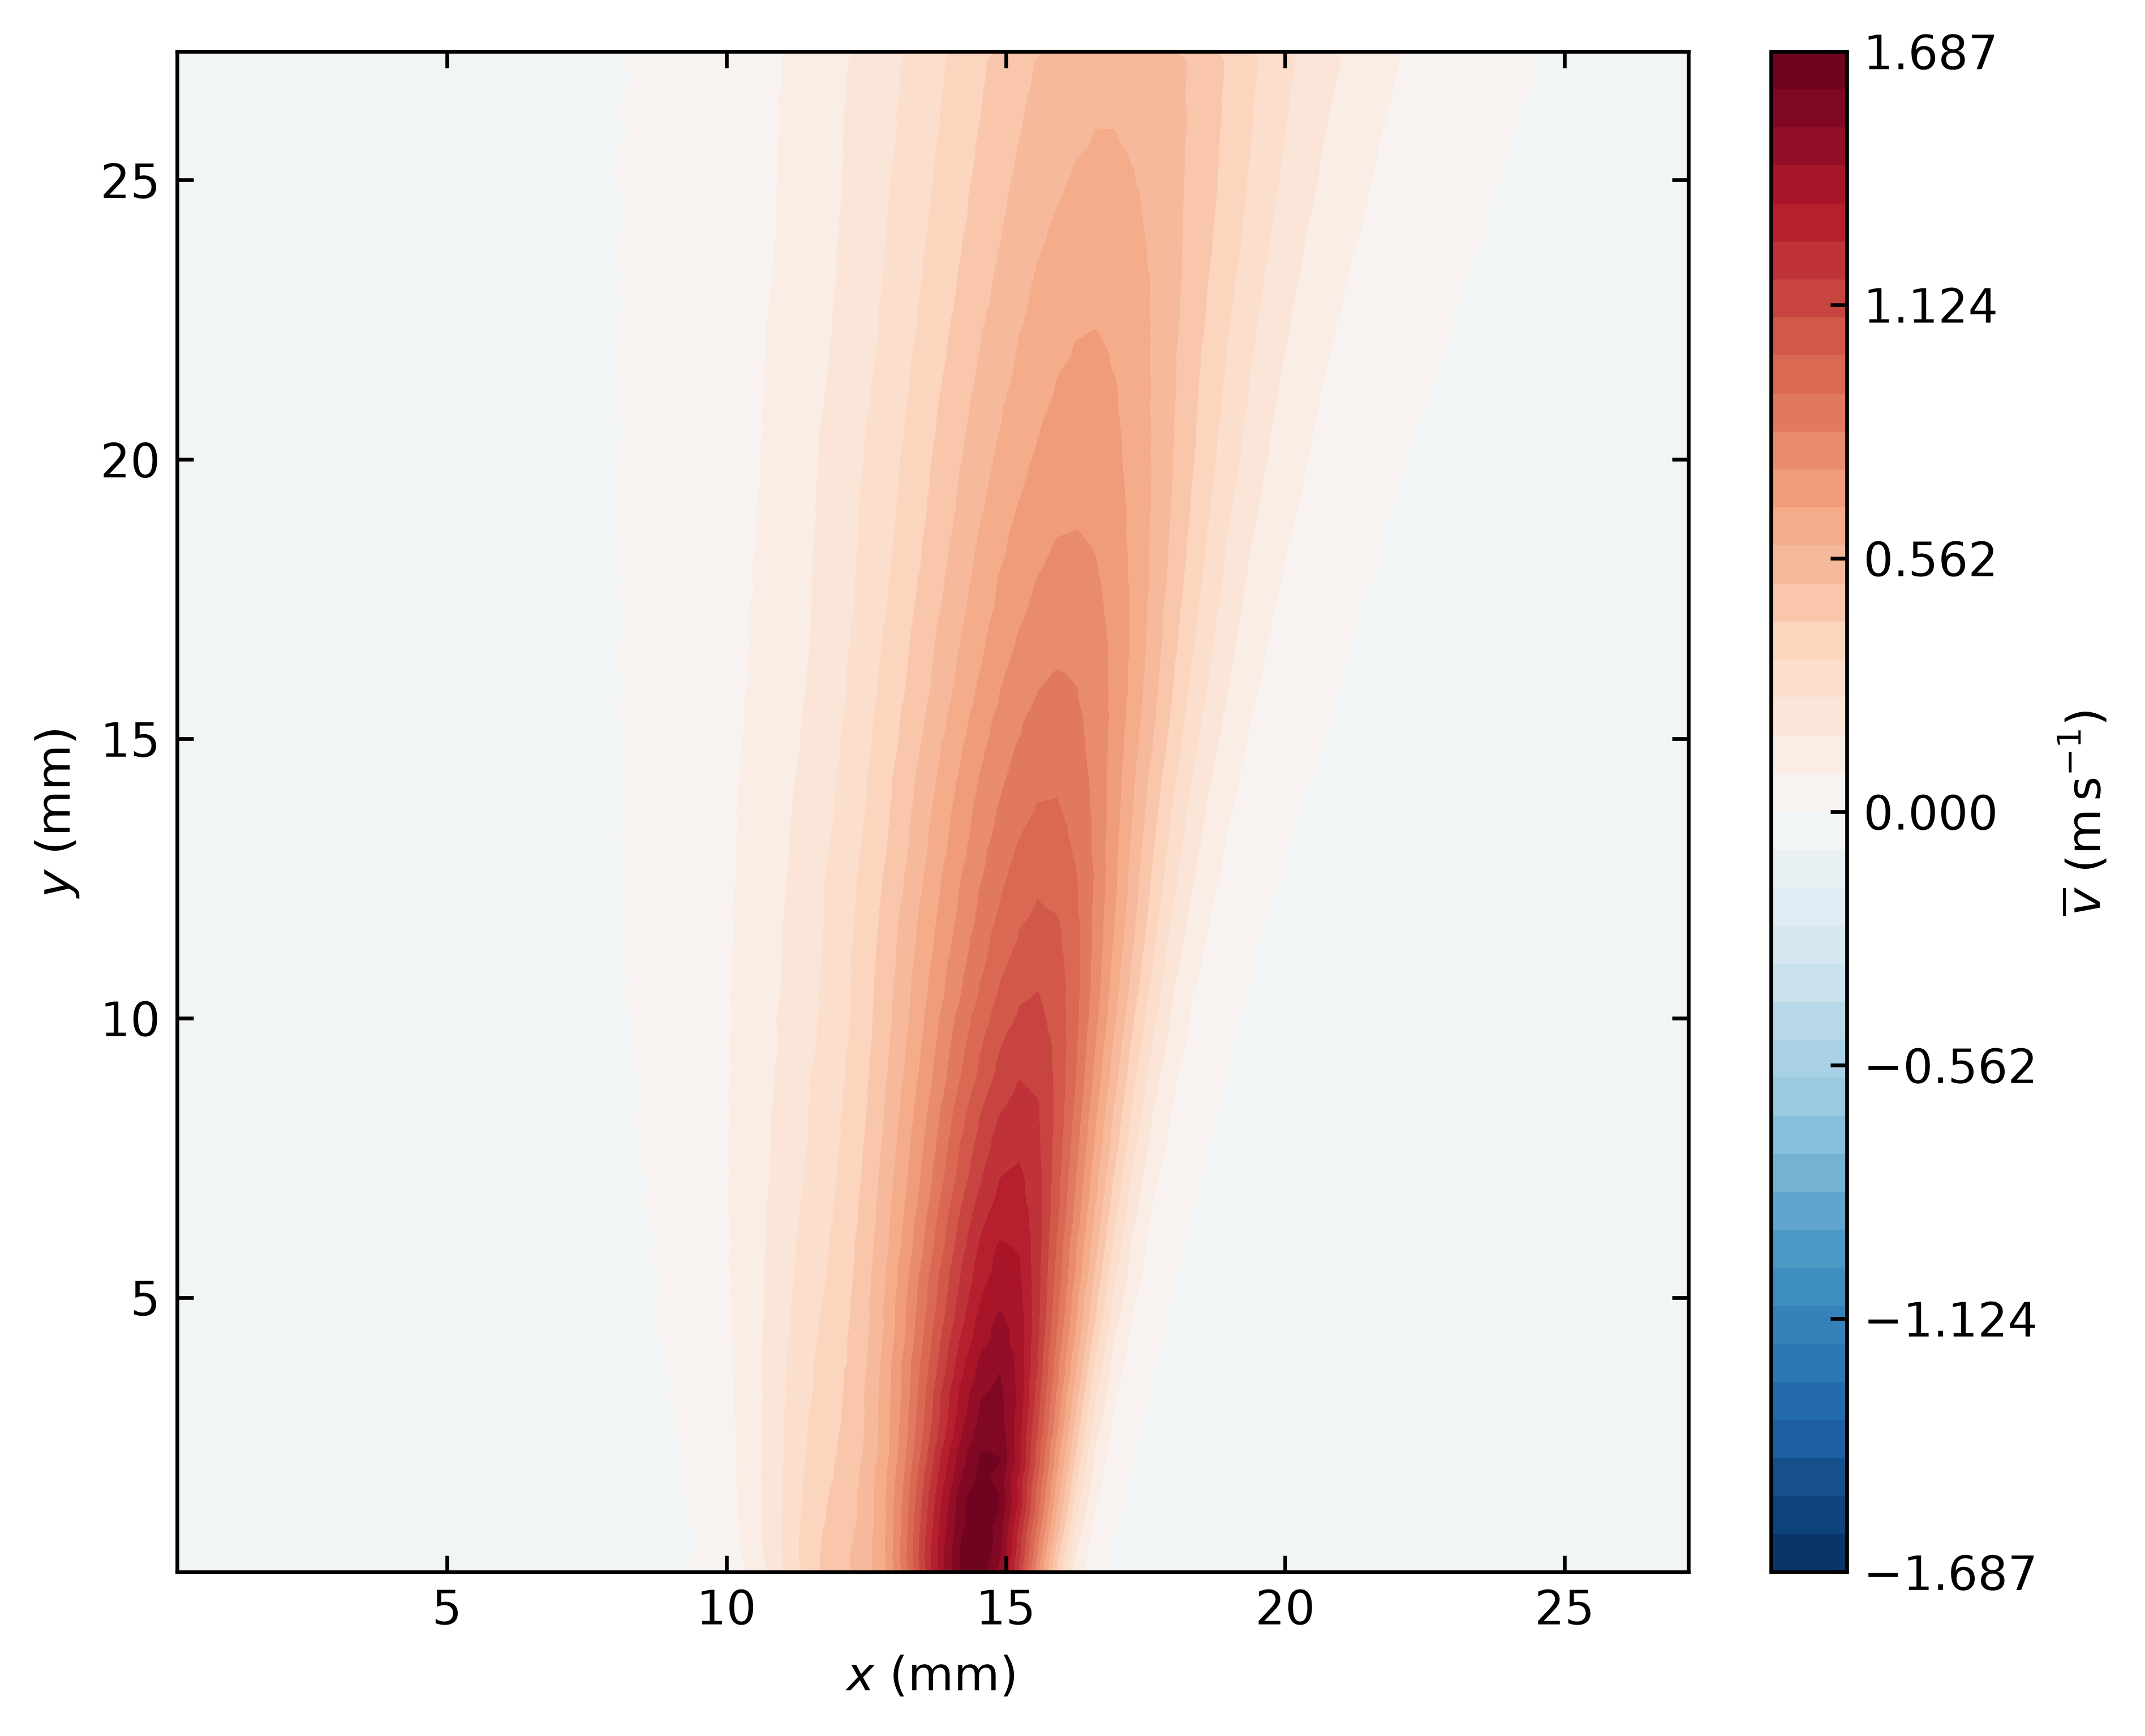

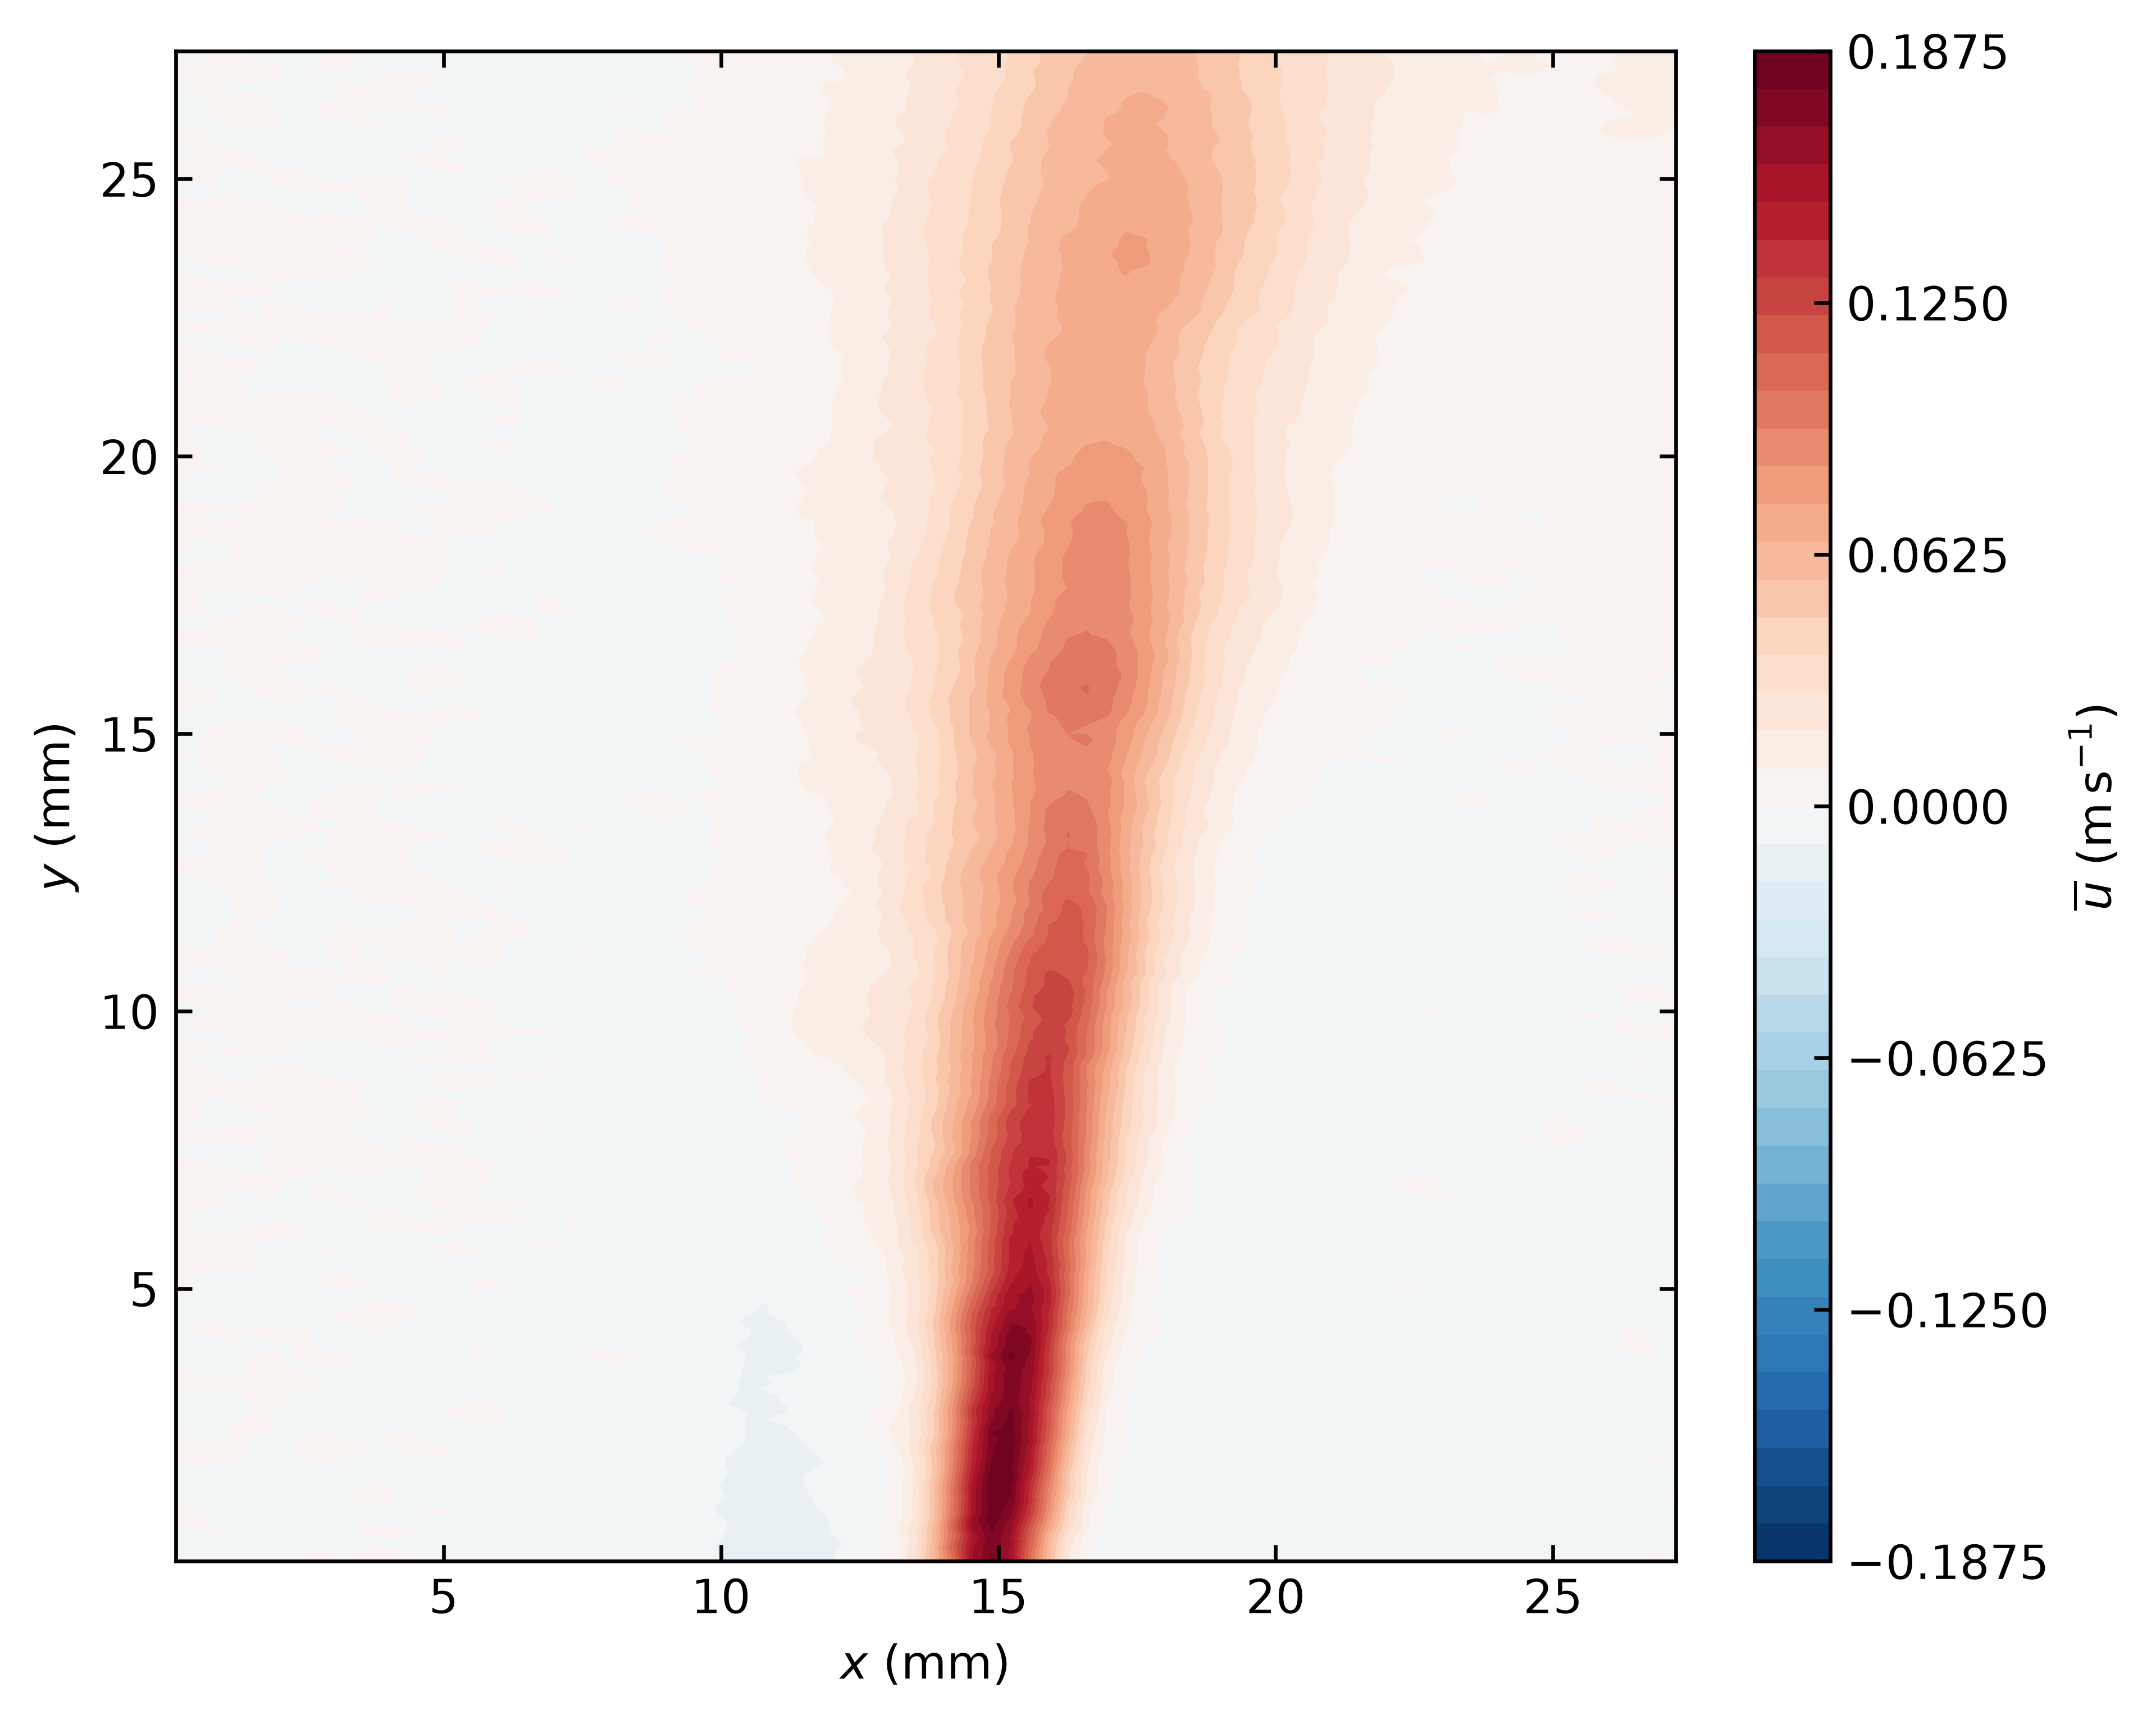

## Component fluctuations, profiles and distributions

rms_v


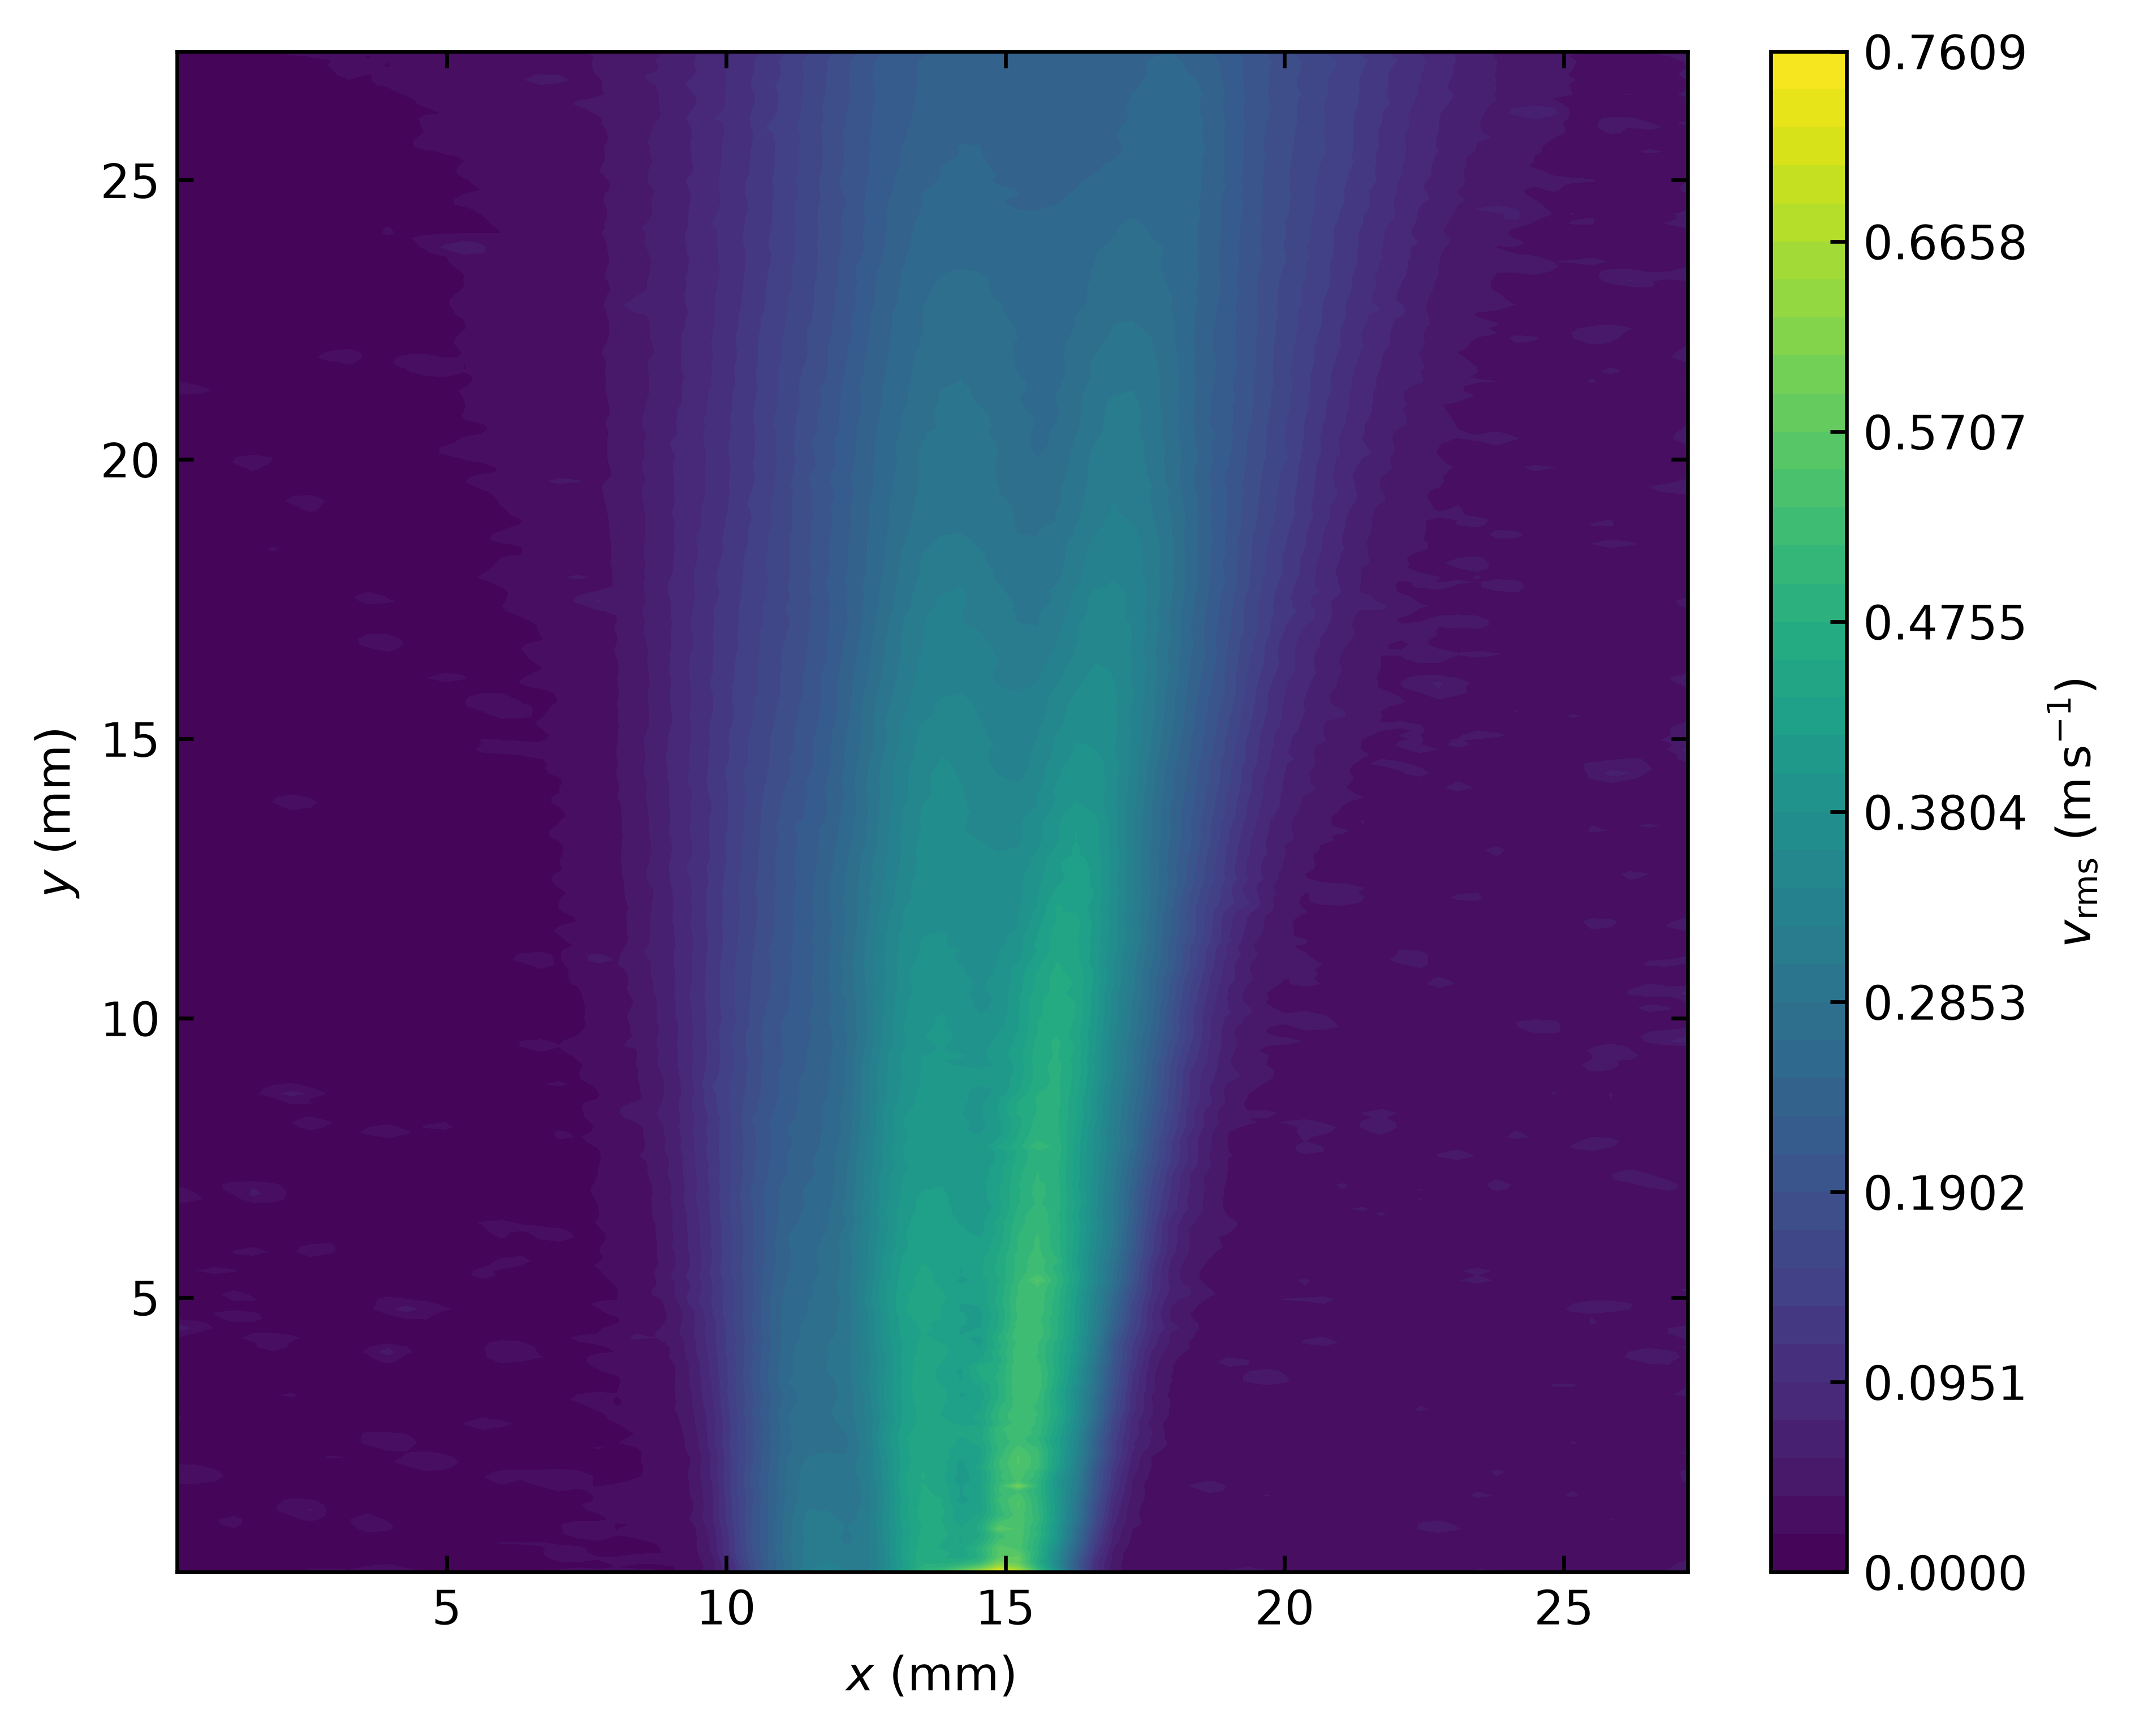

rms_u


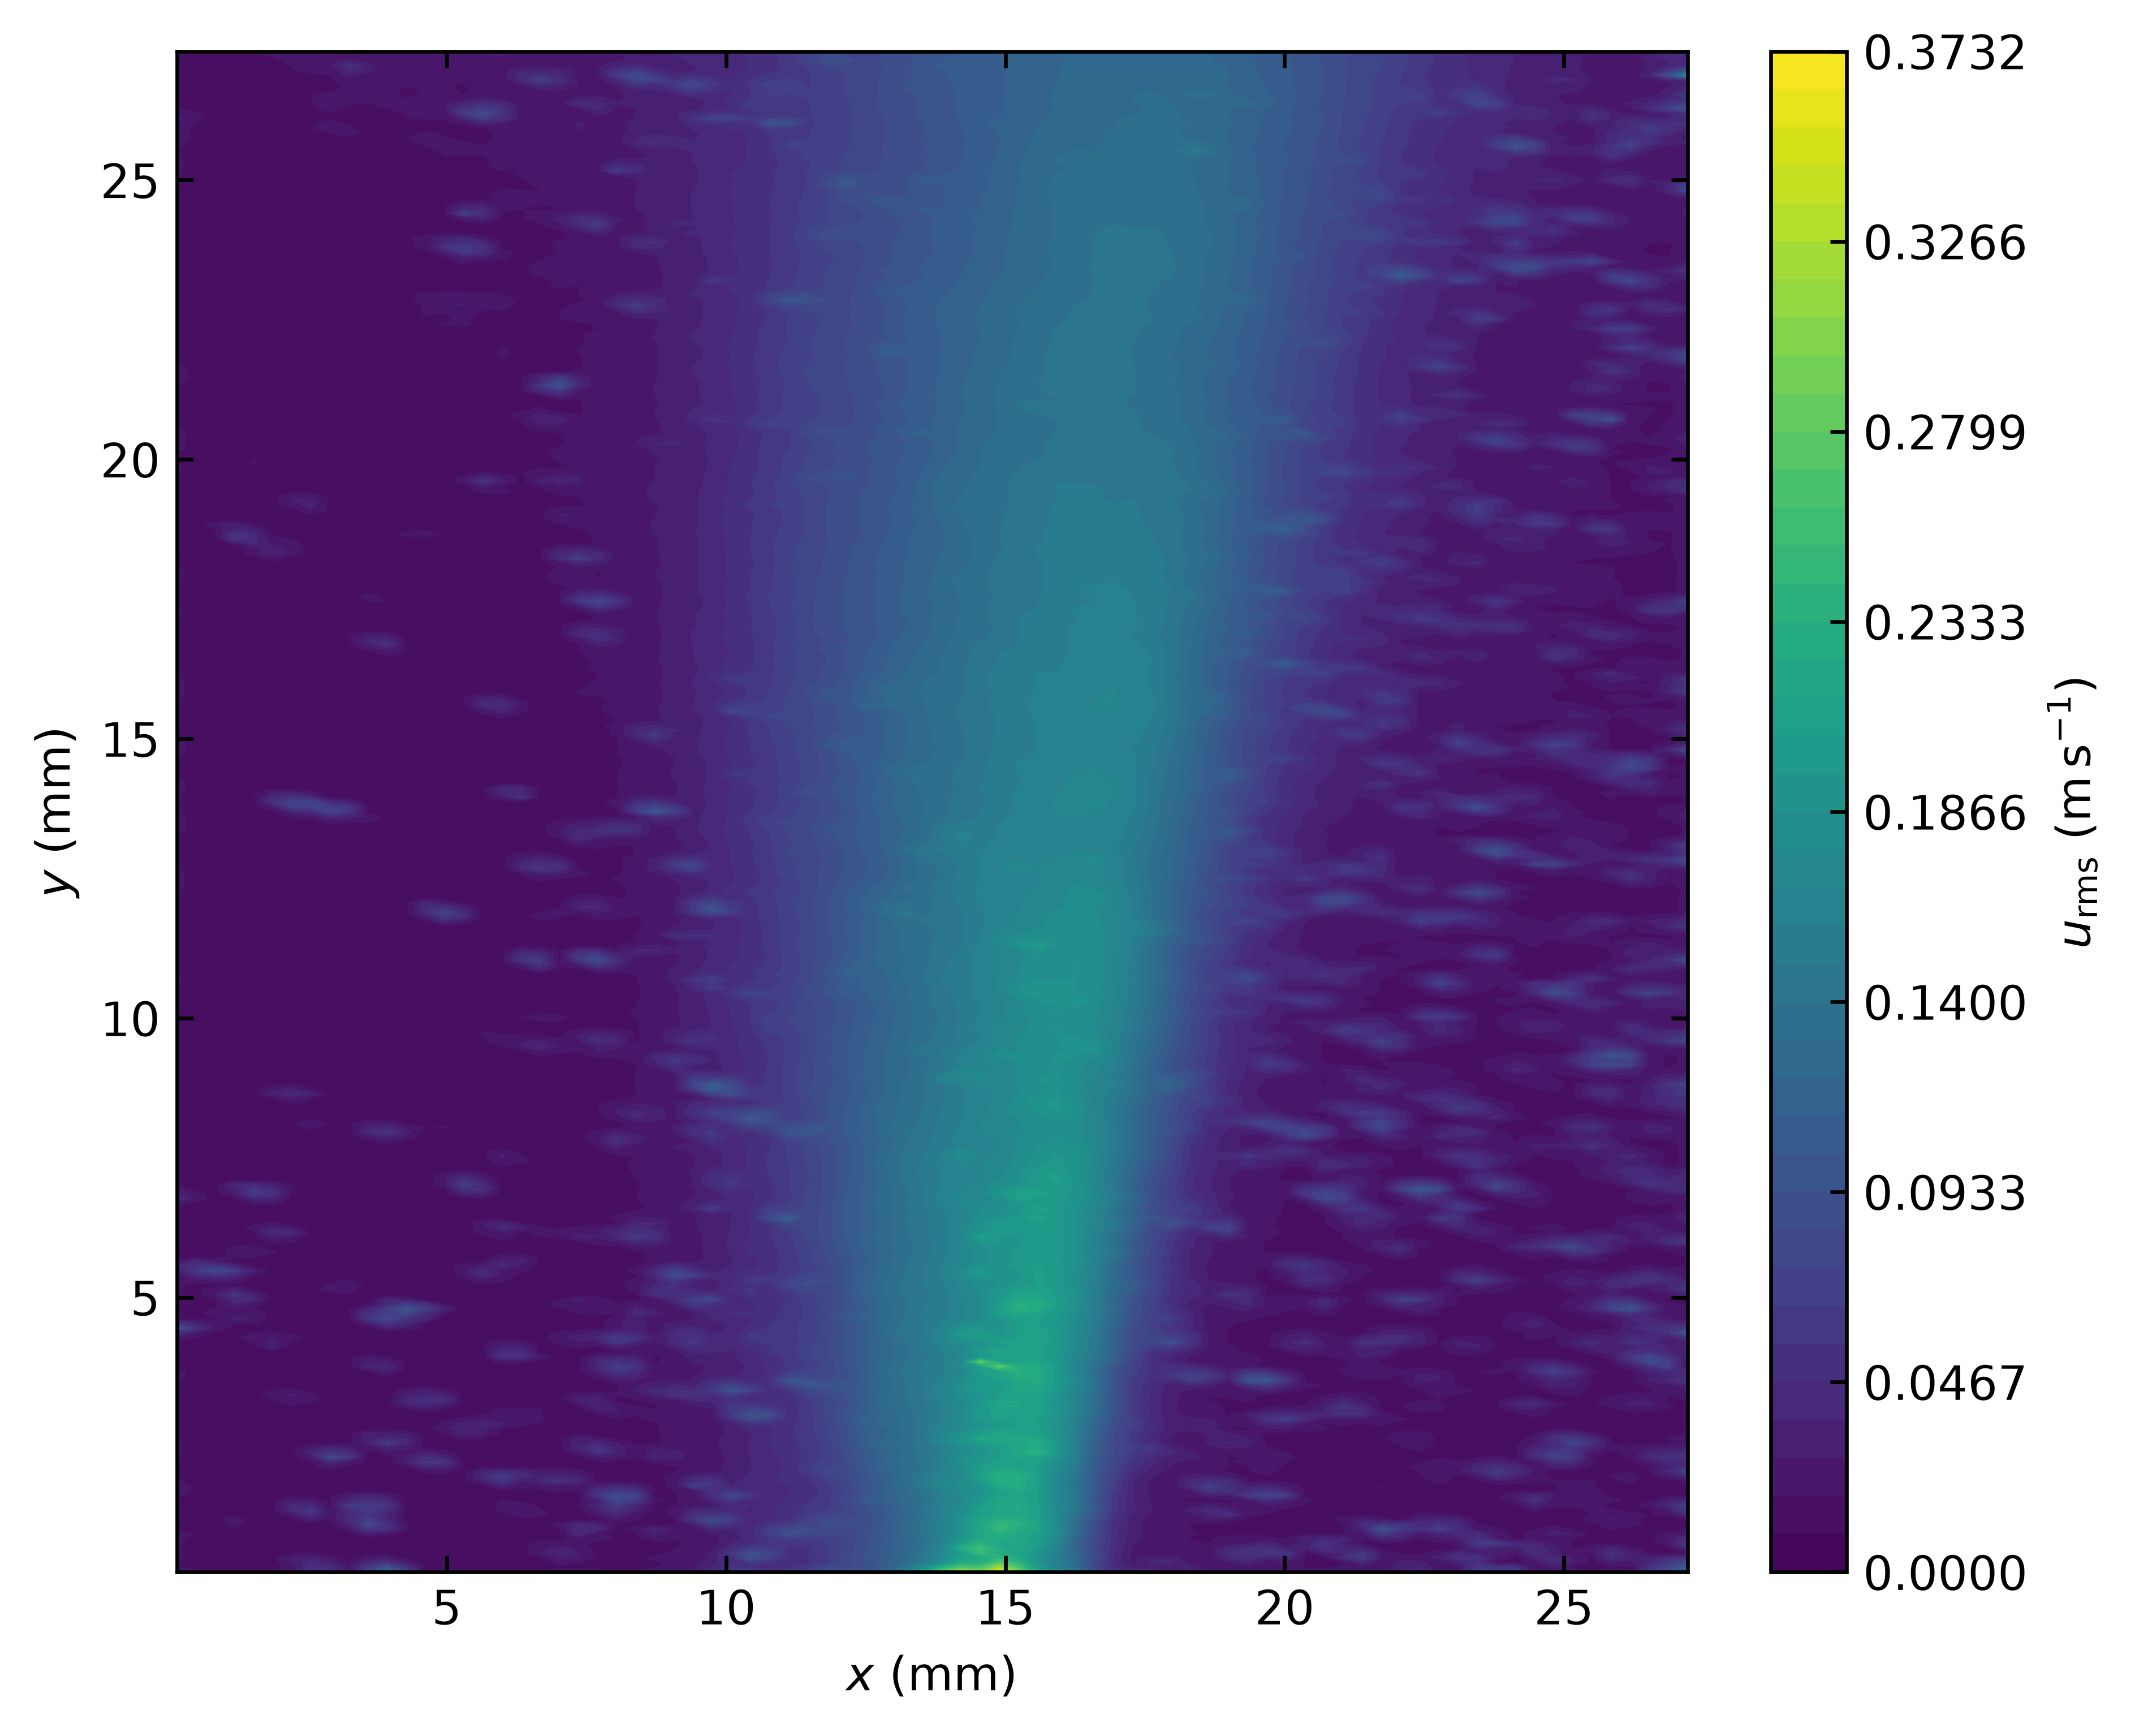

covariance


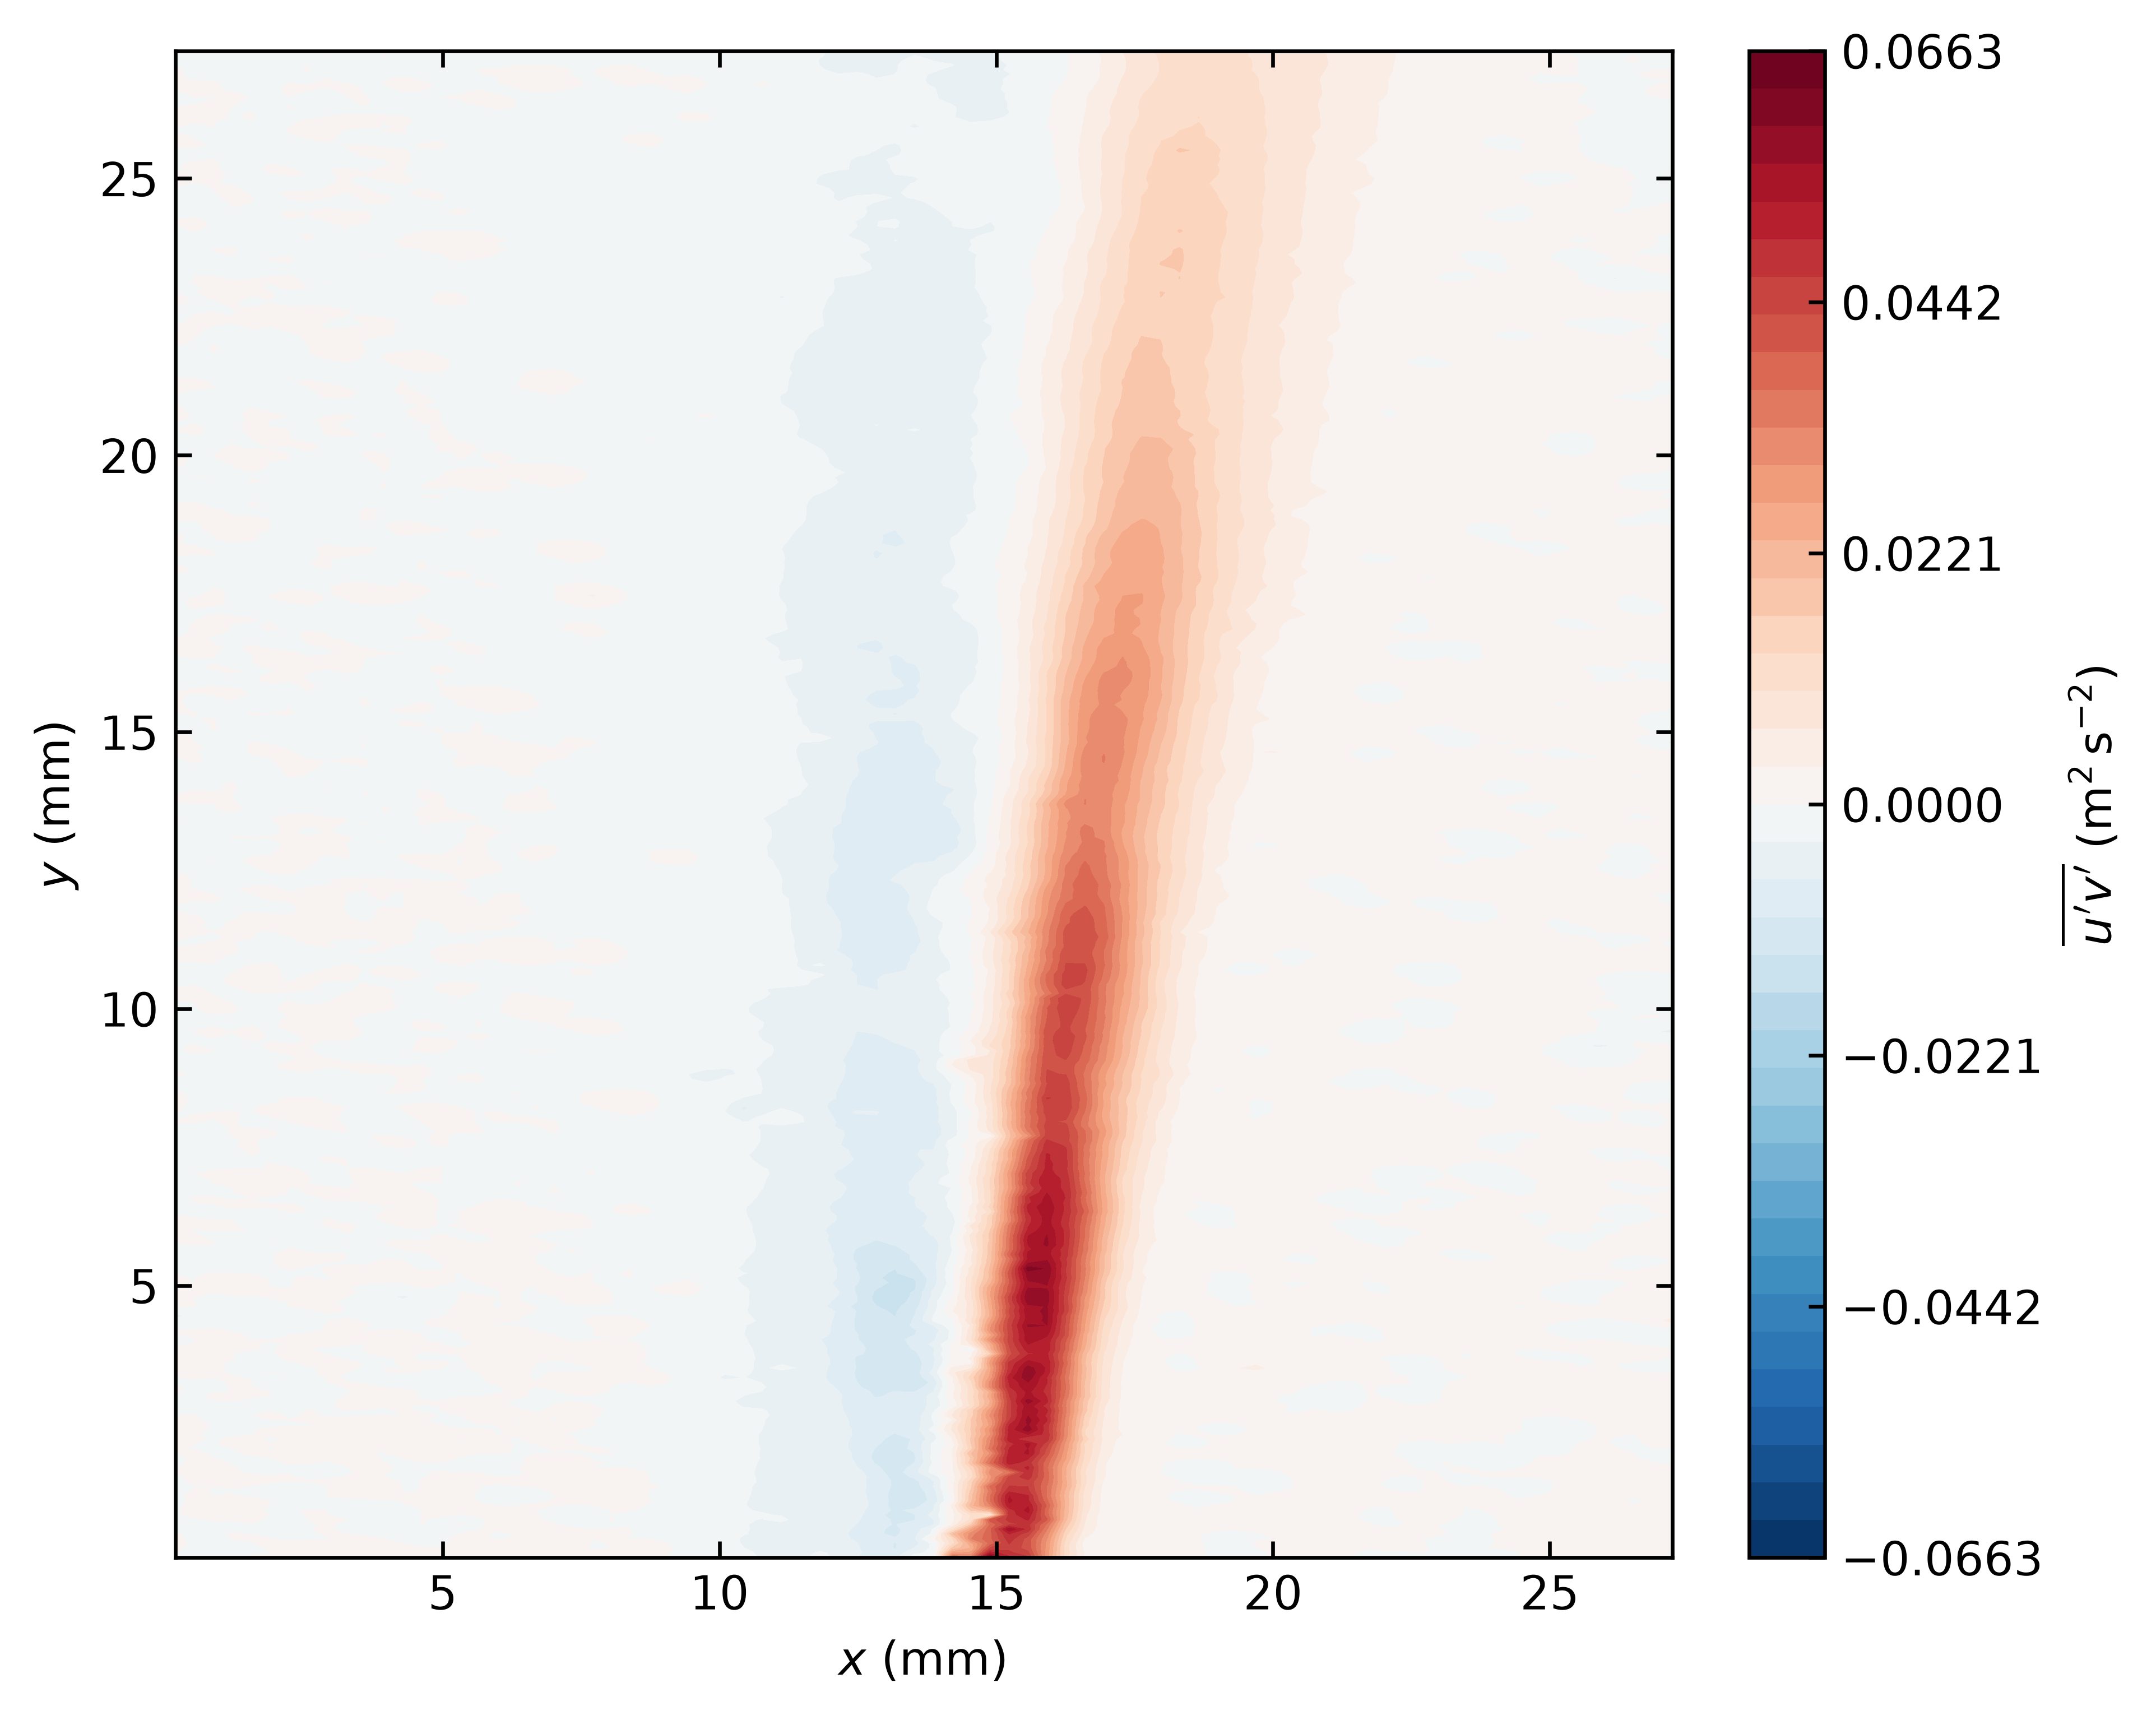

correlation


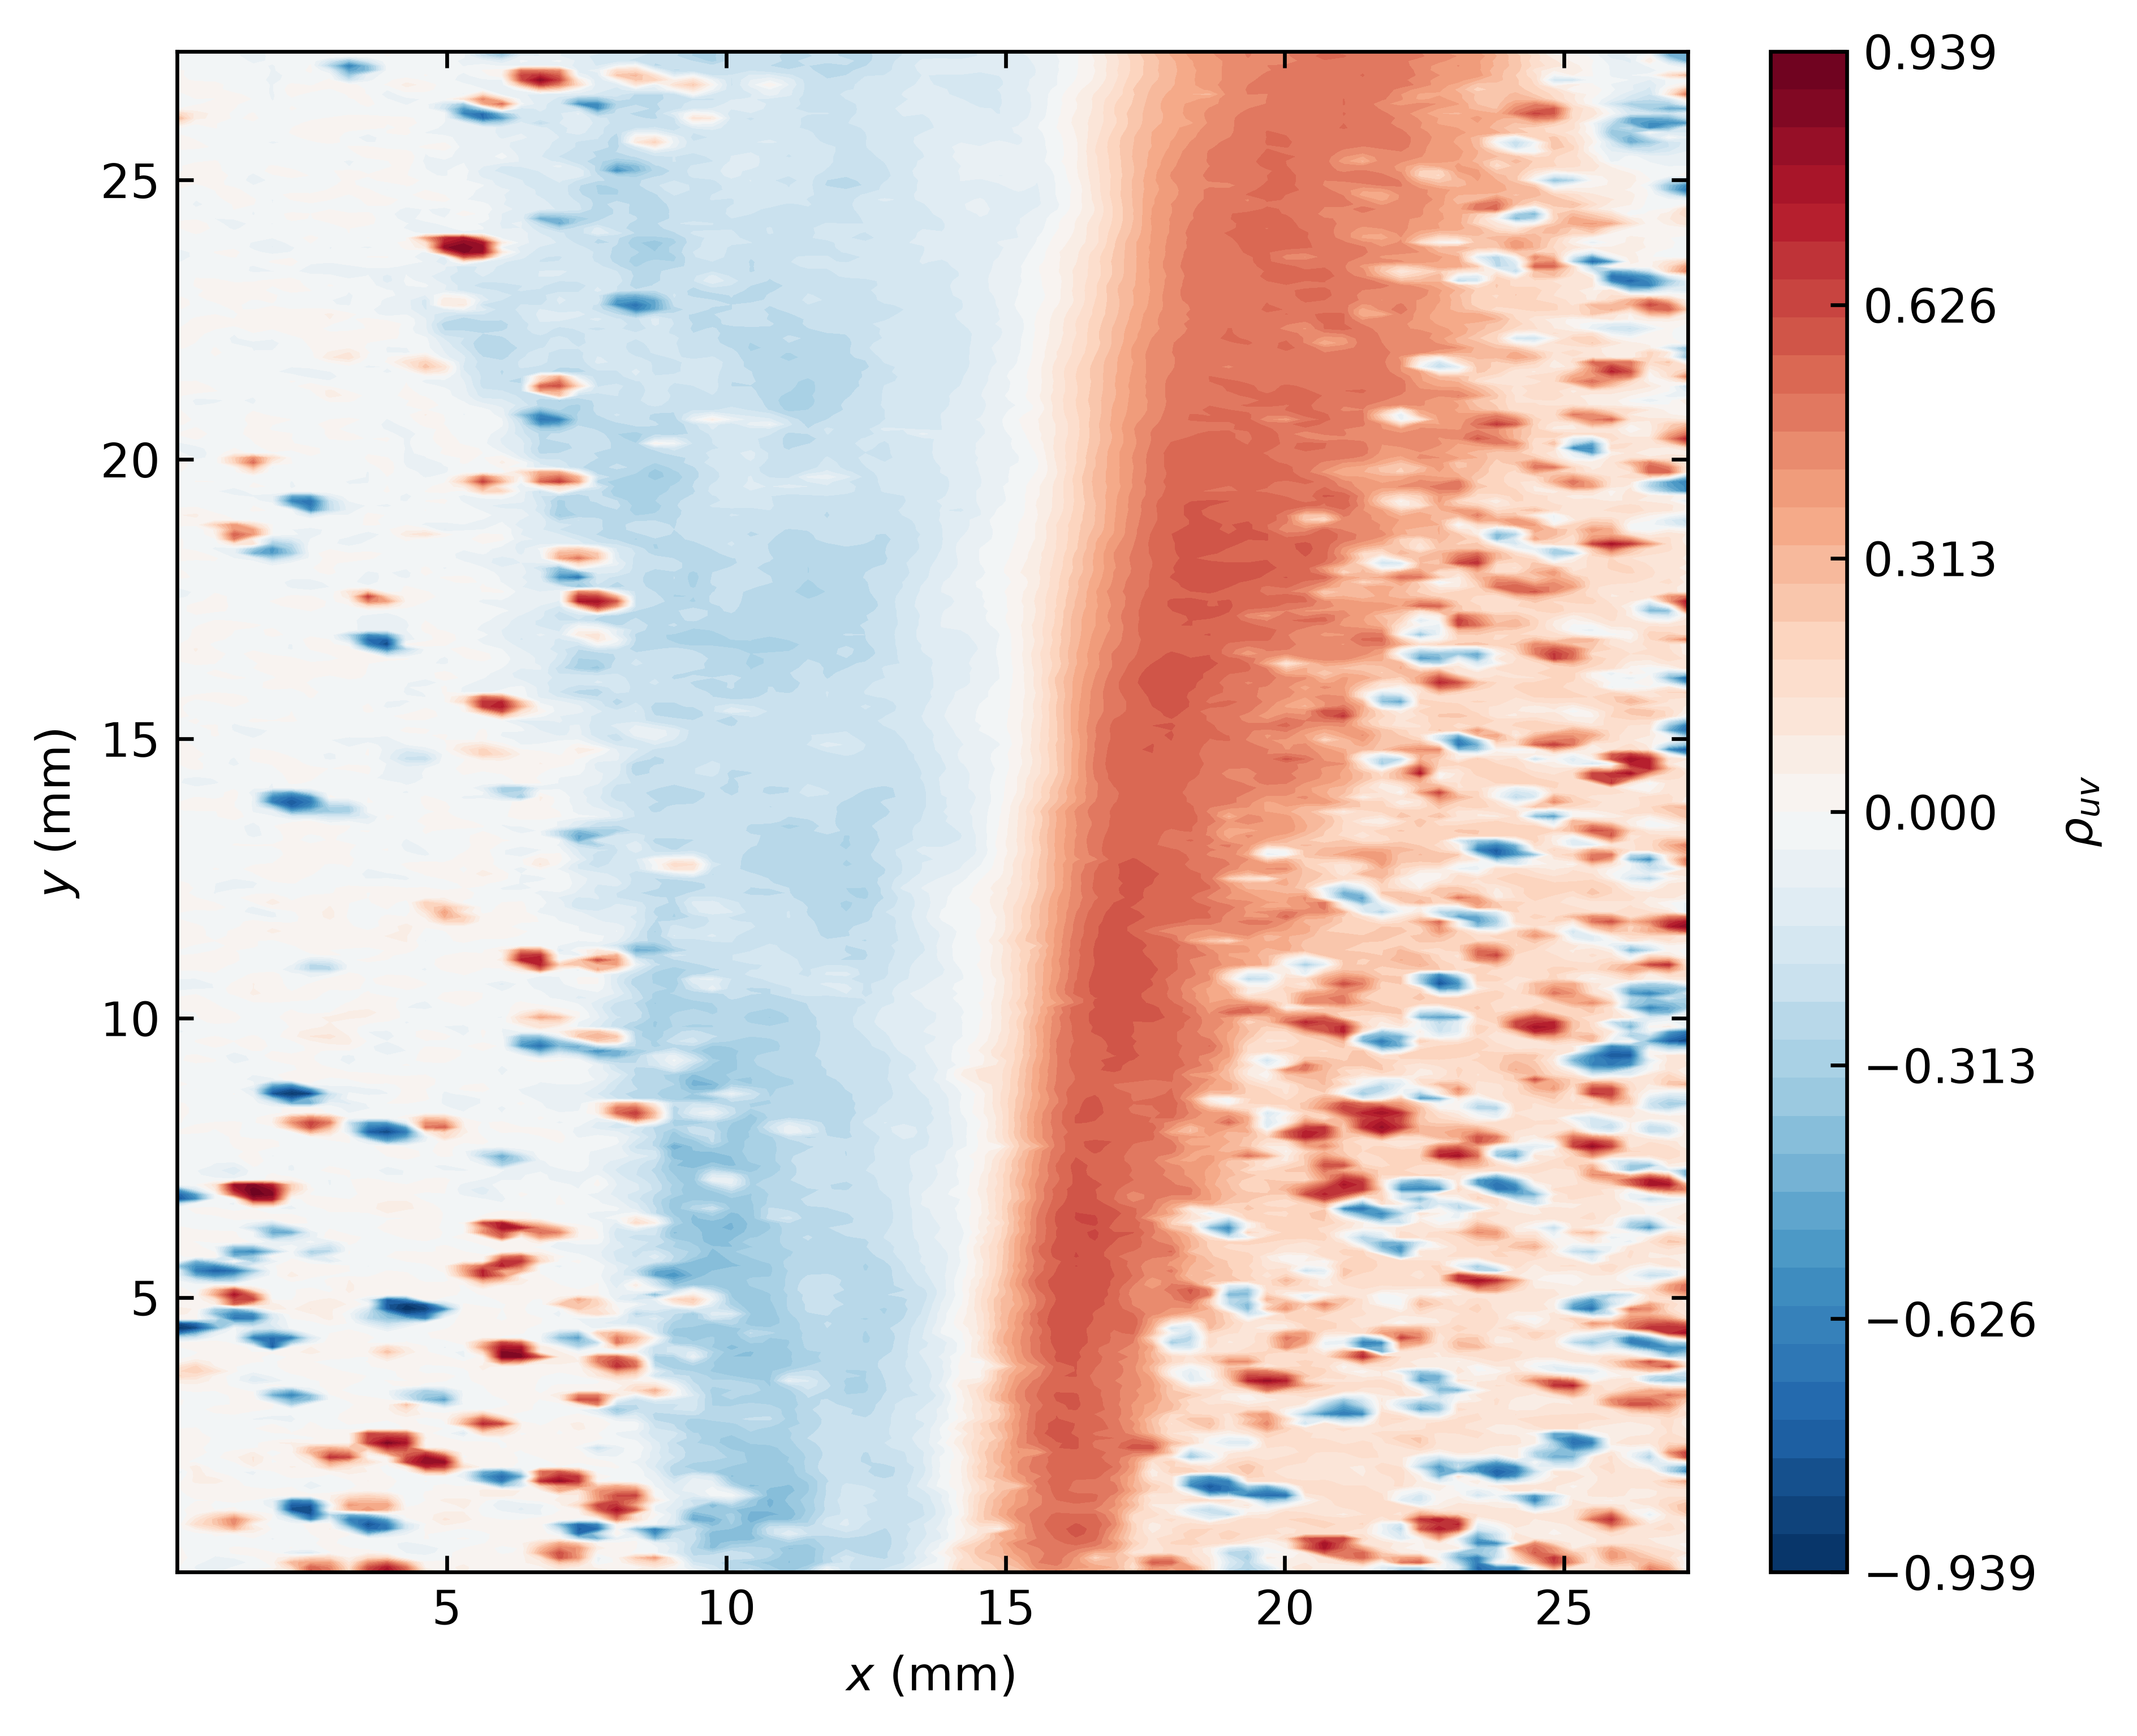

sampling_stations


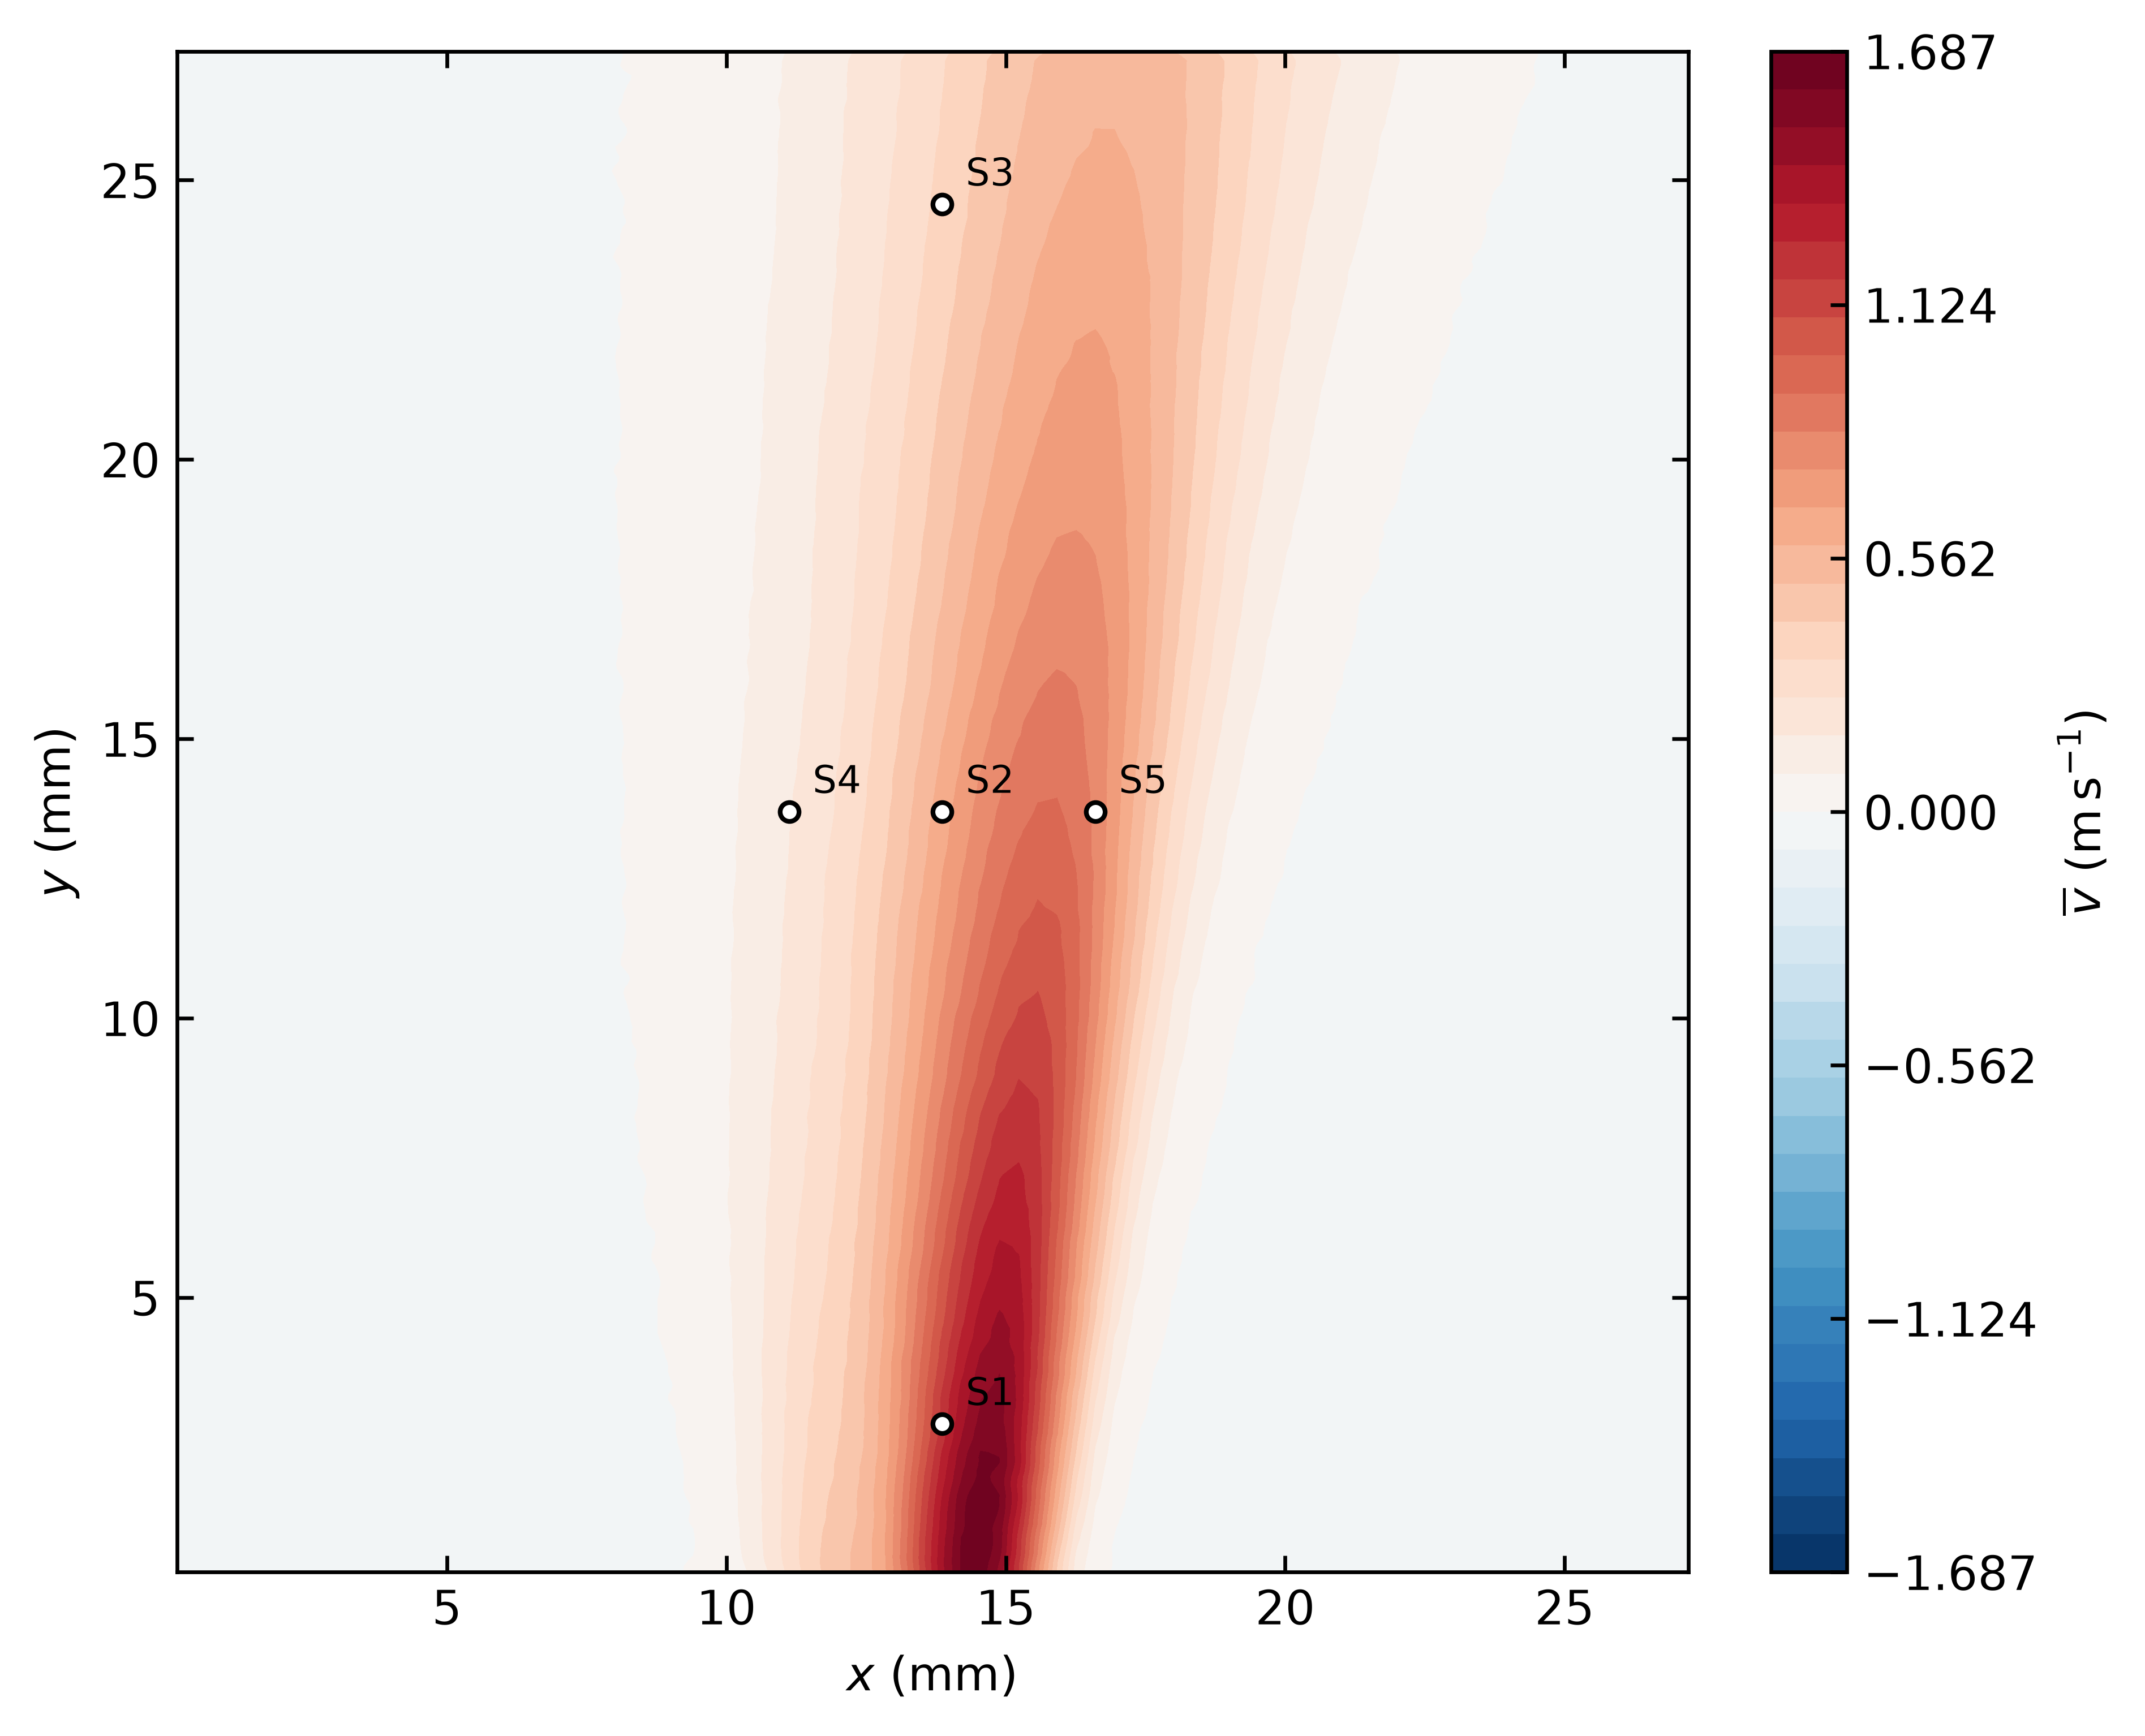

profile_mean_v


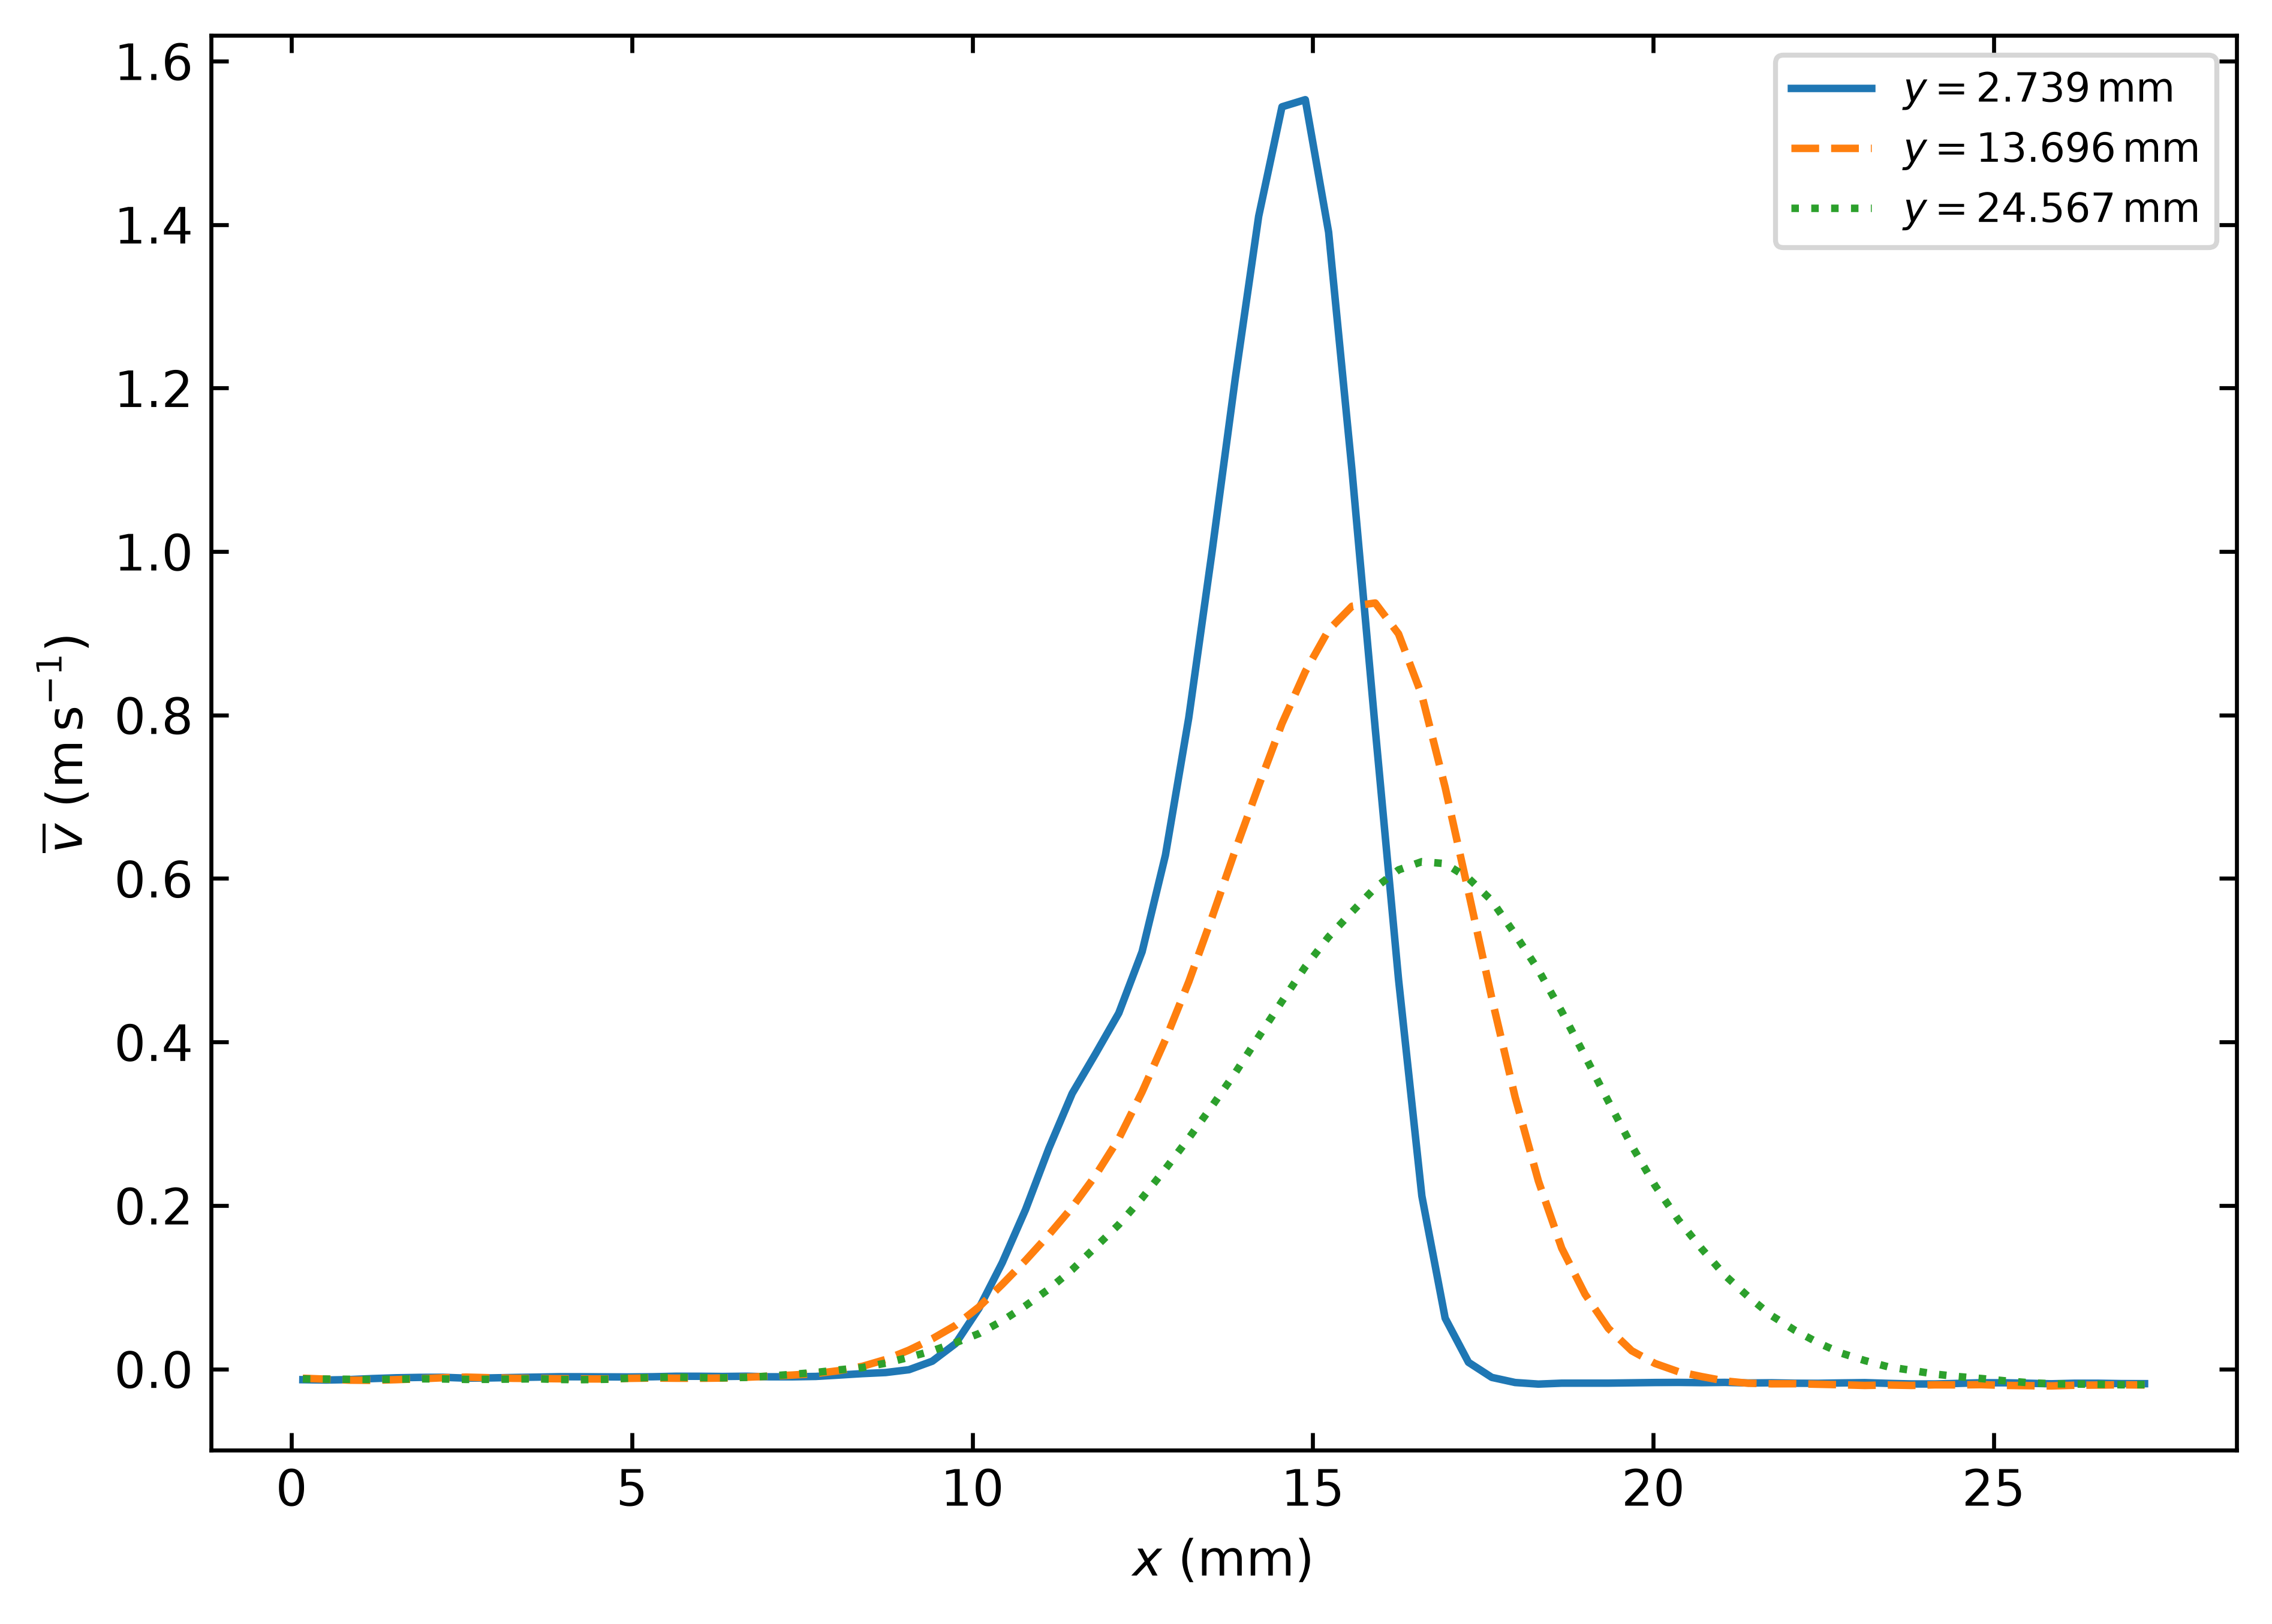

profile_rms_v


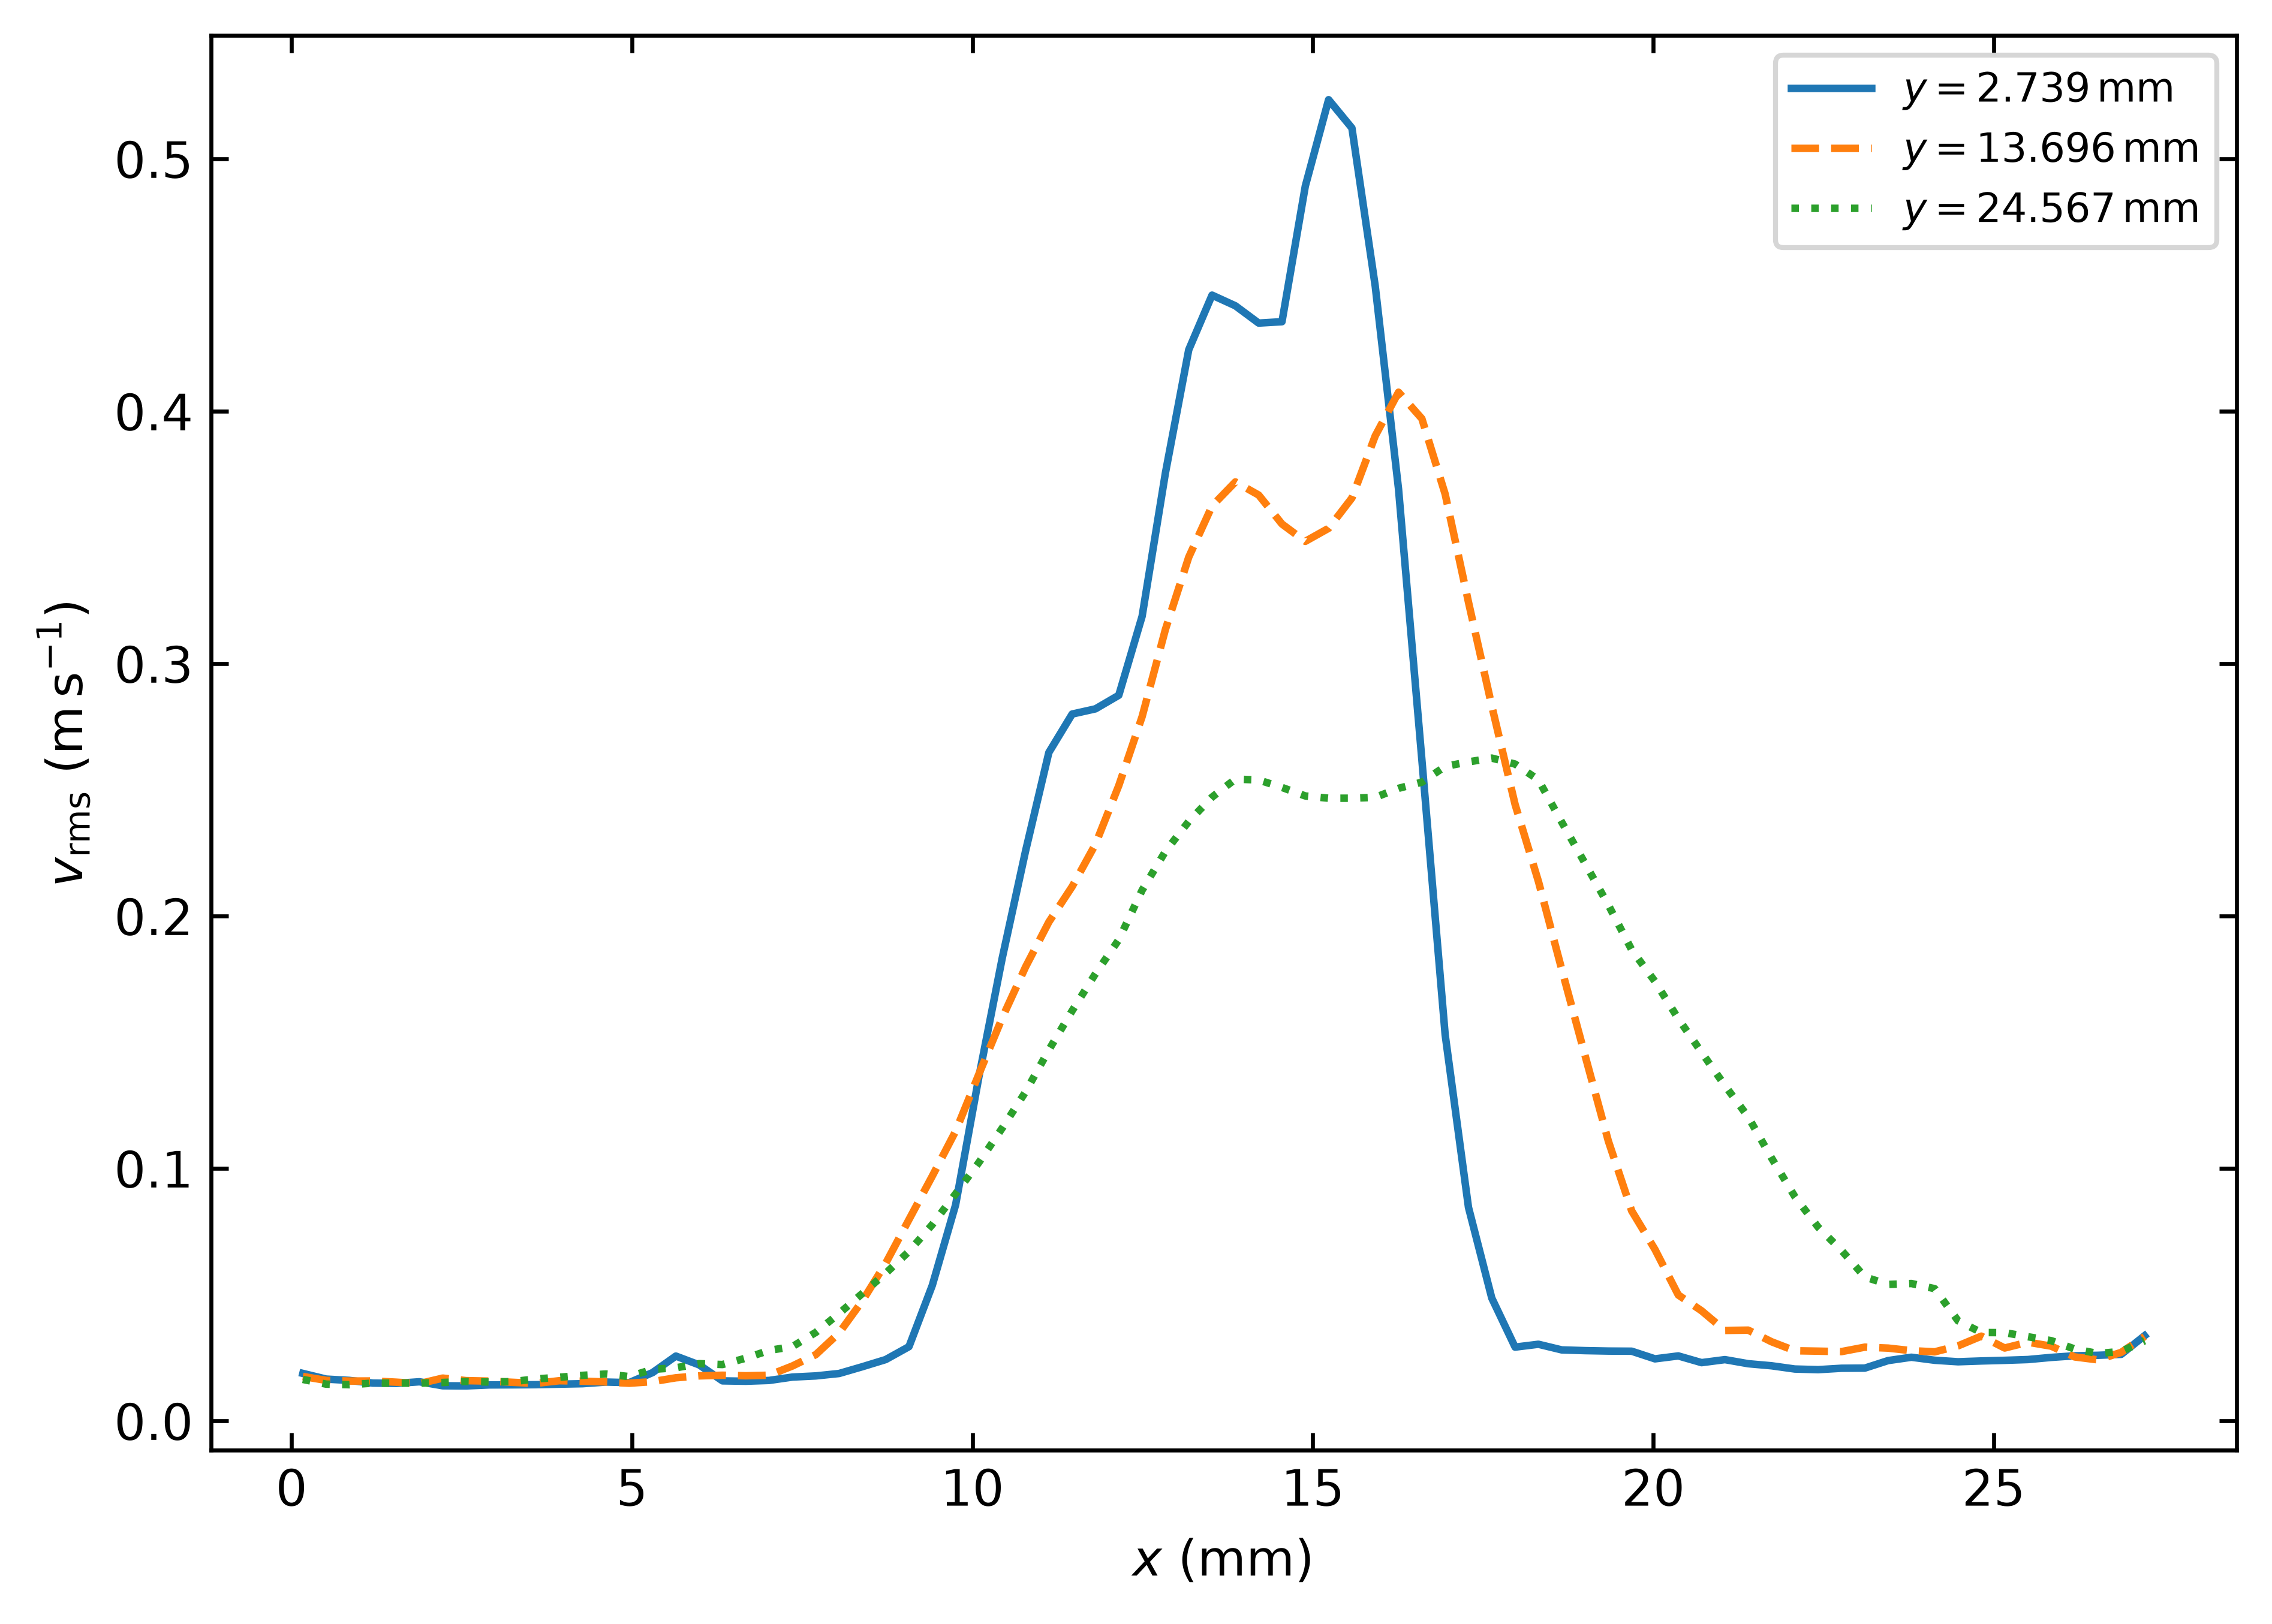

profile_rms_u


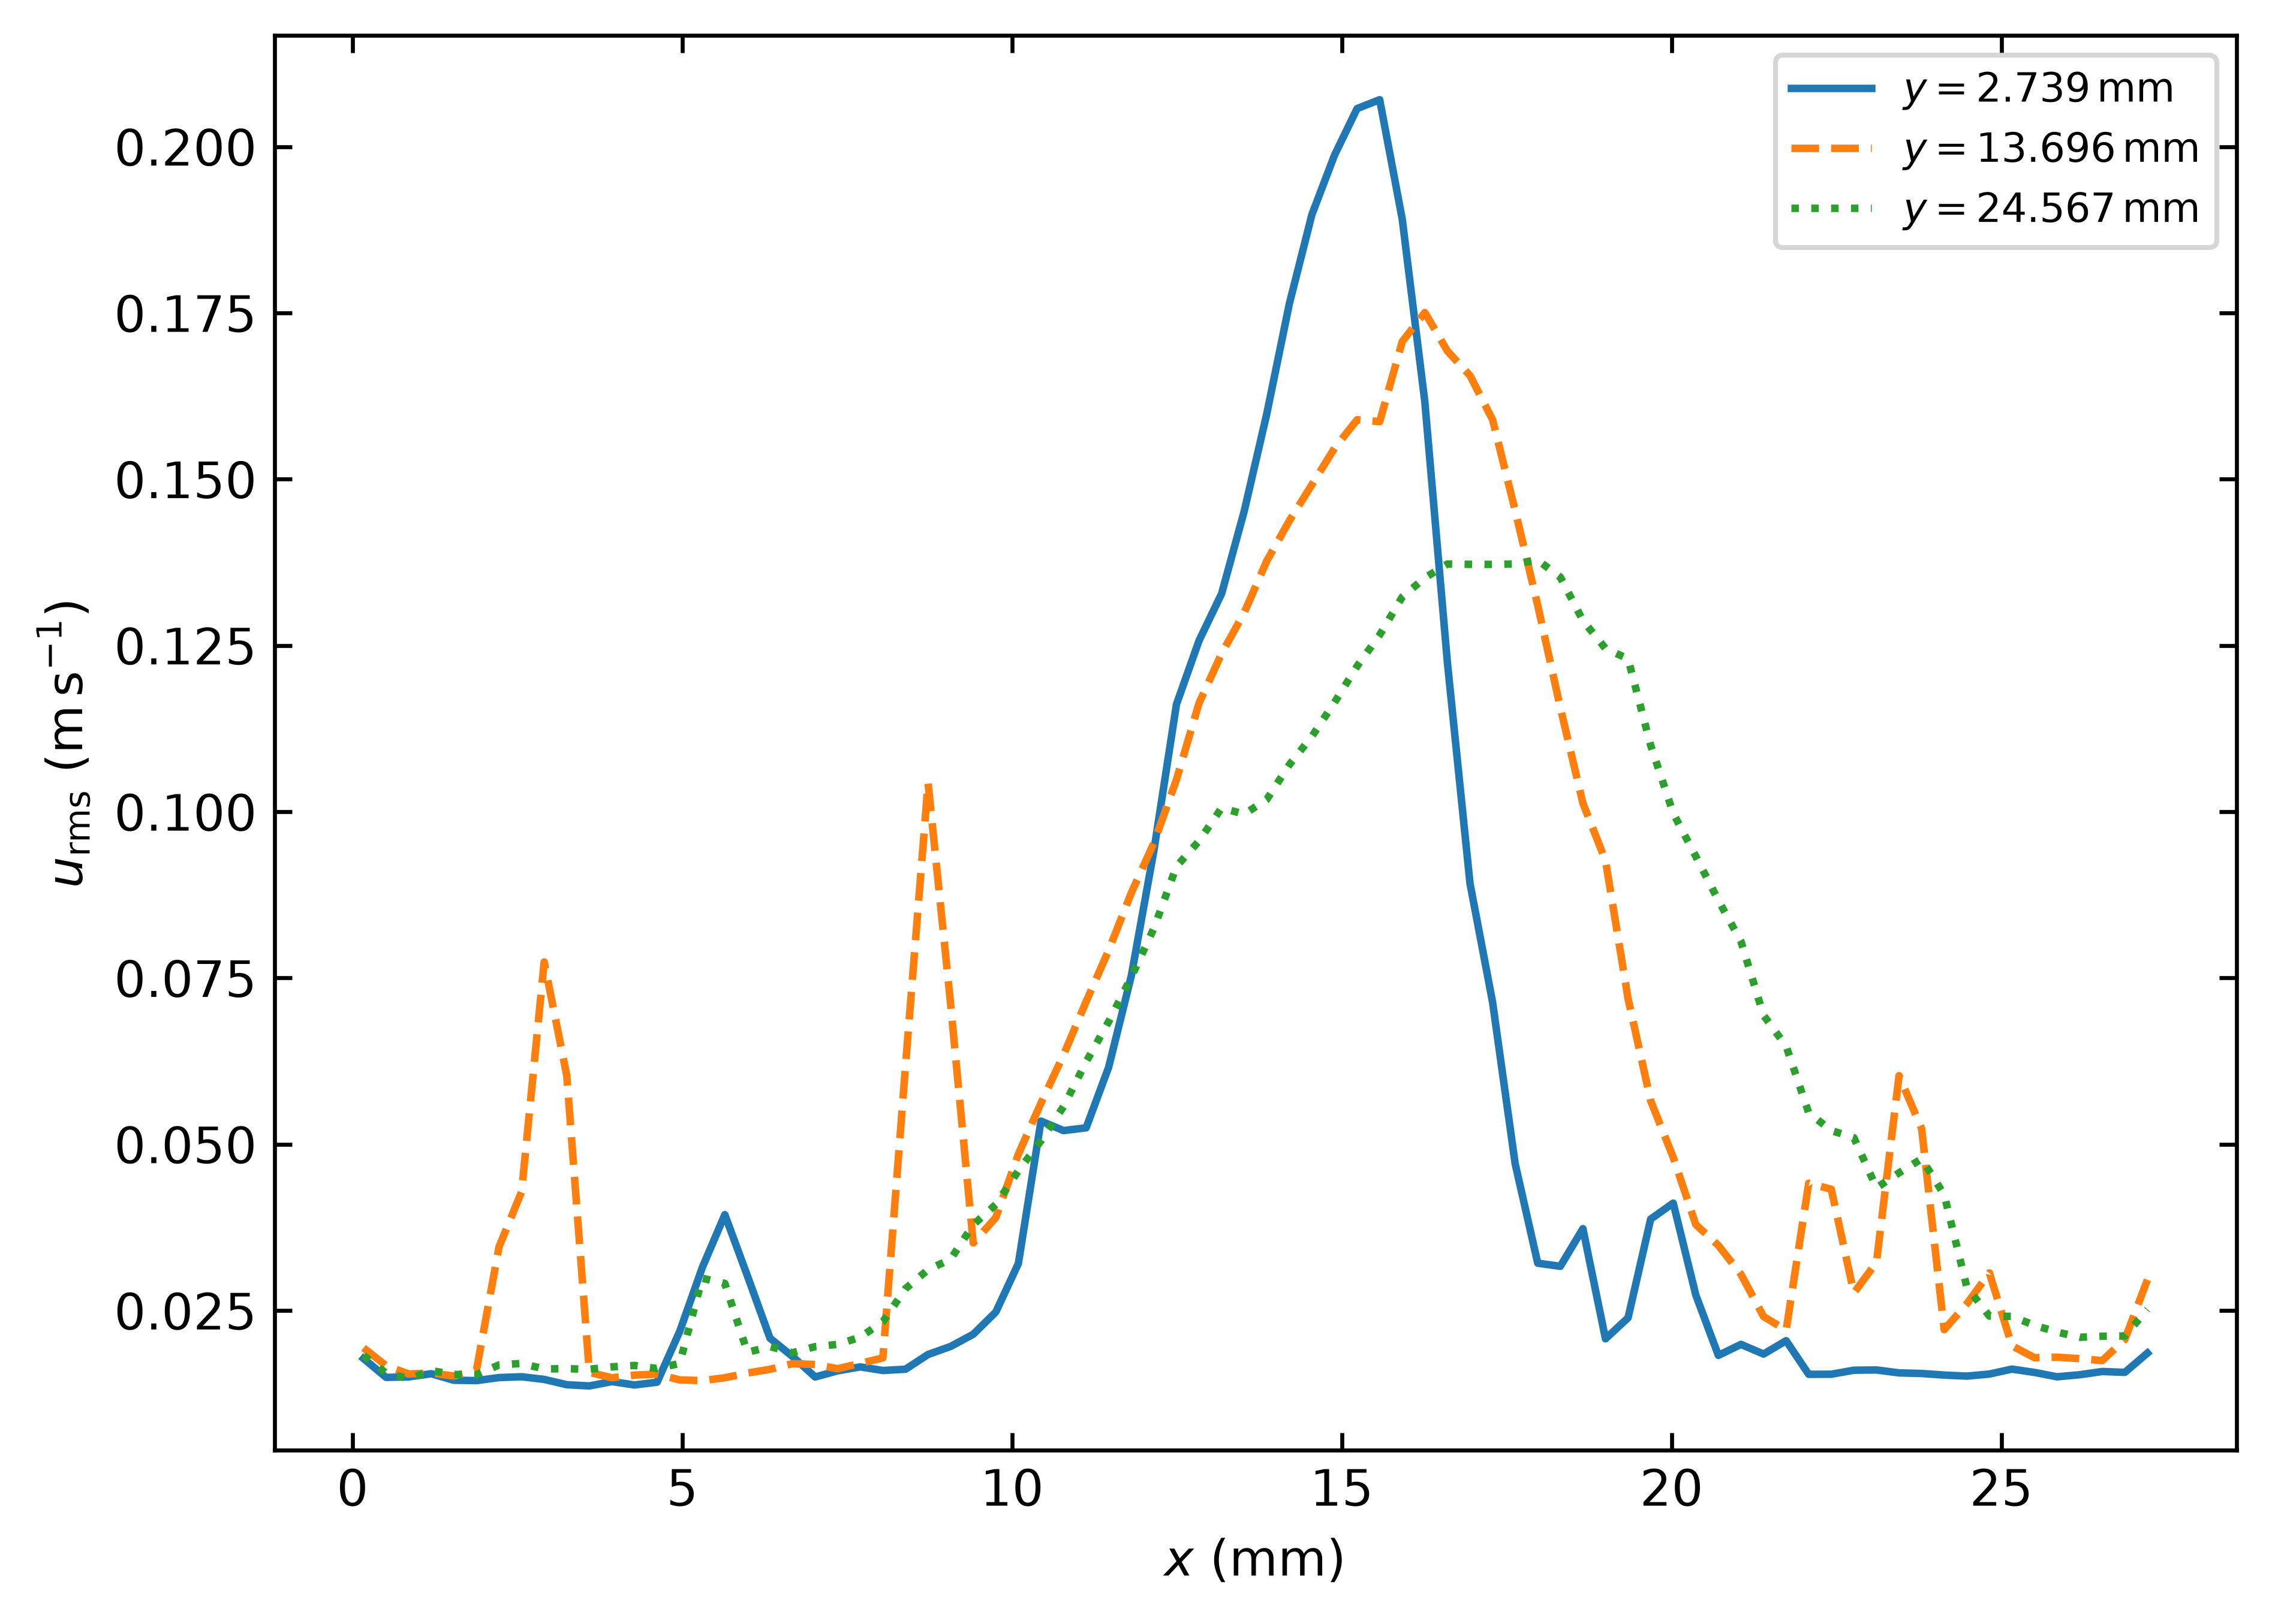

profile_covariance


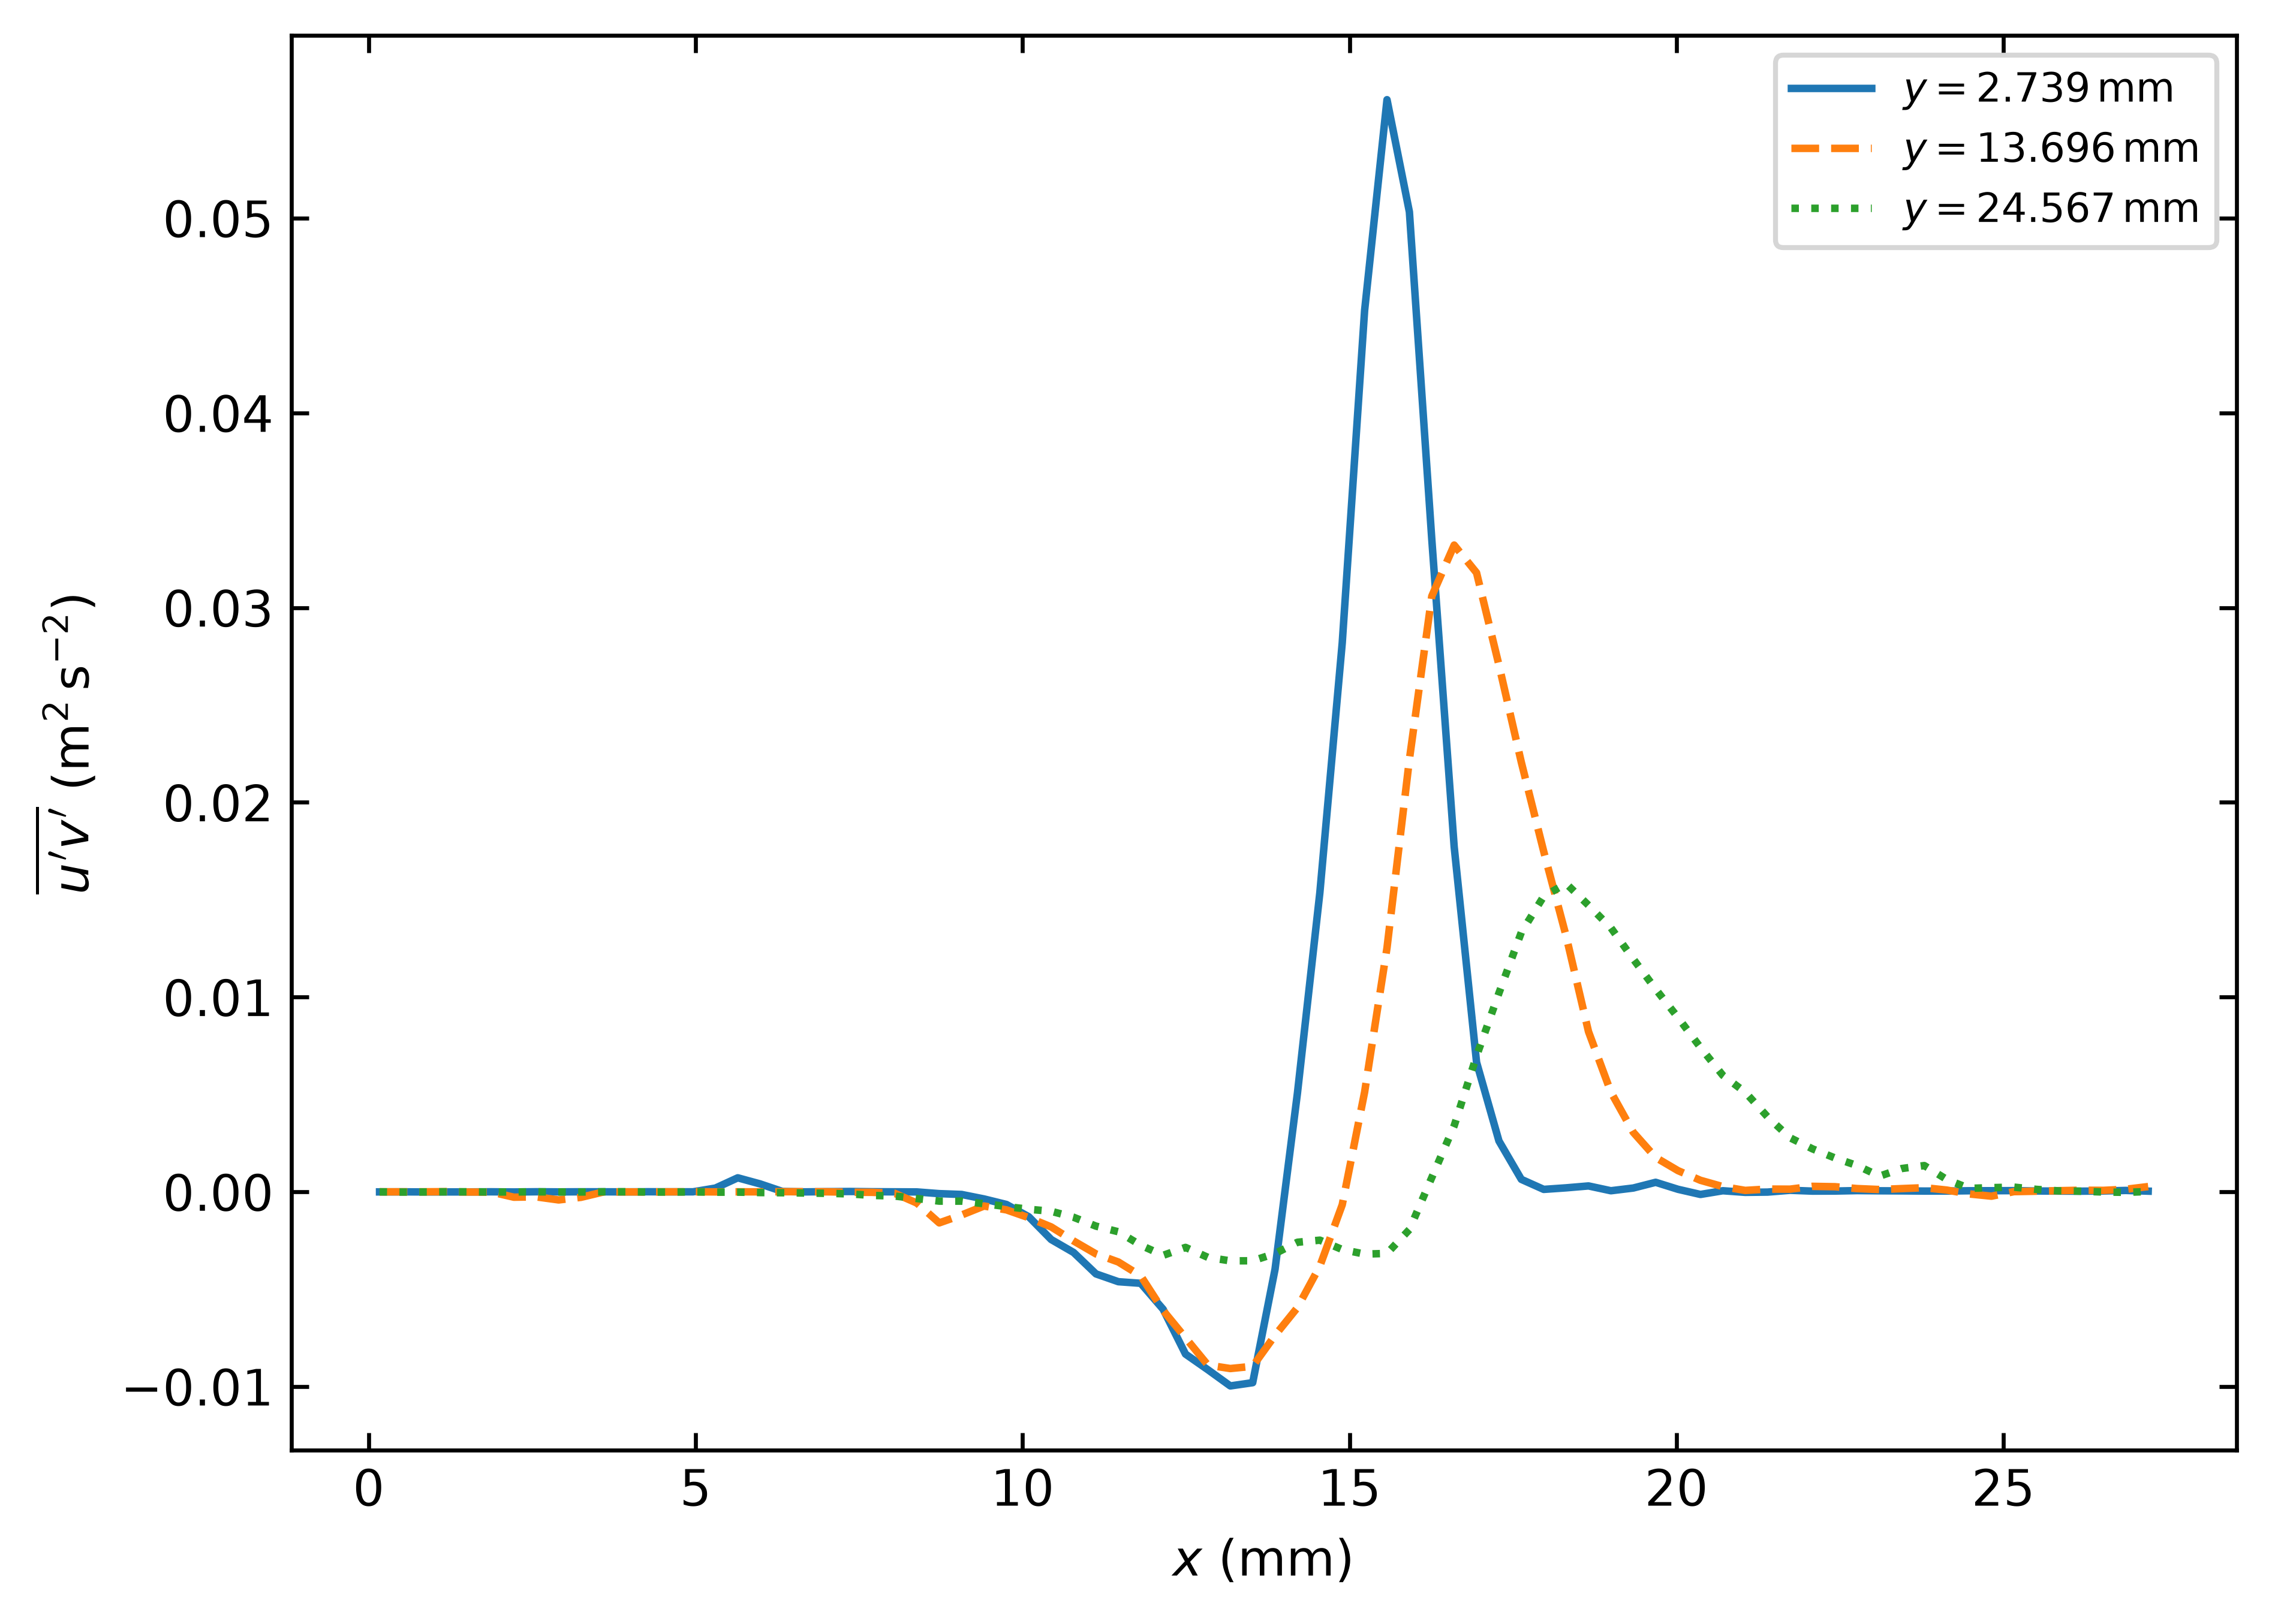

v_pdf


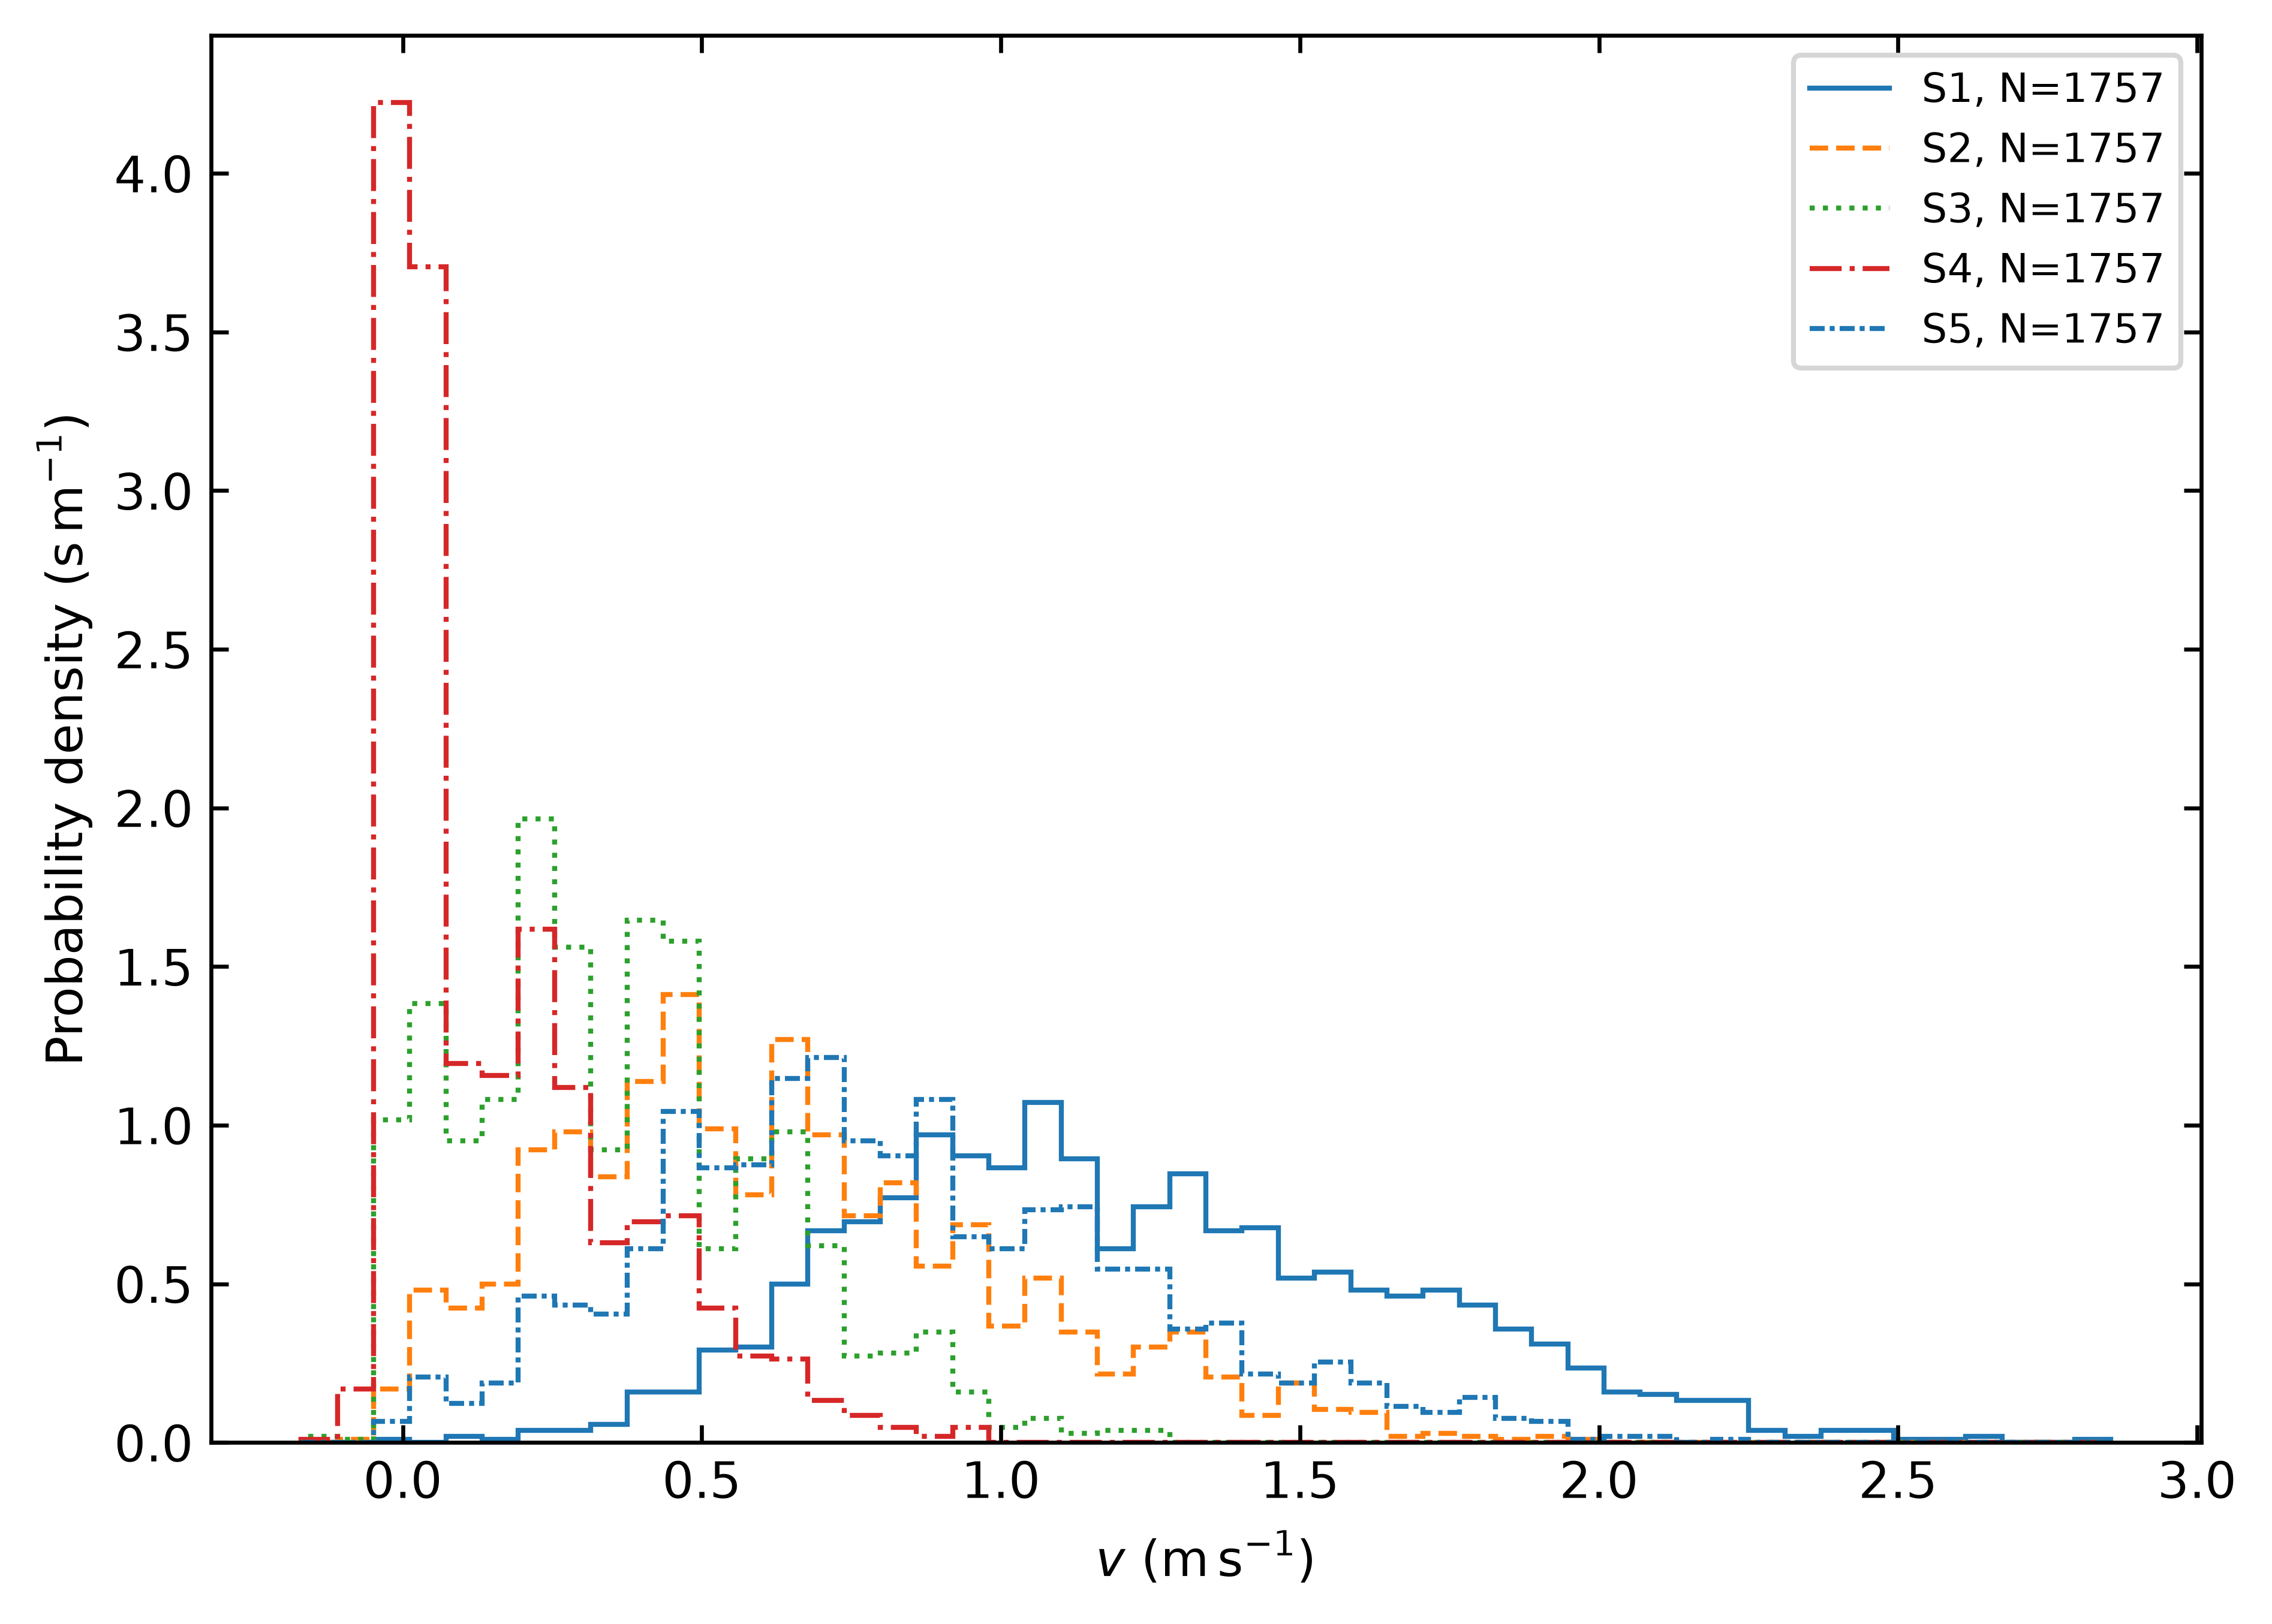

u_pdf


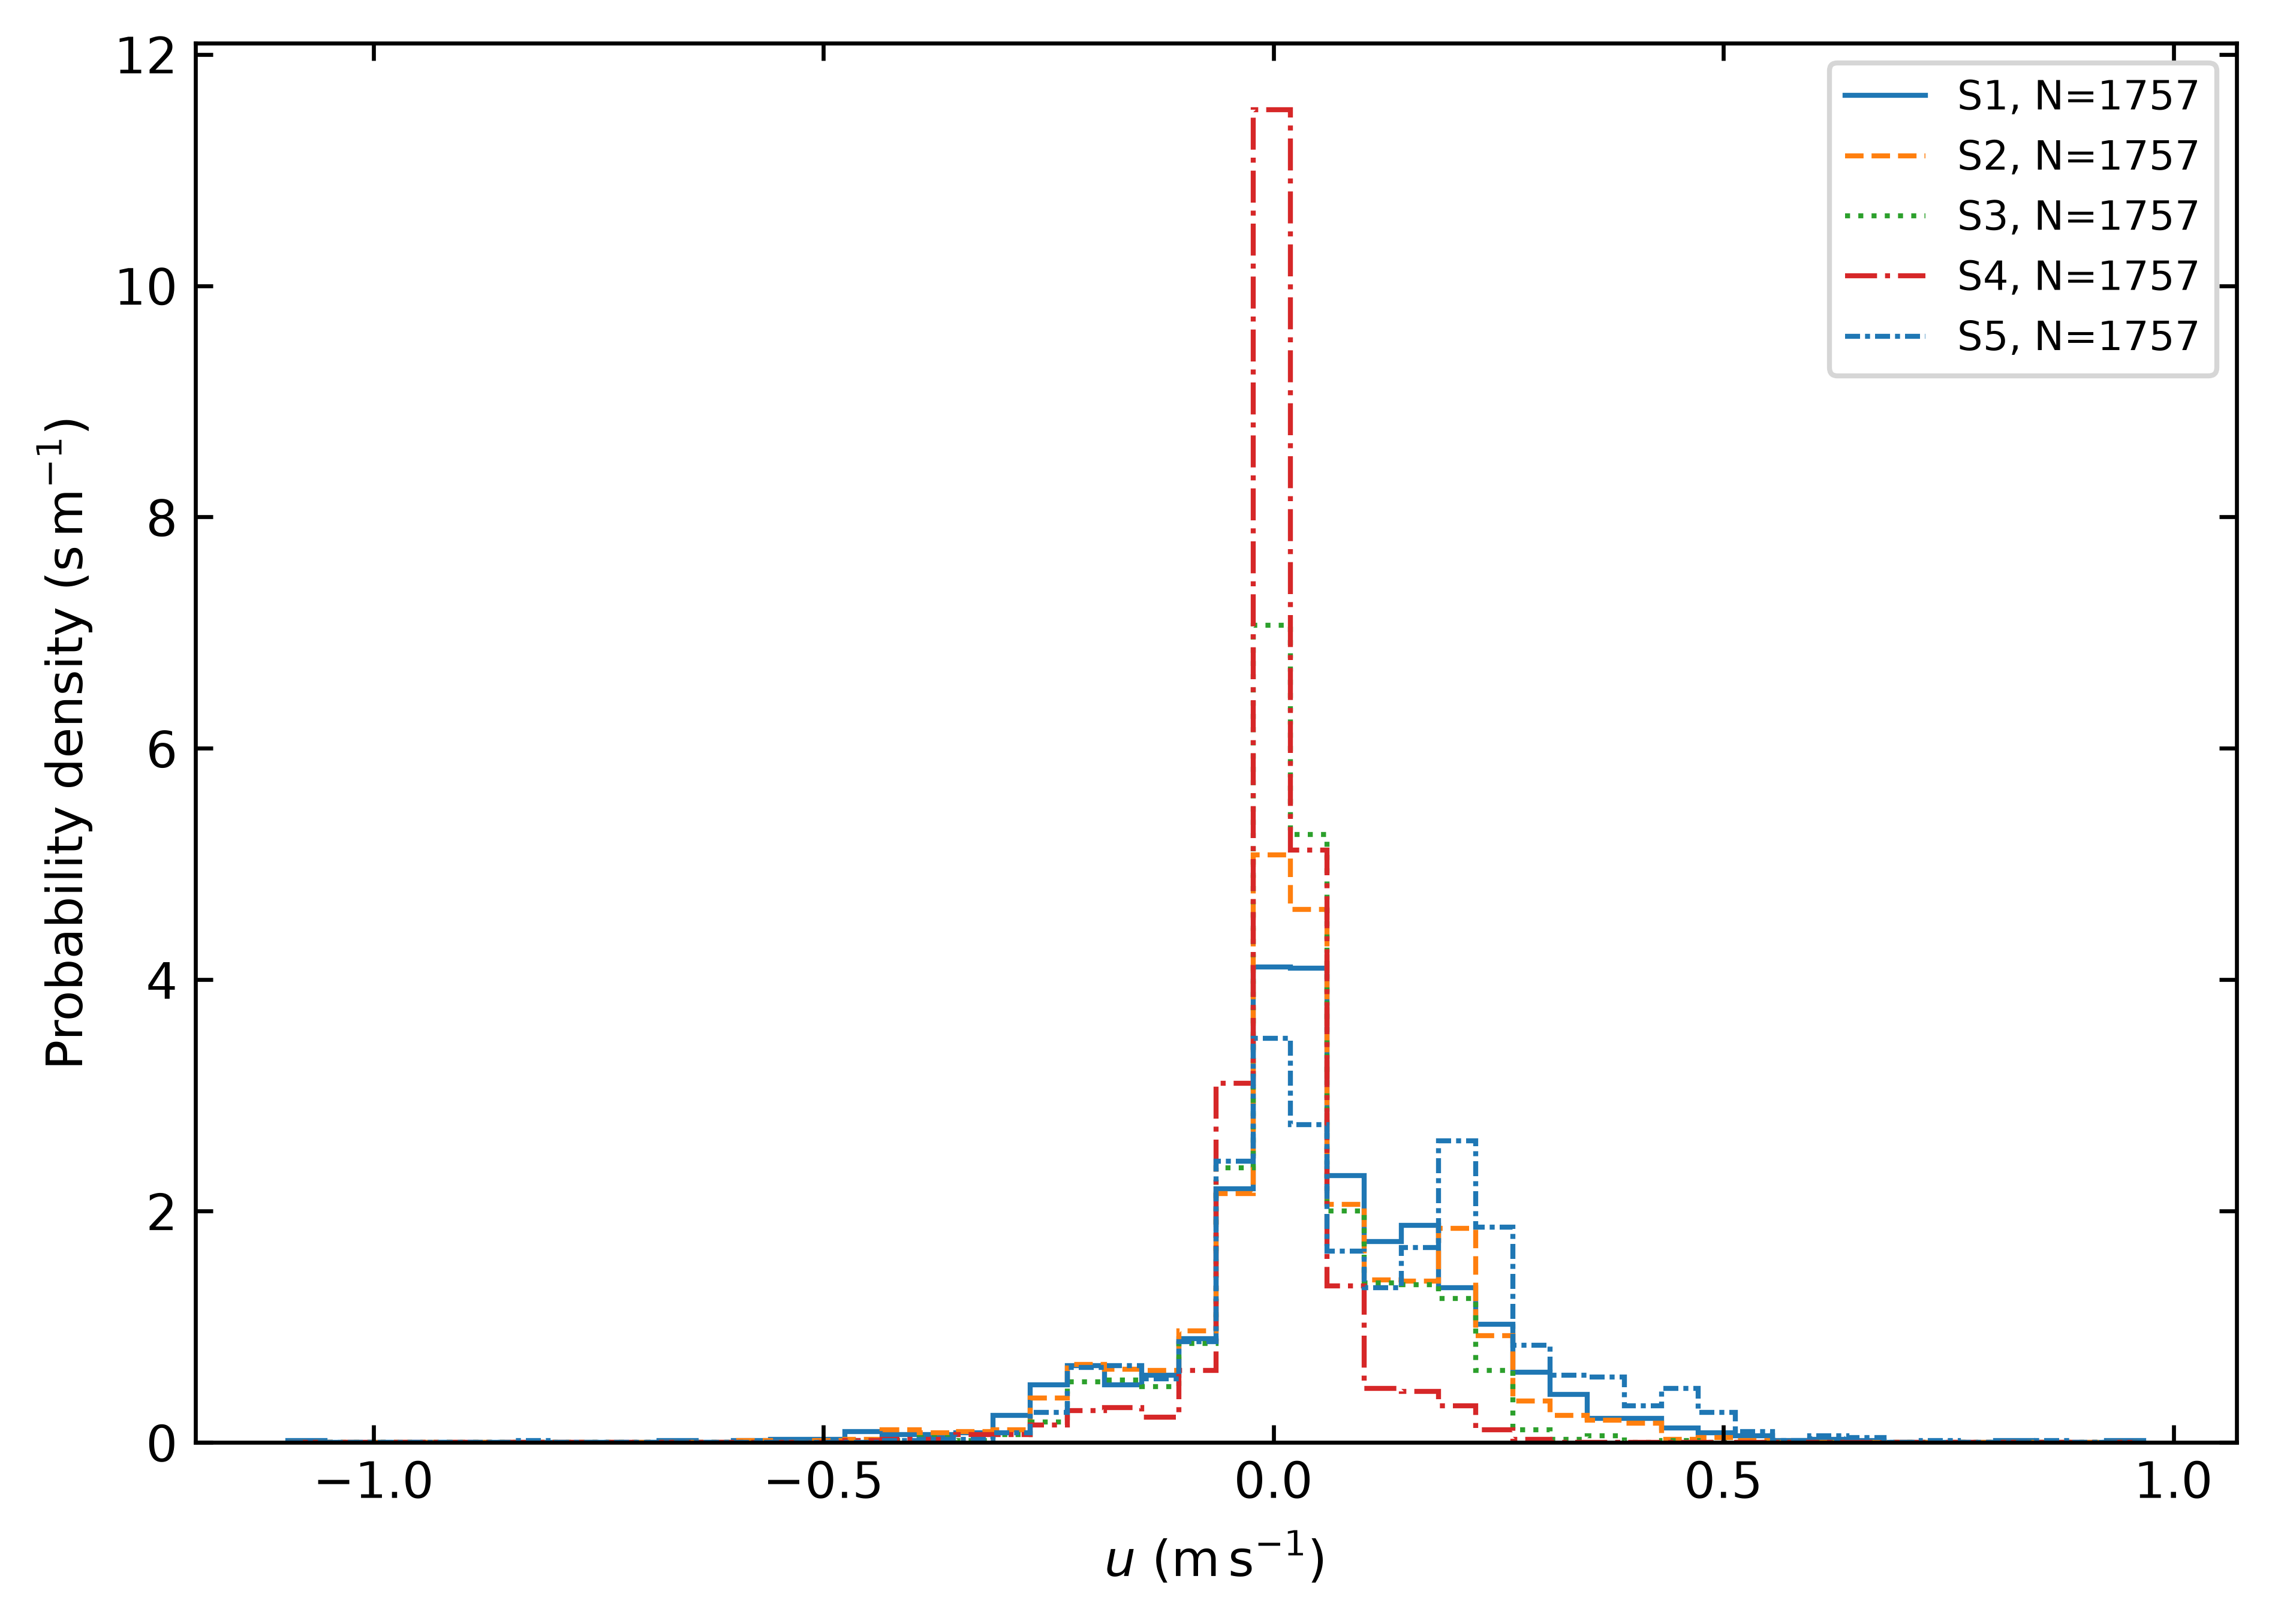

v_cdf


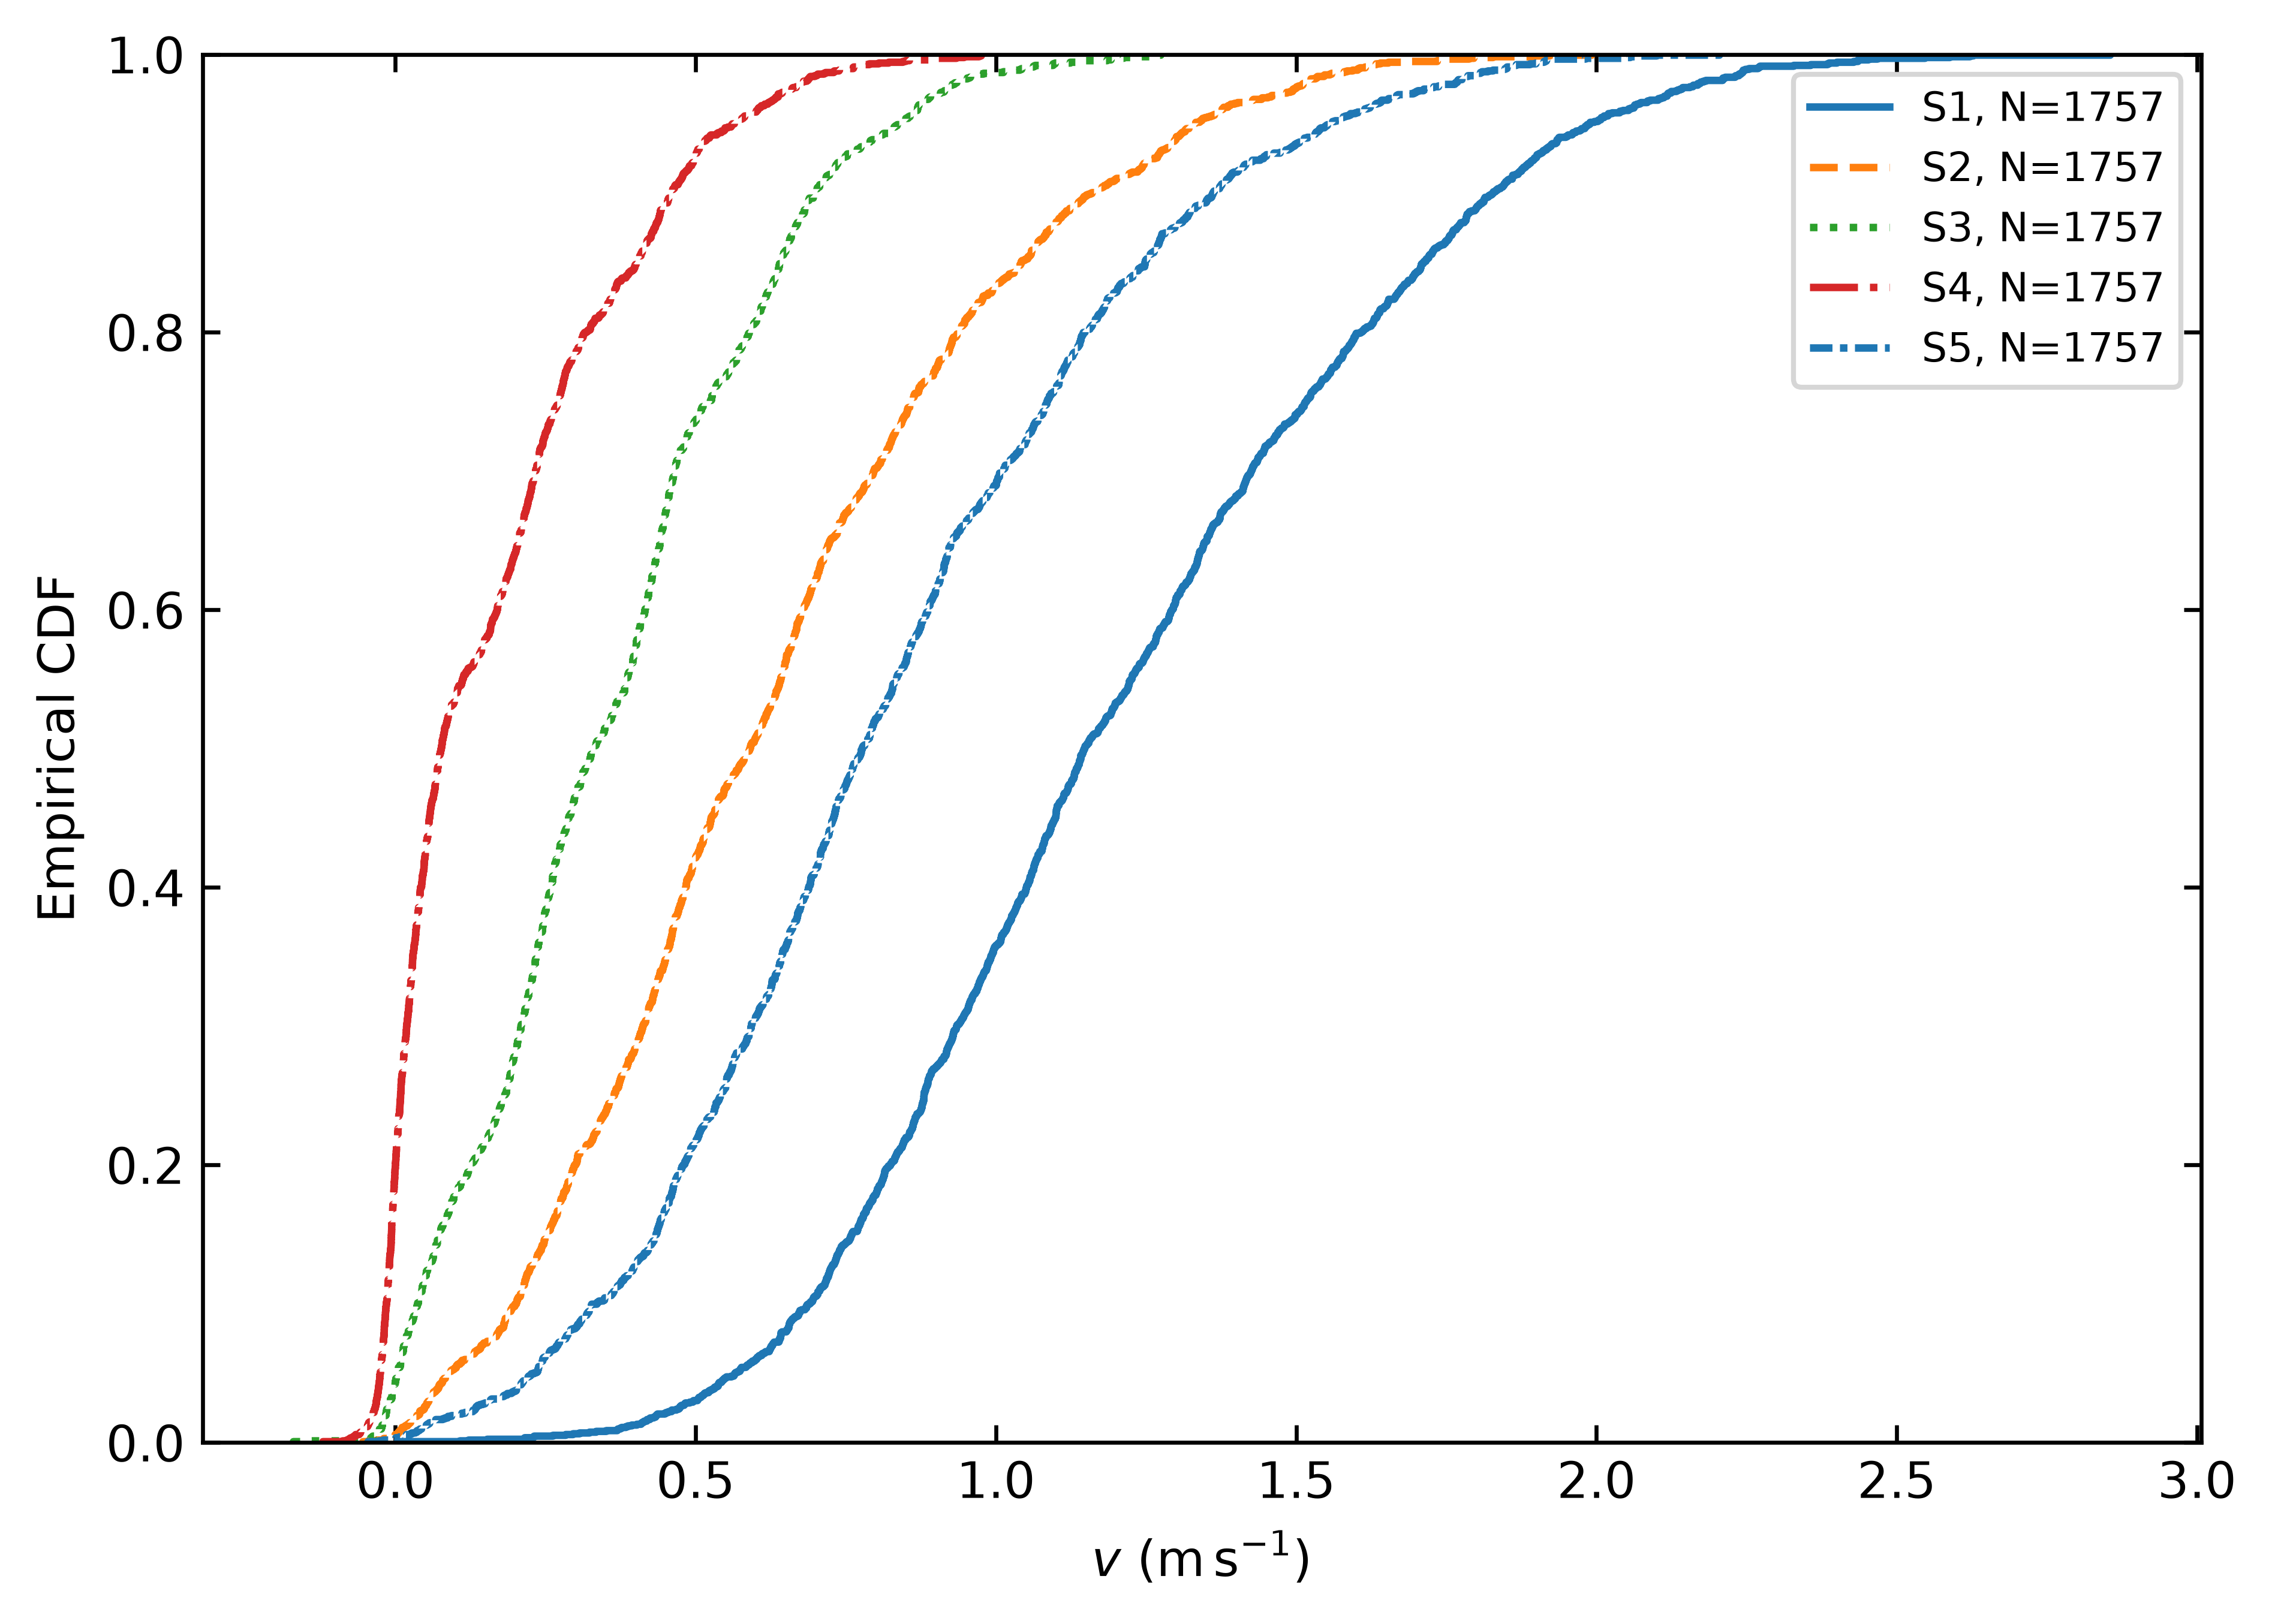

u_cdf


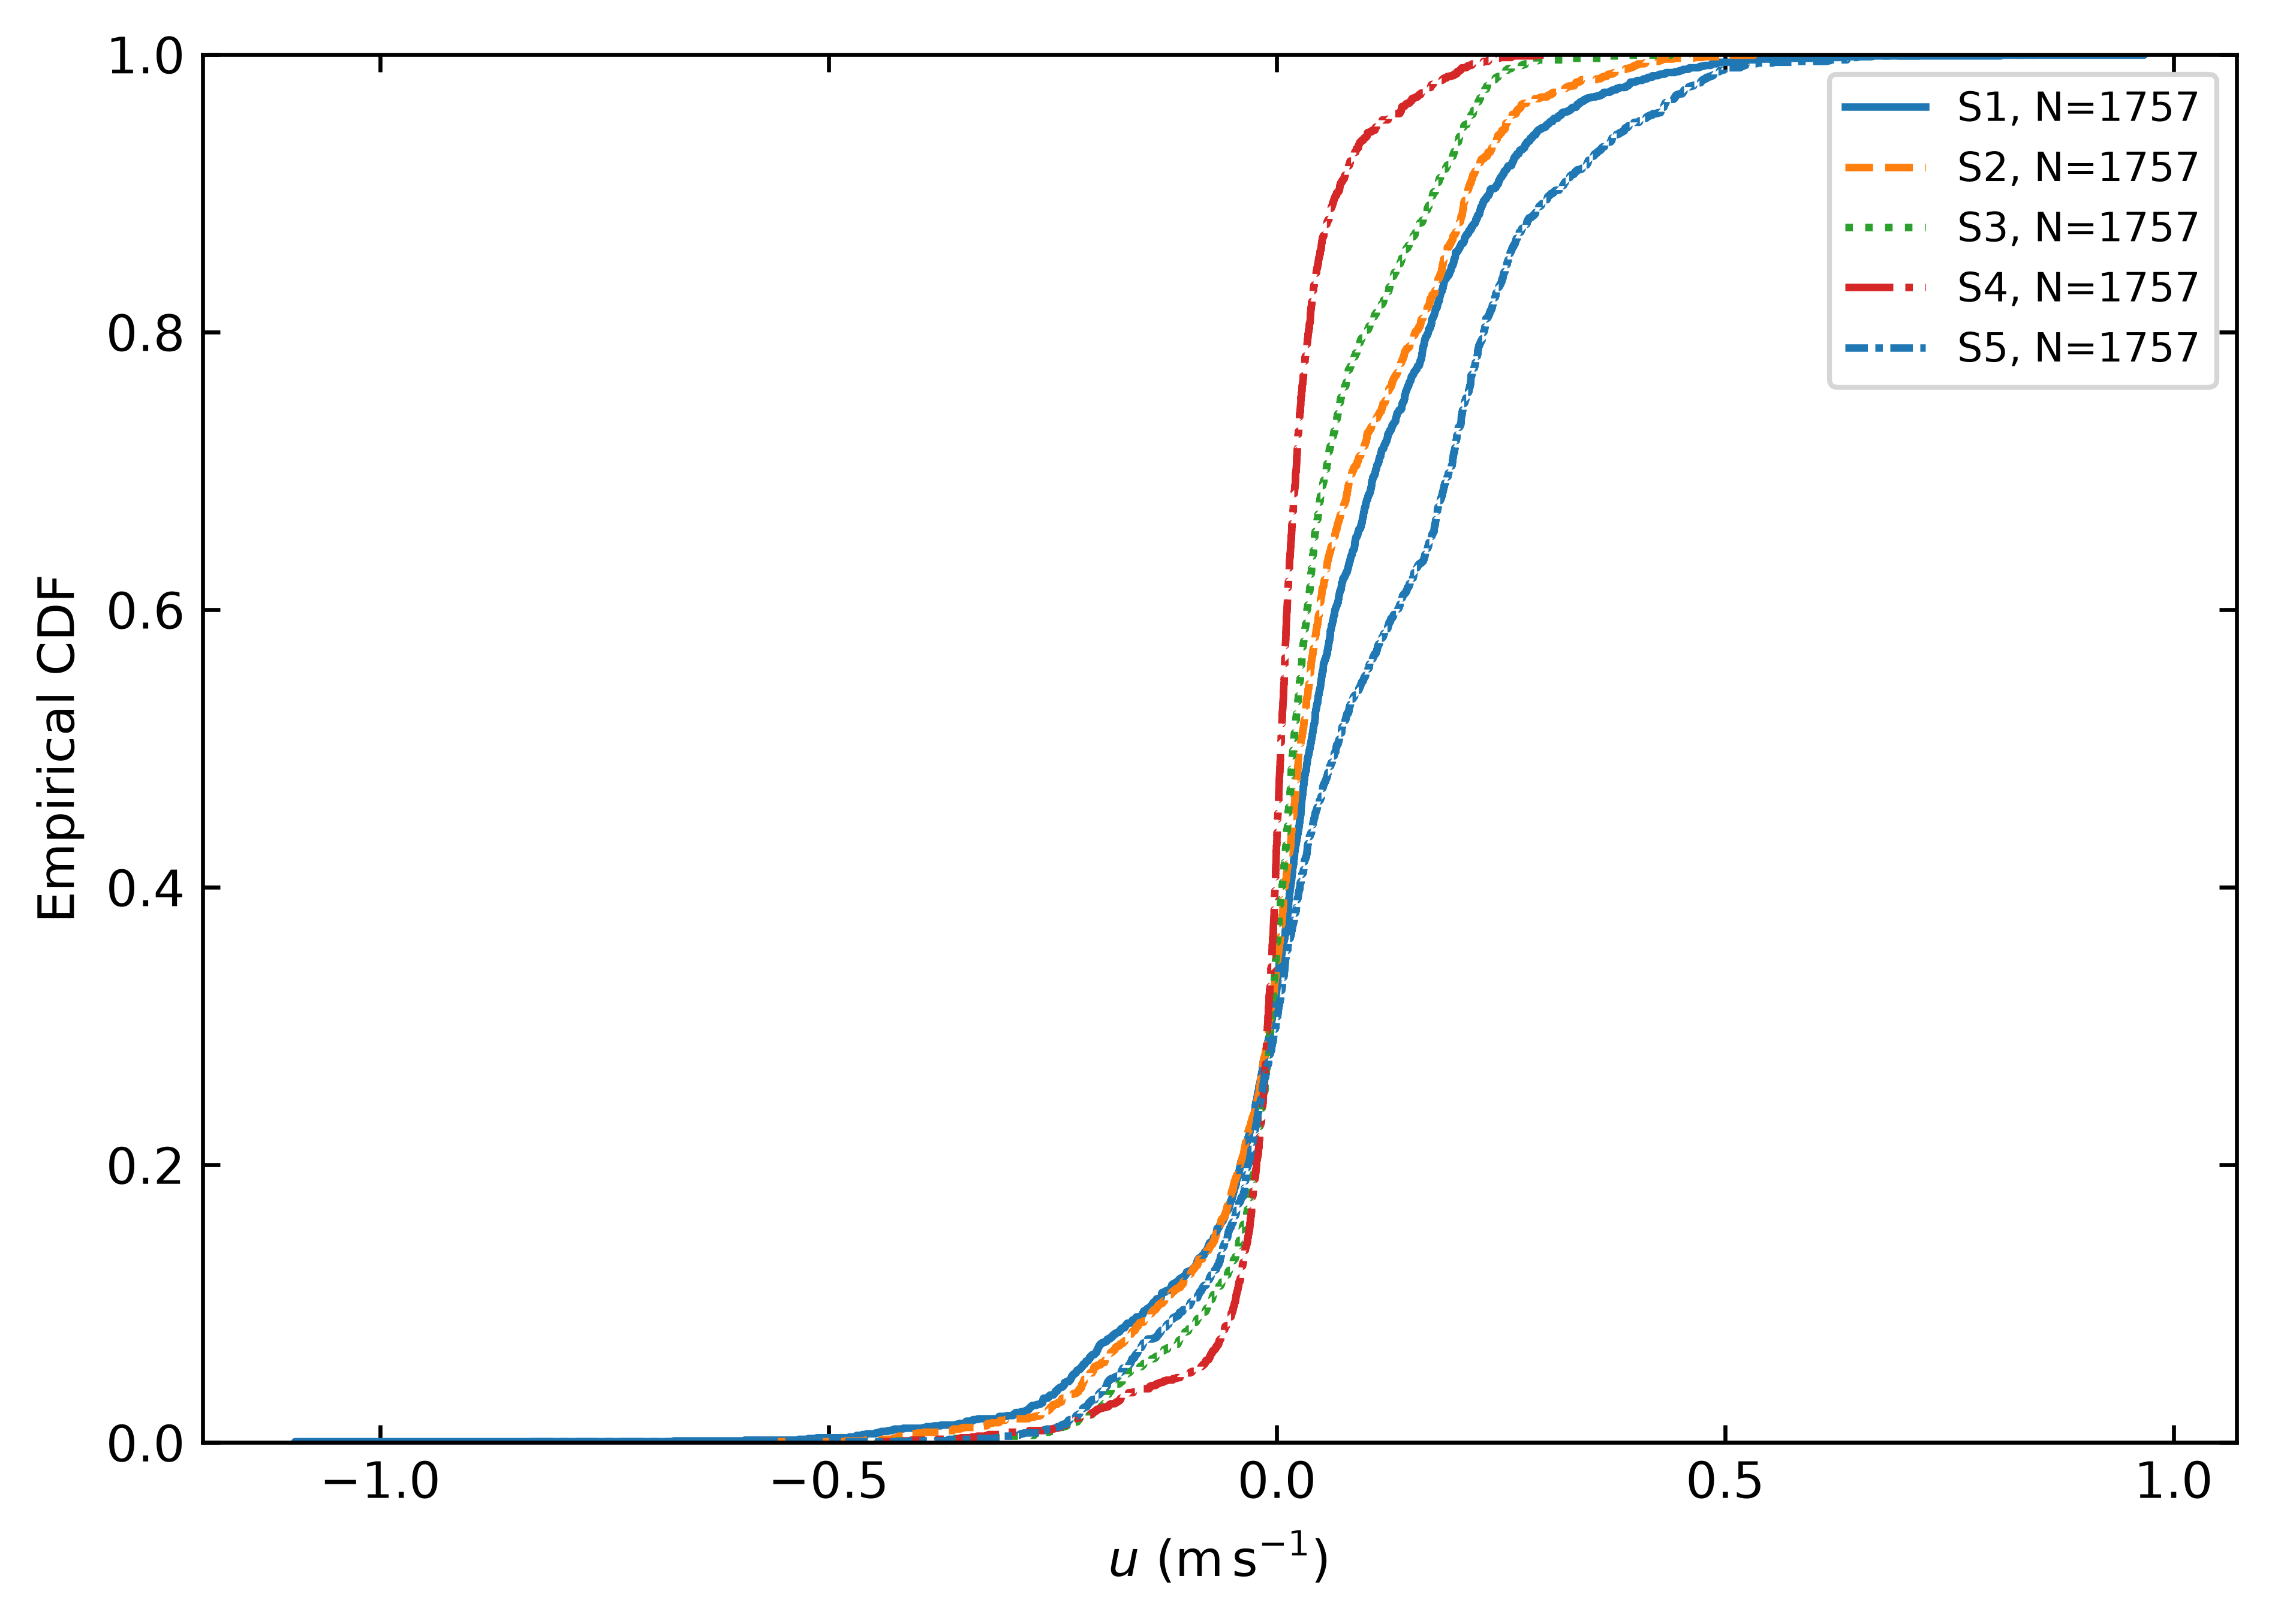

frame_879_v


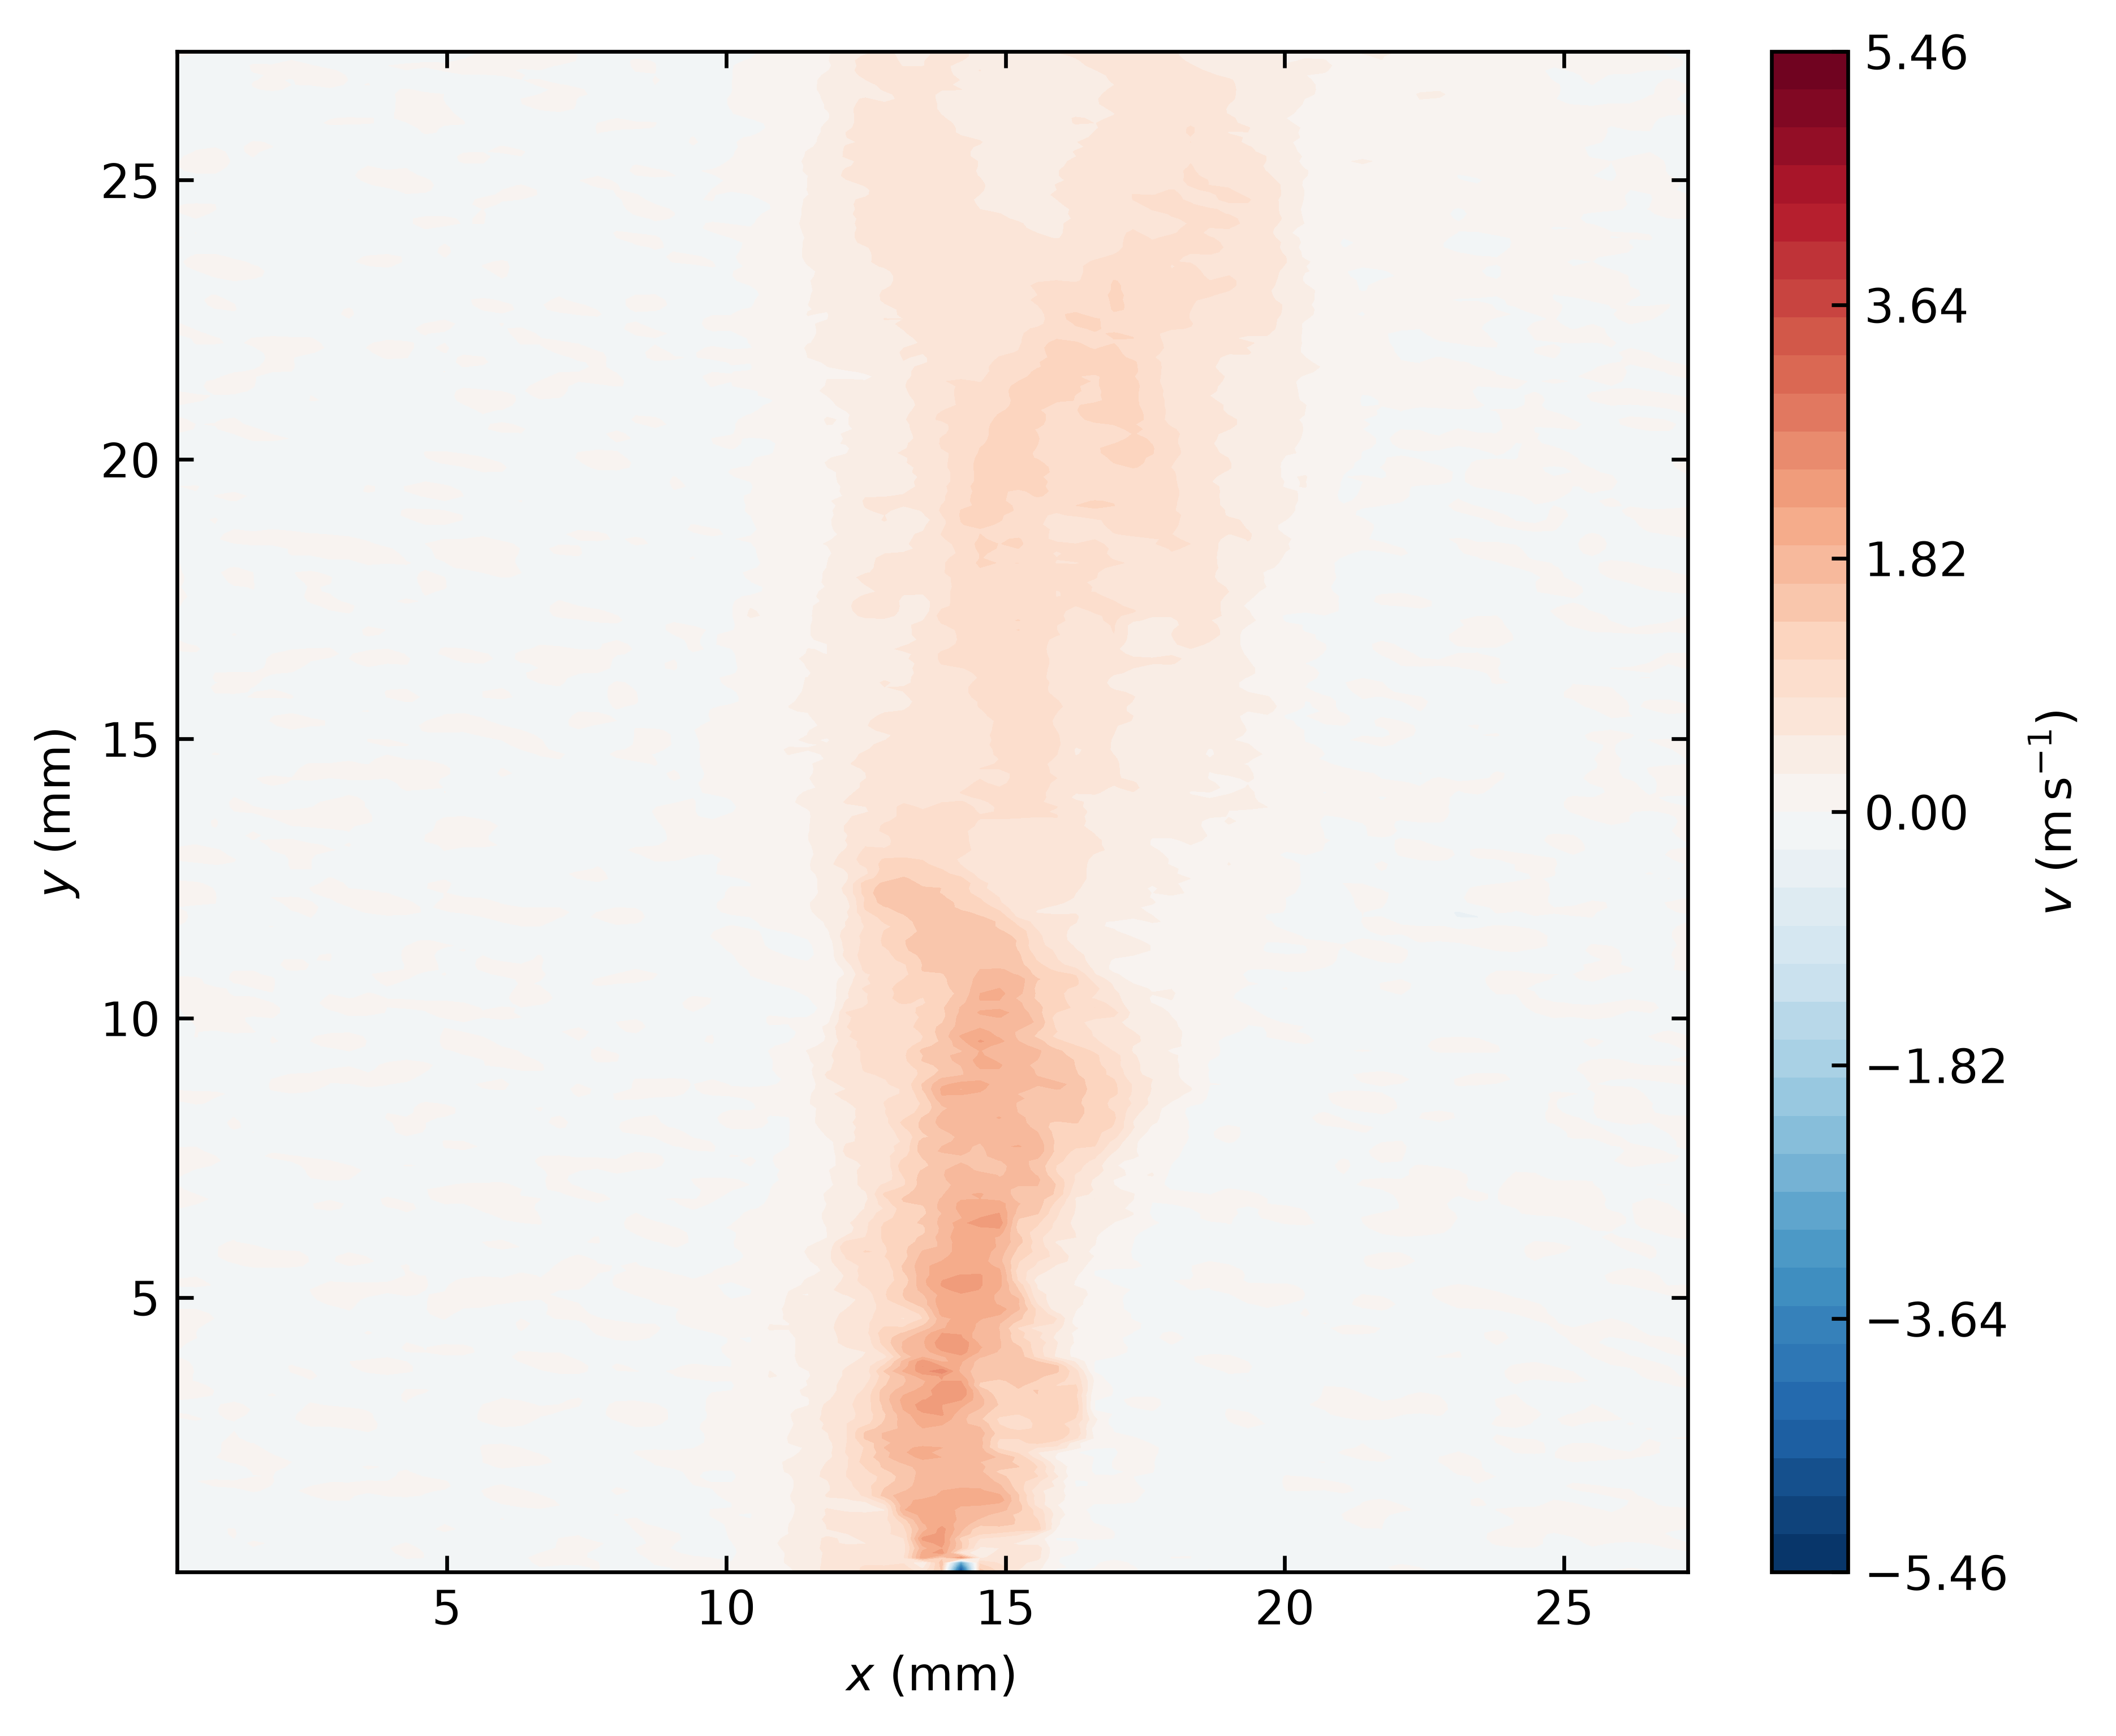

frame_879_u


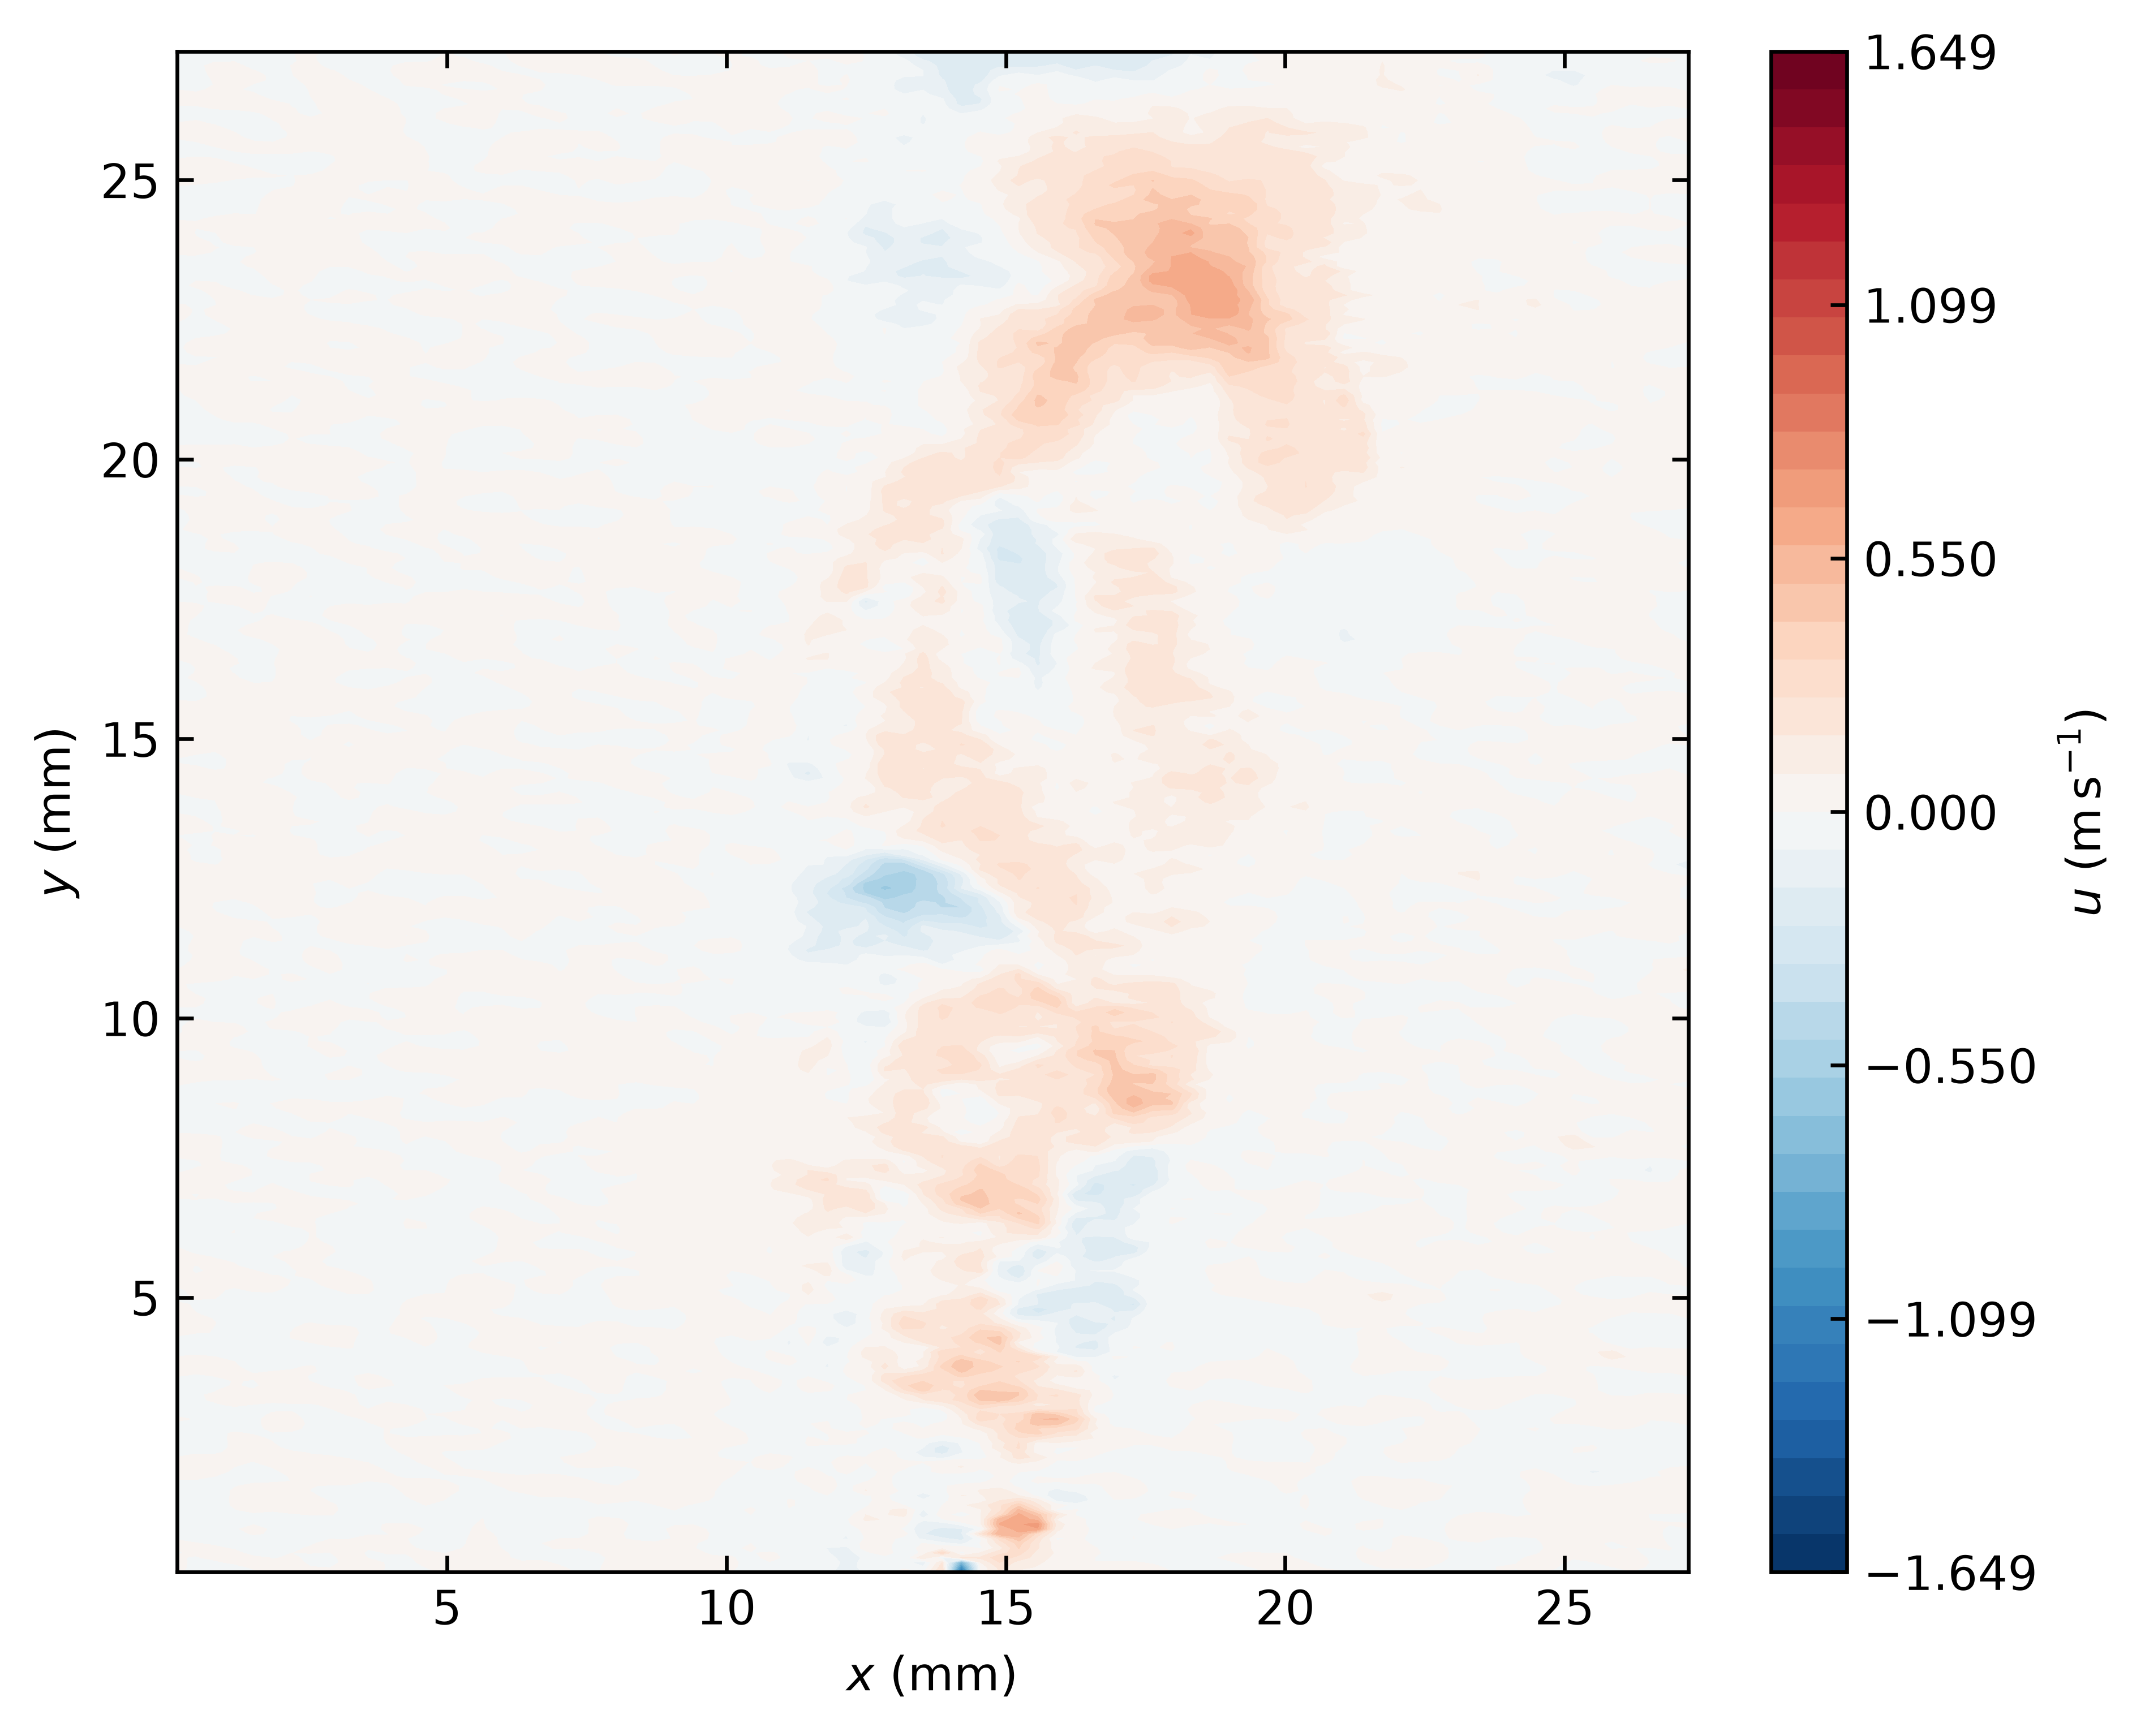

frame_879_quiver


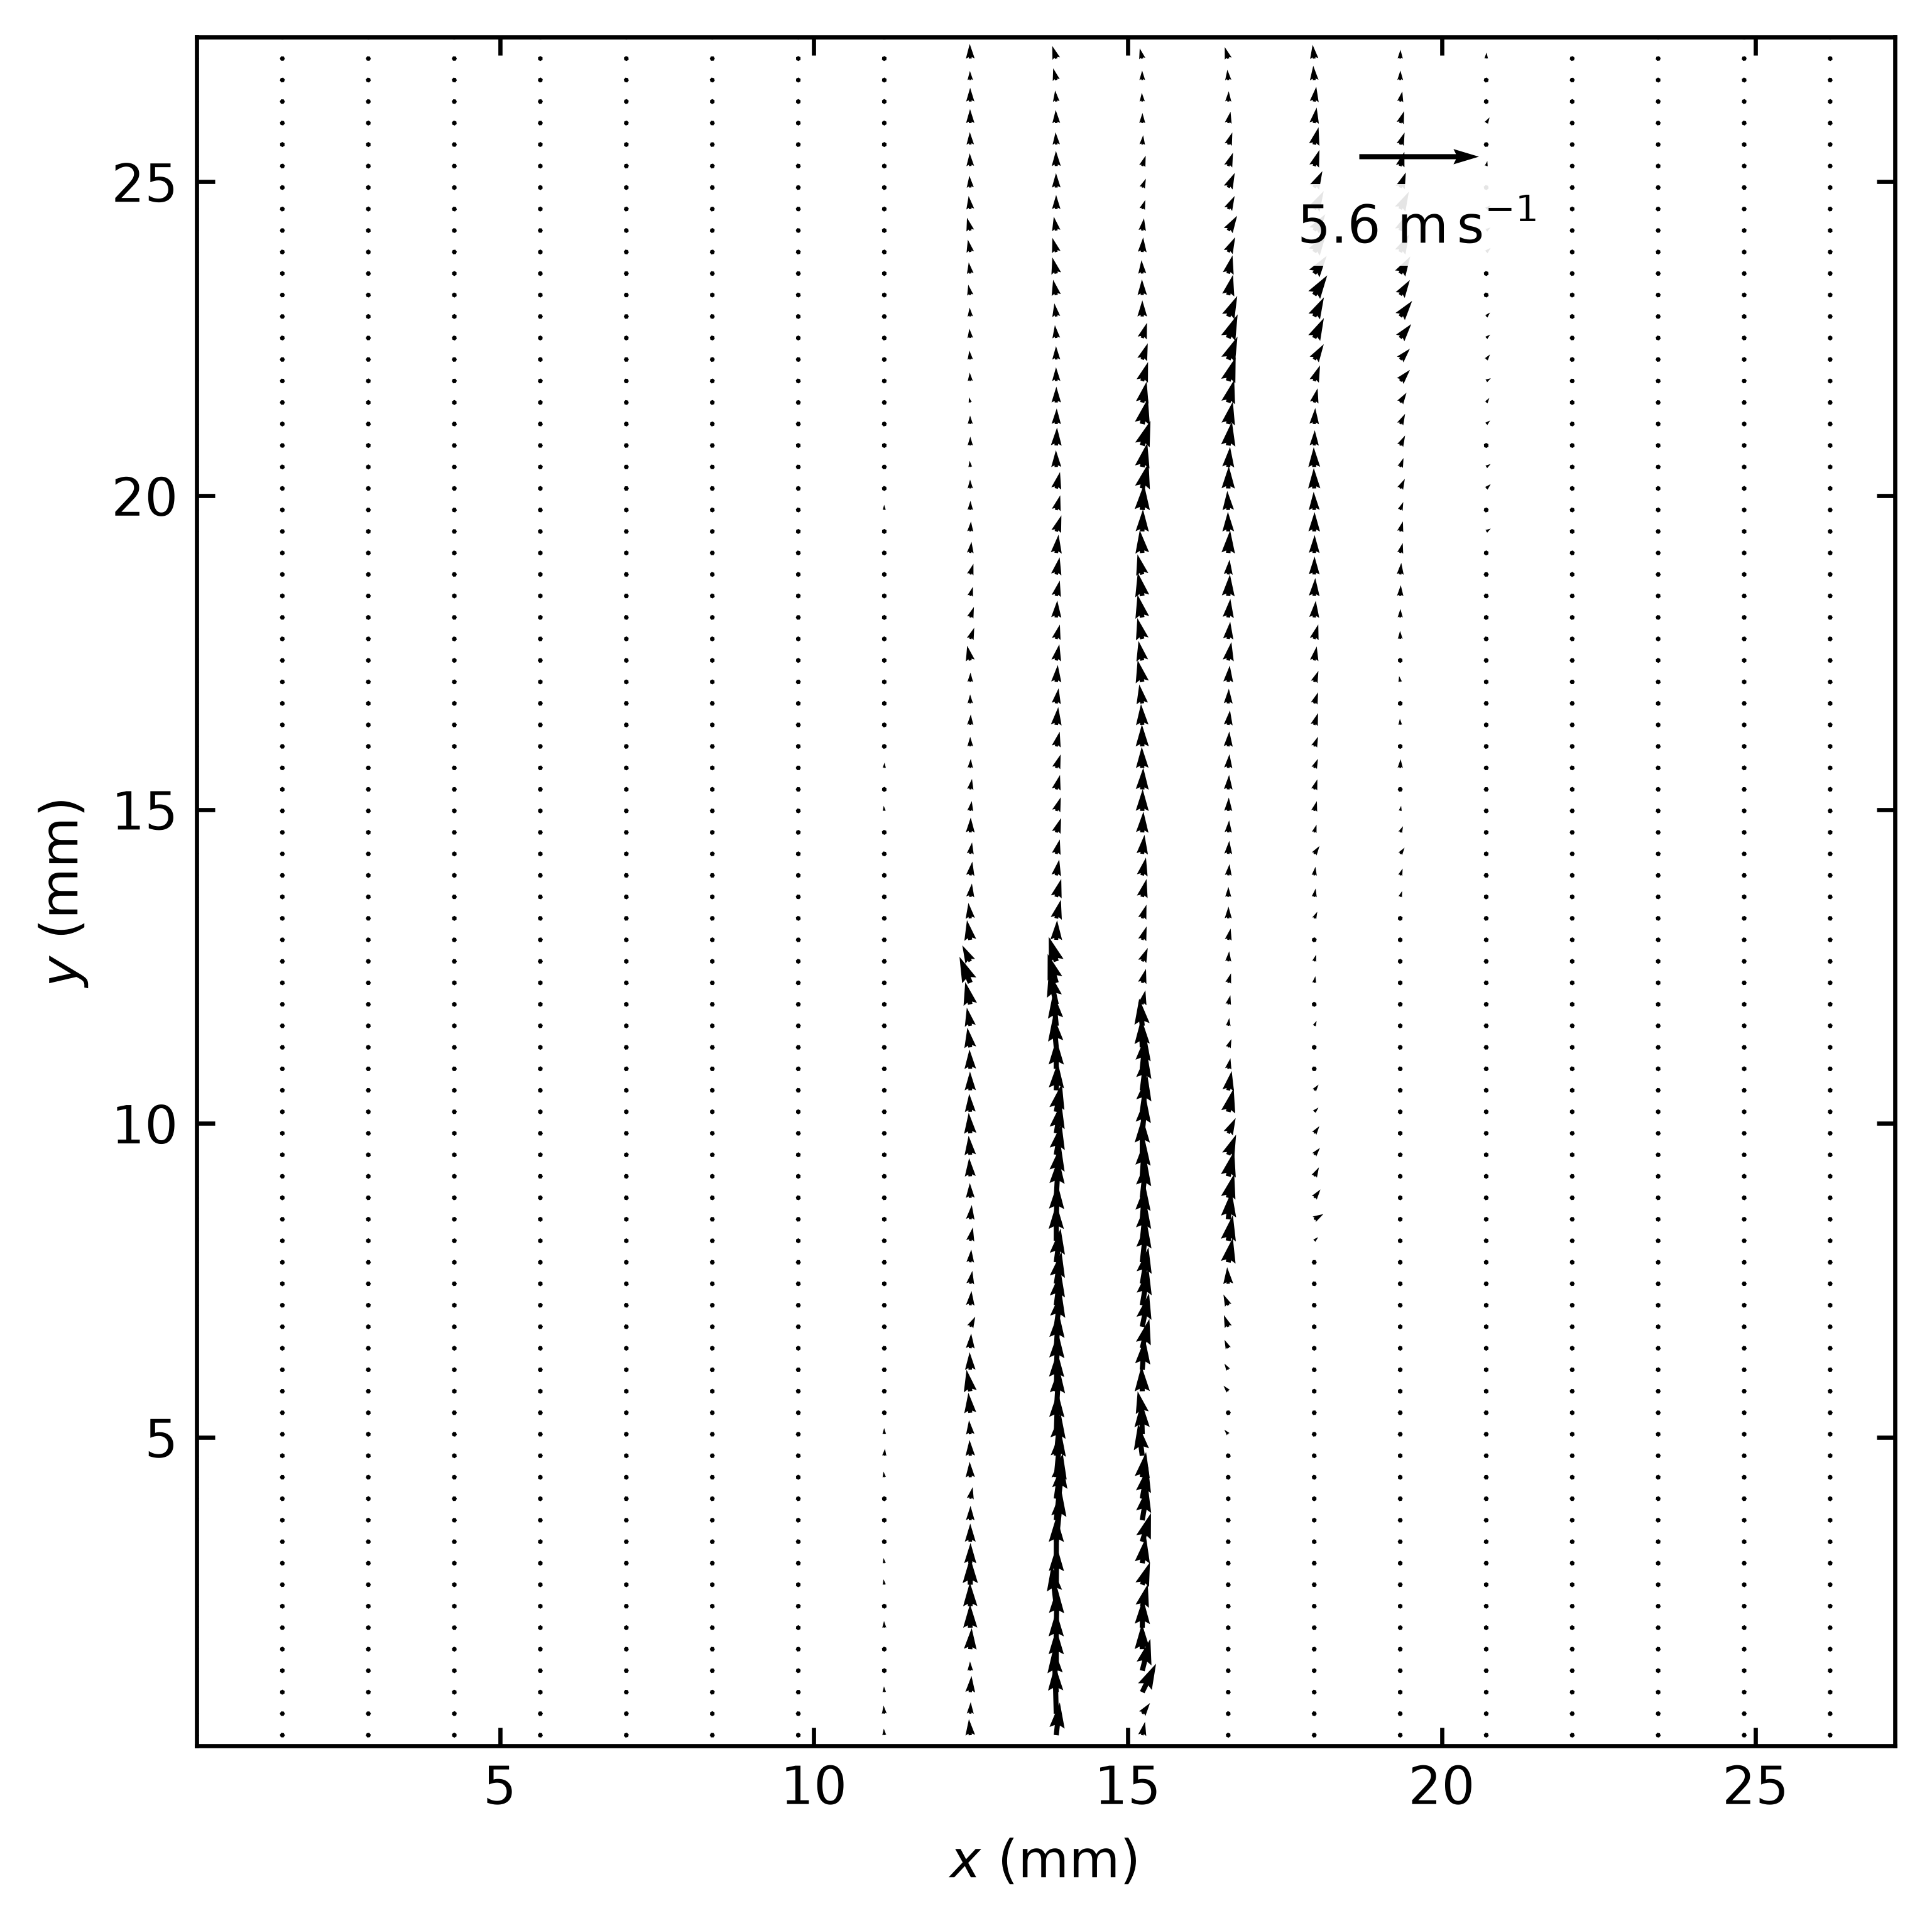

## Supplementary in-plane velocity magnitude

magnitude_mean_vector


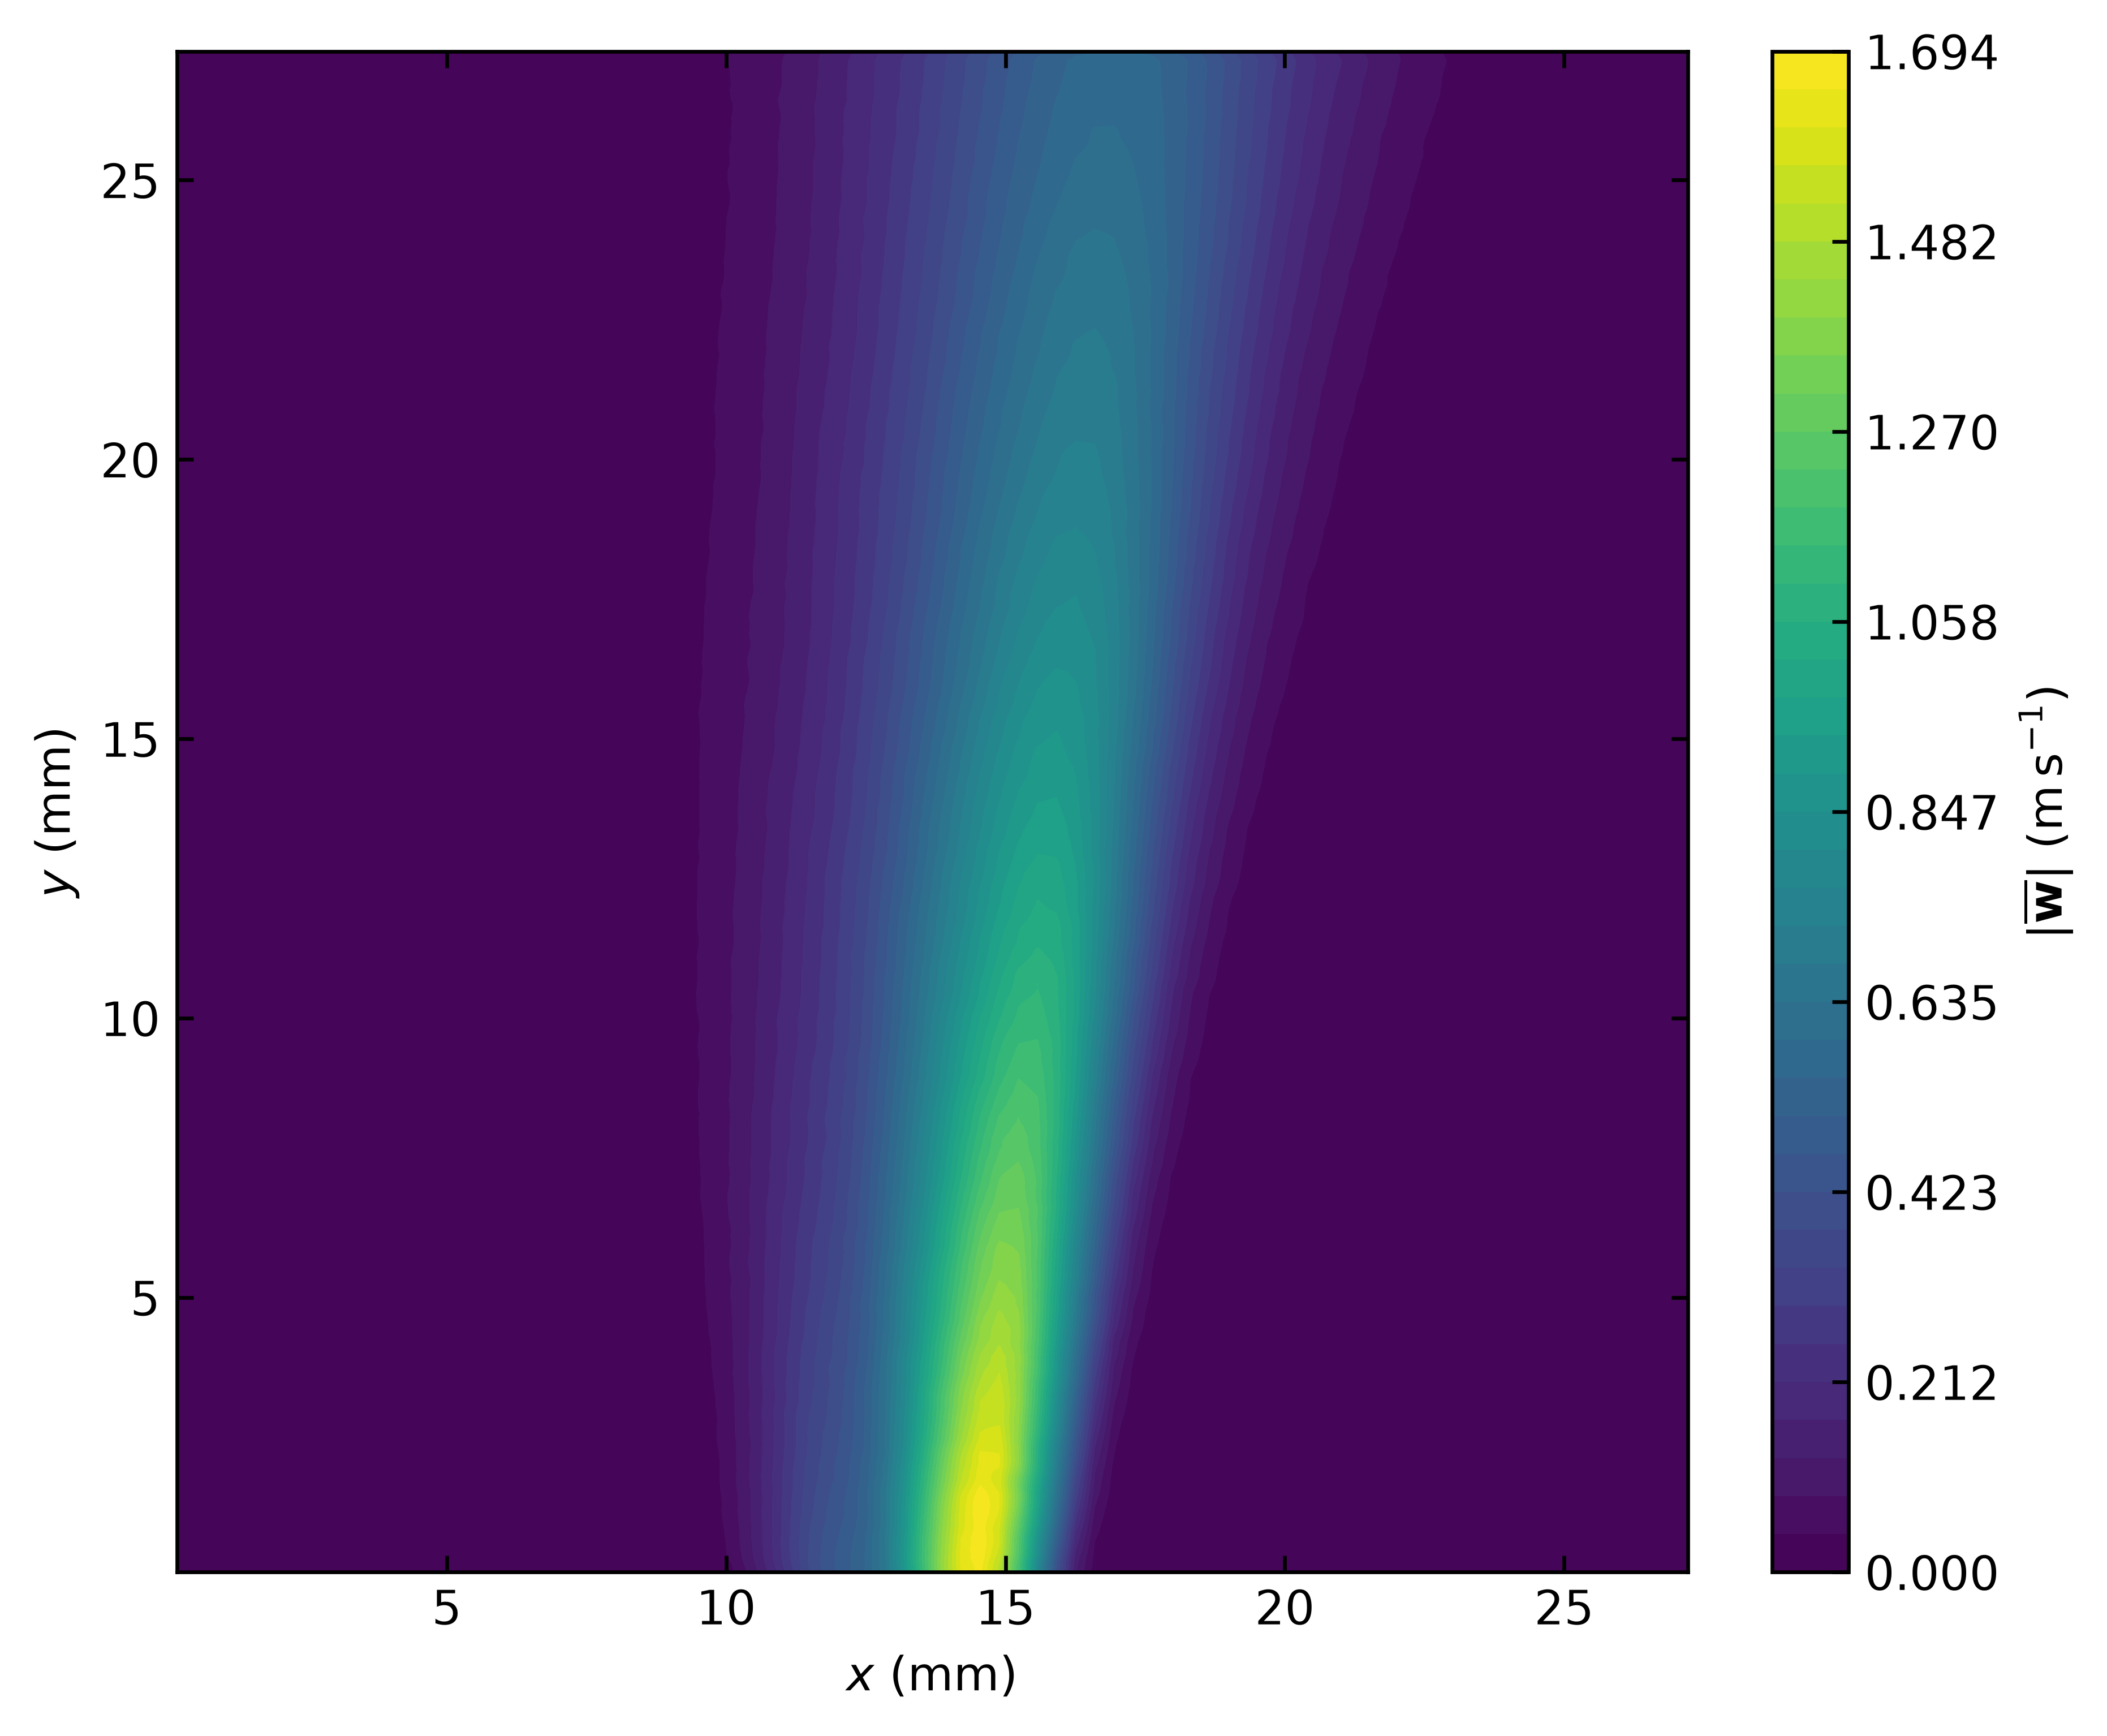

mean_instantaneous_velocity_magnitude


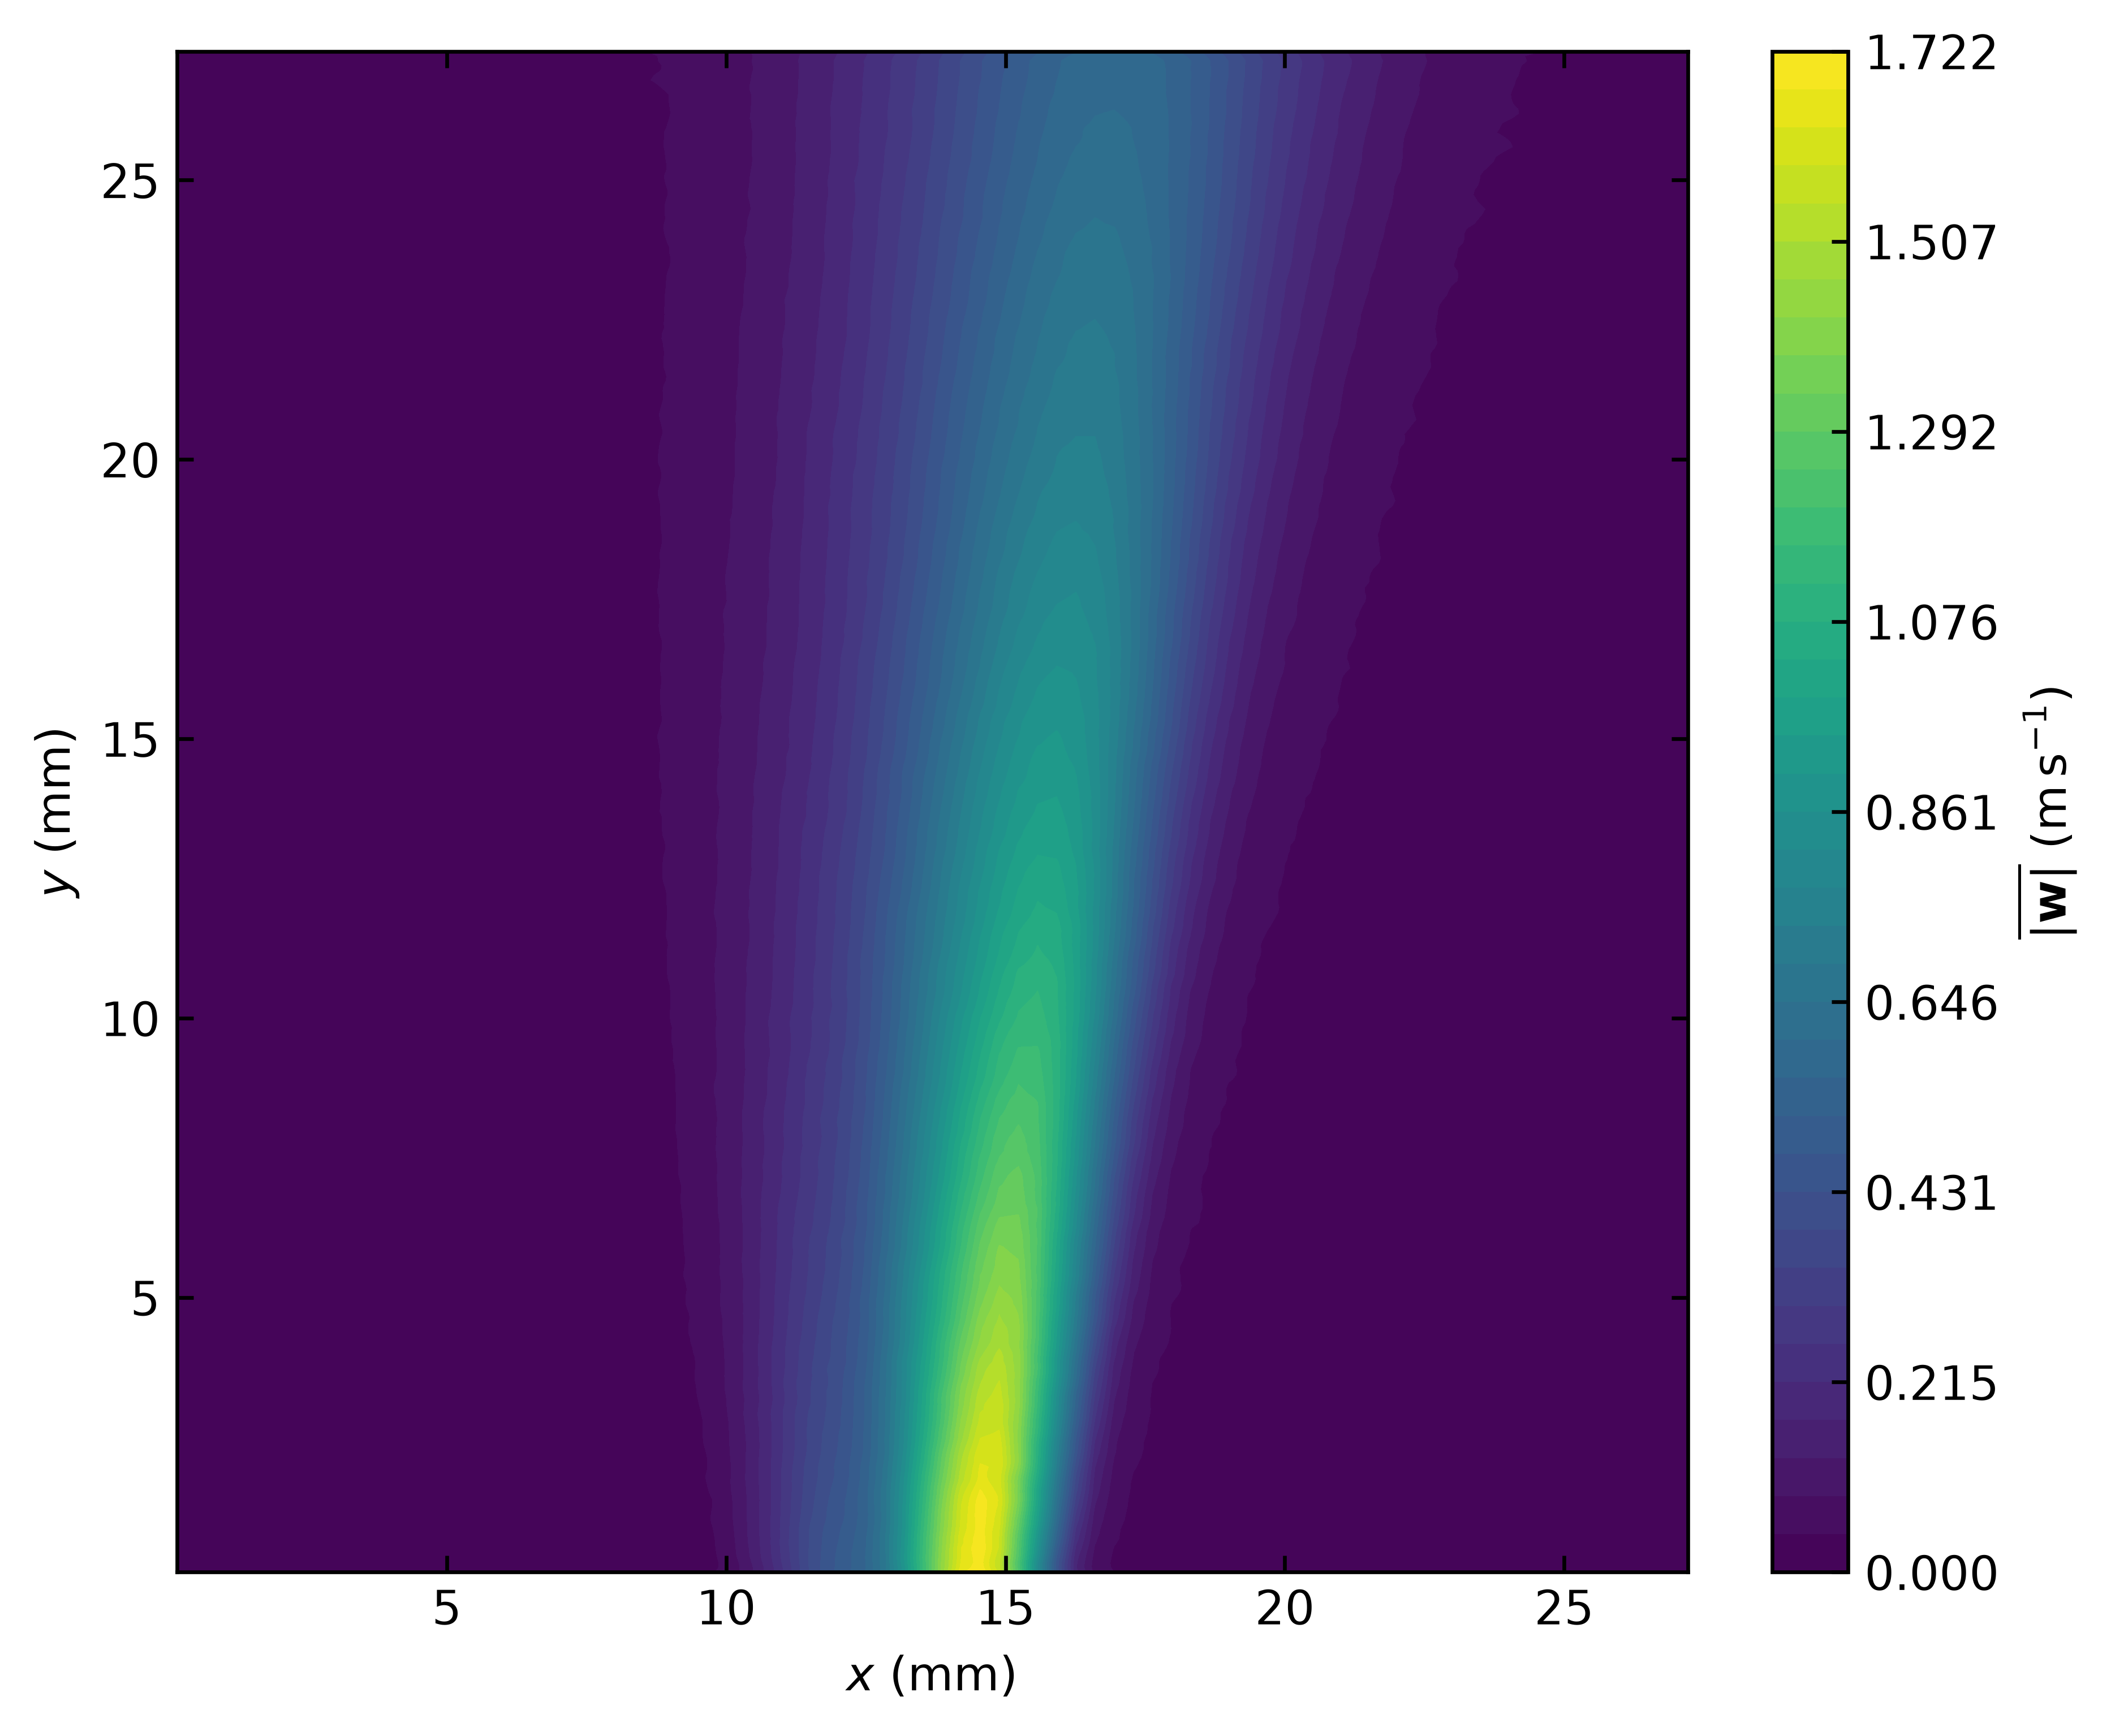

velocity_magnitude_pdf


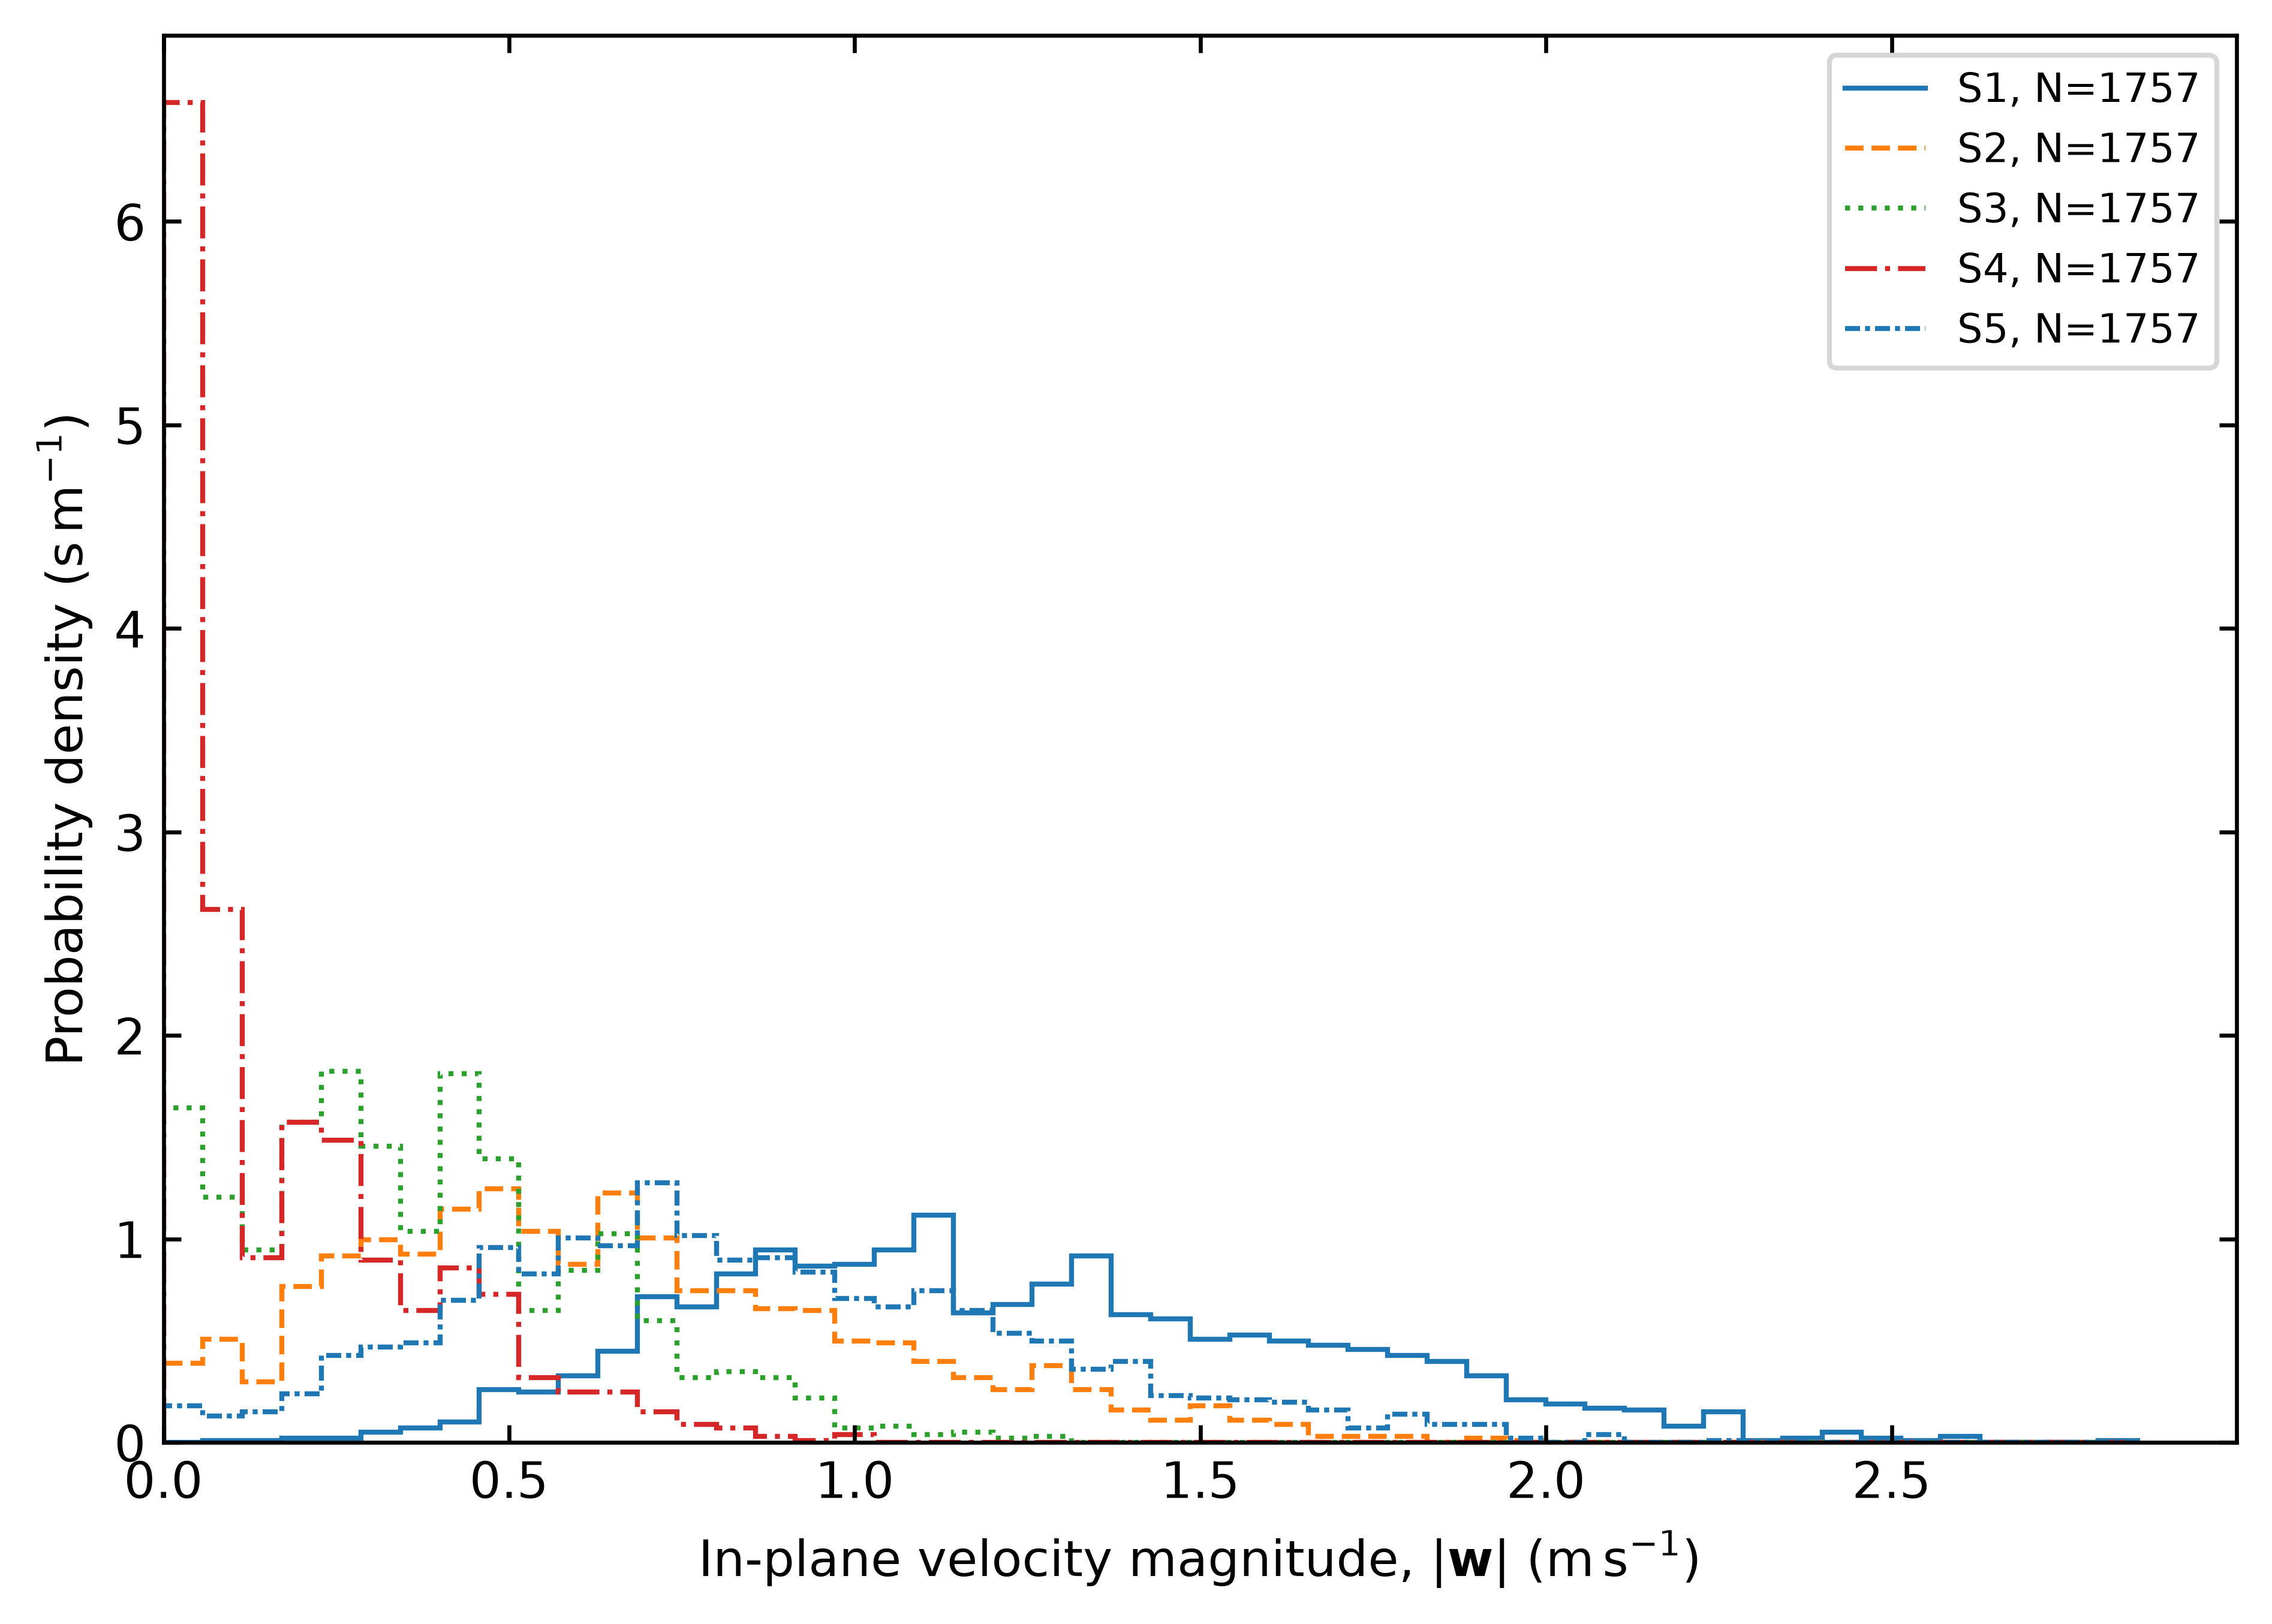

In [3]:
from IPython.display import display,Image,Markdown
display(Markdown((output/'methods/METHODS.md').read_text(encoding='utf-8')))
display(Markdown('## Primary mean-component contours'))
for name in ['mean_v','mean_u']:
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))
display(Markdown('## Component fluctuations, profiles and distributions'))
for name in ['rms_v','rms_u','covariance','correlation','sampling_stations',
             'profile_mean_v','profile_rms_v','profile_rms_u','profile_covariance',
             'v_pdf','u_pdf','v_cdf','u_cdf','frame_879_v','frame_879_u','frame_879_quiver']:
    print(name)
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))
display(Markdown('## Supplementary in-plane velocity magnitude'))
for name in ['magnitude_mean_vector','mean_instantaneous_velocity_magnitude','velocity_magnitude_pdf']:
    print(name)
    display(Image(filename=str(output/'figures'/(name+'.png')),width=600))


In [4]:
print('Measured extrema and display limits are reported separately:')
print((output/'methods/summary.json').read_text())
print((output/'methods/validation.json').read_text())
import csv
with (output/'data/vector_comparison.csv').open() as f: rows=list(csv.DictReader(f))
columns=list(rows[0])
table=[' | '.join(columns),' | '.join(['---']*len(columns))]
table+=[' | '.join(row[c] for c in columns) for row in rows]
display(Markdown(chr(10).join(table)))


Measured extrema and display limits are reported separately:
{
  "mean_axial_velocity_measured_range_m_s": [
    -0.023111475754425344,
    1.6865481421305646
  ],
  "mean_axial_contour_colour_limits_m_s": [
    -1.6865481421305646,
    1.6865481421305646
  ],
  "negative_mean_axial_nodes": 14345,
  "figure_count": 51,
  "publication_figure_count": 37,
  "diagnostic_figure_count": 14,
  "local_N_range": [
    1757,
    1757
  ],
  "selected_frame_keys": [
    "1",
    "879",
    "1757"
  ],
  "observed_grid_node_maximum": {
    "row": 304,
    "column": 42,
    "x_mm": 14.54665,
    "y_mm": 1.284,
    "N": 1757,
    "mean_v_m_s": 1.6865481421305646
  }
}
{
  "calibration_ratio_to_5p05": 1.0594059405940592,
  "calibration_ratio_to_7p25": 0.7379310344827587,
  "scaling_max_absolute_errors": {
    "mean_v": 7.105427357601002e-15,
    "mean_u": 8.604228440844963e-16,
    "rms_v": 1.887379141862766e-15,
    "rms_u": 5.273559366969494e-16,
    "magnitude_mean_vector": 6.8833827526759706e-15,

frame_key | row | column | exported_x | exported_y | x_mm | y_mm | stored_us | stored_vs | u_m_s | v_m_s | flag
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
1 | 287 | 40 | 2591.0 | 512.0 | 13.861849999999999 | 2.7392 | 0.4987640380859375 | 3.8663787841796875 | 0.10673550415039063 | 0.8274050598144531 | 1
1 | 159 | 40 | 2591.0 | 2560.0 | 13.861849999999999 | 13.696 | 1.2717132568359375 | 3.8921127319335938 | 0.2721466369628906 | 0.832912124633789 | 1
1 | 32 | 40 | 2591.0 | 4592.0 | 13.861849999999999 | 24.5672 | 0.582421600818634 | 1.4049326181411743 | 0.12463822257518768 | 0.3006555802822113 | 1
879 | 287 | 40 | 2591.0 | 512.0 | 13.861849999999999 | 2.7392 | 0.093841552734375 | 9.051025390625 | 0.02008209228515625 | 1.93691943359375 | 1
879 | 159 | 40 | 2591.0 | 2560.0 | 13.861849999999999 | 13.696 | 0.9984893798828125 | 3.986347198486328 | 0.21367672729492188 | 0.8530783004760742 | 1
879 | 32 | 40 | 2591.0 | 4592.0 | 13.861849999999999 | 24.5672 | -0.02629205584526062 | 3.080951452255249 | -0.005626499950885773 | 0.6593236107826232 | 1
1757 | 287 | 40 | 2591.0 | 512.0 | 13.861849999999999 | 2.7392 | 0.660736083984375 | 3.685882568359375 | 0.14139752197265626 | 0.7887788696289062 | 1
1757 | 159 | 40 | 2591.0 | 2560.0 | 13.861849999999999 | 13.696 | -0.10408401489257812 | 1.0812339782714844 | -0.022273979187011718 | 0.23138407135009764 | 1
1757 | 32 | 40 | 2591.0 | 4592.0 | 13.861849999999999 | 24.5672 | -0.05423635244369507 | 0.2963275909423828 | -0.011606579422950744 | 0.06341410446166992 | 1

## Reuse

Edit config/analysis.json and rerun. The same command-line entry point calls
the same reusable accumulator and plotting functions. The eight signed
statistics and numerical figure sources are saved separately from their
display masks. See methods/figure_manifest.json for every export/data link,
methods/colour_limits.json for shared limits, and methods/CAPTIONS.md or .tex
for captions. Previous calibrated archives and original HDF5 files are retained.
